
# Taller 2. Clasificación y aprendizaje multimodal con CUB-200-2011

## Deep Learning I - 2026
###Profesor Hector Hortua
###Juan Sebastián Laverde - Claudio de la Rosa


## Contexto

En el primer taller construimos y verificamos los pipelines de datos
multimodales en PyTorch y TensorFlow. Cada observación reunía una
fotografía de un ave, diez descripciones textuales (tomadas de sujetos), 318 características
tabulares y una etiqueta de especie.

En este segundo taller utilizaremos esa preparación anterior para entrenar
modelos y comparar distintas maneras de aprovechar las modalidades.

## Pregunta principal

**¿Qué aporta cada modalidad al problema que estamos intentando solucionar: el reconocimiento de especies de aves, y cómo
cambian los resultados según la forma de combinar la informaci{on disponible o relacionarla?**

## Objetivo general

Entrenar y evaluar modelos unimodales y multimodales con CUB-200-2011, de acuardo al taller de la materia Deep Learning I,
comparando clasificación supervisada, asi como la fusión de modalidades y aprendizaje
de representaciones para especies de aves no vistas durante el entrenamiento.

## Organización del trabajo

1. Recuperación y verificación de los datos preparados.
2. Extracción de los embeddings visuales con un "backbone" ya preentrenado
   y congelado.
3. Clasificadores unimodales de imagen, texto y atributos.
4. Fusión de representaciones: early fusion o fusión intermedia.
5. Fusión de predicciones: late fusion, ablación y robustez.
6. Red siamesa para comparación y recuperación de imágenes.
7. Modelo tipo CLIP para relacionar imágenes y descripciones.
8. Comparación de resultados y discusión de sus limitaciones.

## Relación con el ejercicio de clase

Utilizaremos como referencia el notebook del profesor sobre aprendizaje
multimodal con MNIST y dígitos hablados:

[Notebook de referencia: multimodal_mnist.ipynb](https://github.com/MAESTRiA-ESTADiS-CIENCIA-DATOS-Bosque/Deep_Learning_I_Fundamentos/blob/main/clase4/multimodal_mnist.ipynb)

Conservaremos, cuando corresponda, su organización mediante funciones
para construir modelos, configuración con compile(), entrenamiento con
fit(), callbacks, curvas de aprendizaje y evaluación de las reglas de
fusión.

Adaptaremos la modalidad de audio a descripciones textuales e
incorporaremos una tercera modalidad tabular. Las secciones de fusión
intermedia y red siamesa se desarrollarán según el enunciado del taller.

## Framework

Trabajaremos con TensorFlow/Keras y reutilizaremos la preparación común
del primer taller.

## Criterios metodológicos

- Mantener la correspondencia entre imágenes, descripciones y atributos.
- Ajustar vocabularios y escaladores únicamente con los datos de
  entrenamiento correspondientes a cada protocolo.
- Utilizar validación para seleccionar configuraciones y reservar prueba
  para la evaluación final de cada experimento.
- Diferenciar las particiones de clasificación supervisada de las
  particiones por especie utilizadas en aprendizaje métrico y zero-shot.
- Mantener congelado el backbone visual durante la extracción de
  embeddings.
- Entrenar los encoders textuales desde cero mediante Embedding y
  LSTM o BiLSTM, sin modelos de lenguaje preentrenados.
- Explicar las decisiones y conservar visibles las salidas del notebook.

## Enunciado

[Tarea 2: Fusión multimodal, red siamesa y CLIP](https://github.com/MAESTRiA-ESTADiS-CIENCIA-DATOS-Bosque/Deep_Learning_I_Fundamentos/blob/main/tareas/Tarea_modelos_multimodal_CUB-200-2011.md)

## Entrega

Notebook ejecutado y su versión PDF, con código, resultados, figuras
y explicaciones de las decisiones tomadas.




## 1. Configuración del entorno

Importamos las librerías y fijamos las semillas para facilitar la
reproducción de los experimentos bajo las mismas condiciones de ejecución.

Siguiendo el notebook de referencia, utilizamos TensorFlow/Keras,
NumPy y Matplotlib. También comprobamos la disponibilidad de una GPU.

Esta celda no carga los datos ni entrena modelos. Las semillas no
garantizan resultados idénticos entre equipos, versiones de librerías
o todas las operaciones ejecutadas en GPU.

In [ ]:
# ------------------------------------------------------------
# 1. IMPORTAR LAS LIBRERÍAS
# ------------------------------------------------------------
from pathlib import Path
import random
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers


# ------------------------------------------------------------
# 2. FIJAR LAS SEMILLAS
# ------------------------------------------------------------
# Esta función fija las semillas de Python, NumPy y TensorFlow.
# Utilizamos 42, como en el ejercicio del profesor.
SEED = 42
tf.keras.utils.set_random_seed(SEED)


# ------------------------------------------------------------
# 3. MOSTRAR LAS VERSIONES
# ------------------------------------------------------------
# Registrar las versiones ayuda a documentar el entorno
# en el que se obtuvieron los resultados.
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


# ------------------------------------------------------------
# 4. COMPROBAR LA DISPONIBILIDAD DE GPU
# ------------------------------------------------------------
gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print(f"\nGPU disponibles: {len(gpus)}")

    for gpu in gpus:
        print("Dispositivo:", gpu.name)

        # Solicitar que TensorFlow reserve memoria gradualmente.
        # Debe configurarse antes de inicializar la GPU.
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as error:
            print("No se pudo ajustar el crecimiento de memoria:", error)
else:
    print("\nNo se detectó una GPU. El entorno utilizará CPU.")


# ------------------------------------------------------------
# 5. DEFINIR EL PARALELISMO DEL PIPELINE
# ------------------------------------------------------------
# Como en el notebook de referencia, AUTOTUNE permitirá
# ajustar el procesamiento paralelo y la precarga de datos.
AUTOTUNE = tf.data.AUTOTUNE

print("\nEntorno inicial configurado.")

TensorFlow: 2.21.0
NumPy: 2.1.3
Pandas: 2.2.3

GPU disponibles: 1
Dispositivo: /physical_device:GPU:0

Entorno inicial configurado.



## 2. Recuperación de los datos preparados

Recuperamos las particiones y la configuración exportadas en el primer
taller: train.npz, val.npz, test.npz, metadata.json y geometry_scaler.npz.

Los archivos contienen textos codificados, longitudes, atributos,
etiquetas y cajas delimitadoras. Las fotografías se cargarán por
separado, utilizando las rutas relativas guardadas.

Primero comprobamos la ubicación de los archivos. Todavía no cargamos
las fotografías ni construimos modelos.


In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR LAS UBICACIONES ESPERADAS
# ------------------------------------------------------------
import zipfile

PREPARED_DIR = Path("/content/content/cub_prepared")
PREPARED_ZIP = Path("/content/content/cub_prepared_export.zip")


# ------------------------------------------------------------
# 2. EXTRAER EL ZIP SI ESTÁ DISPONIBLE
# ------------------------------------------------------------
# El ZIP exportado en el primer taller contiene una carpeta
# principal llamada cub_prepared.
if not PREPARED_DIR.is_dir() and PREPARED_ZIP.is_file():
    with zipfile.ZipFile(PREPARED_ZIP) as archive:
        # Comprobar integridad antes de extraer.
        damaged_file = archive.testzip()

        if damaged_file is not None:
            raise ValueError(f"Archivo dañado: {damaged_file}")

        archive.extractall("/content")

    print("Carpeta de datos preparados extraída.")


# ------------------------------------------------------------
# 3. COMPROBAR LOS ARCHIVOS NECESARIOS
# ------------------------------------------------------------
required_files = [
    "train.npz",
    "val.npz",
    "test.npz",
    "metadata.json",
    "geometry_scaler.npz",
]

missing = [
    name
    for name in required_files
    if not (PREPARED_DIR / name).is_file()
]

if missing:
    raise FileNotFoundError(
        f"Faltan archivos en {PREPARED_DIR}: {missing}. "
        "Sube la carpeta cub_prepared o cub_prepared_export.zip."
    )


# ------------------------------------------------------------
# 4. MOSTRAR LOS ARCHIVOS ENCONTRADOS
# ------------------------------------------------------------
for name in required_files:
    path = PREPARED_DIR / name

    print(
        f"{name}: "
        f"{path.stat().st_size / 1024**2:.2f} MiB"
    )

print("\nArchivos preparados disponibles.")

train.npz: 1.19 MiB
val.npz: 0.15 MiB
test.npz: 1.27 MiB
metadata.json: 0.05 MiB
geometry_scaler.npz: 0.00 MiB

Archivos preparados disponibles.


## 3. Carga y verificación de los datos preparados

Cargamos las particiones exportadas en el primer taller, conservando
sus asignaciones de entrenamiento, validación y prueba.

También recuperamos el vocabulario, la longitud máxima del texto y
el orden de las características tabulares. Estas últimas ya contienen
las seis variables geométricas estandarizadas; no debemos escalarlas
nuevamente.

En este paso no abrimos las fotografías. Solo recuperamos sus rutas
relativas y los arreglos numéricos asociados.

In [ ]:
import json
import numpy as np

# ------------------------------------------------------------
# 1. RECUPERAR LA CONFIGURACIÓN DEL PRIMER TALLER
# ------------------------------------------------------------
metadata = json.loads(
    (PREPARED_DIR / "metadata.json").read_text(encoding="utf-8")
)

vocab = metadata["vocab"]
max_len = int(metadata["max_len"])
tabular_columns = metadata["tabular_columns"]

# Correspondencia inversa para interpretar los textos codificados.
id_to_word = {
    int(index): word
    for word, index in vocab.items()
}

# JSON guarda las claves de los nombres de especie como texto.
# Las convertimos nuevamente a enteros.
class_names = {
    int(label): name
    for label, name in metadata["class_names"].items()
}

NUM_CLASSES = len(class_names)
VOCAB_SIZE = len(vocab)


# ------------------------------------------------------------
# 2. DEFINIR LA CARGA DE UNA PARTICIÓN
# ------------------------------------------------------------
def load_prepared_split(name):
    # Copiamos los arreglos al diccionario antes de cerrar el NPZ.
    # allow_pickle=False evita depender de objetos serializados.
    with np.load(
        PREPARED_DIR / f"{name}.npz",
        allow_pickle=False,
    ) as archive:
        return {
            key: archive[key]
            for key in archive.files
        }


# ------------------------------------------------------------
# 3. CARGAR LAS TRES PARTICIONES
# ------------------------------------------------------------
prepared = {
    name: load_prepared_split(name)
    for name in ["train", "val", "test"]
}


# ------------------------------------------------------------
# 4. VERIFICAR LAS DIMENSIONES Y VALORES
# ------------------------------------------------------------
expected_sizes = {
    "train": 5_394,
    "val": 600,
    "test": 5_794,
}

assert vocab["<pad>"] == 0
assert vocab["<unk>"] == 1
assert NUM_CLASSES == 200
assert len(tabular_columns) == 318

for name, data in prepared.items():
    n = expected_sizes[name]

    # Cada arreglo debe contener las mismas observaciones.
    assert data["image_ids"].shape == (n,)
    assert data["image_paths"].shape == (n,)
    assert data["boxes"].shape == (n, 4)
    assert data["caption_ids"].shape == (n, 10, max_len)
    assert data["caption_lengths"].shape == (n, 10)
    assert data["tabular"].shape == (n, 318)
    assert data["labels"].shape == (n,)

    # Comprobar identificadores únicos dentro de la partición.
    assert len(np.unique(data["image_ids"])) == n

    # Comprobar valores numéricos.
    assert np.isfinite(data["boxes"]).all()
    assert (data["boxes"][:, 2:] > 0).all()
    assert np.isfinite(data["tabular"]).all()
    assert np.isin(data["tabular"][:, :312], [0, 1]).all()

    assert (
        (data["labels"] >= 0)
        & (data["labels"] < NUM_CLASSES)
    ).all()

    assert (
        (data["caption_ids"] >= 0)
        & (data["caption_ids"] < VOCAB_SIZE)
    ).all()

    assert (
        (data["caption_lengths"] >= 1)
        & (data["caption_lengths"] <= max_len)
    ).all()

    print(
        f"✓ {name}: {n:,} observaciones | "
        f"textos {data['caption_ids'].shape} | "
        f"tabular {data['tabular'].shape}"
    )


# ------------------------------------------------------------
# 5. COMPROBAR QUE NO SE COMPARTAN IMÁGENES ENTRE PARTICIONES
# ------------------------------------------------------------
train_ids = set(prepared["train"]["image_ids"].tolist())
val_ids = set(prepared["val"]["image_ids"].tolist())
test_ids = set(prepared["test"]["image_ids"].tolist())

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("\n✓ No hay identificadores de imagen compartidos.")
print("Vocabulario:", VOCAB_SIZE)
print("Longitud máxima:", max_len)
print("Especies:", NUM_CLASSES)


# ------------------------------------------------------------
# 6. INTERPRETAR UNA DESCRIPCIÓN DE ENTRENAMIENTO
# ------------------------------------------------------------
example = prepared["train"]
length = int(example["caption_lengths"][0, 0])
ids = example["caption_ids"][0, 0, :length]
label = int(example["labels"][0])

print("\nPrimera imagen:", example["image_paths"][0])
print("Especie:", class_names[label])
print("Primera descripción codificada:")
print(" ".join(id_to_word[int(index)] for index in ids))

✓ train: 5,394 observaciones | textos (5394, 10, 25) | tabular (5394, 318)
✓ val: 600 observaciones | textos (600, 10, 25) | tabular (600, 318)
✓ test: 5,794 observaciones | textos (5794, 10, 25) | tabular (5794, 318)

✓ No hay identificadores de imagen compartidos.
Vocabulario: 2079
Longitud máxima: 25
Especies: 200

Primera imagen: 001.Black_footed_Albatross/Black_Footed_Albatross_0009_34.jpg
Especie: 001.Black_footed_Albatross
Primera descripción codificada:
the wings are brown long and narrow and have white markings on the secondaries the bill is blunt tipped and black the head is light


## 4. Localización de las fotografías originales

En el ejercicio de clase, la carga de MNIST proporciona directamente
las imágenes. En nuestro caso, los archivos preparados contienen rutas
relativas, por lo que necesitamos localizar la carpeta original de CUB.

Antes de extraer embeddings, comprobaremos que las fotografías de las
tres particiones estén disponibles. Esta comprobación verifica su
existencia, pero todavía no abre ni transforma las imágenes.


In [ ]:
from pathlib import Path
import subprocess
import hashlib

# ------------------------------------------------------------
# 1. DEFINIR EL DESTINO Y EL ENLACE OFICIAL
# ------------------------------------------------------------
DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

CUB_ARCHIVE = DATA_DIR / "CUB_200_2011.tgz"

DOWNLOAD_URL = (
    "https://data.caltech.edu/records/65de6-vp158/"
    "files/CUB_200_2011.tgz?download=1"
)


# ------------------------------------------------------------
# 2. DESCARGAR EL ARCHIVO
# ------------------------------------------------------------
# -L sigue las redirecciones de Caltech.
# --fail informa errores HTTP.
# La descarga sustituye cualquier copia previa en esta ruta.
print("Descargando imágenes y anotaciones de CUB…")

subprocess.run(
    [
        "curl",
        "-L",
        "--fail",
        "--retry", "3",
        "--output", str(CUB_ARCHIVE),
        DOWNLOAD_URL,
    ],
    check=True,
)

print(f"\nTamaño descargado: {CUB_ARCHIVE.stat().st_size / 1024**3:.3f} GiB")


# ------------------------------------------------------------
# 3. COMPROBAR LA INTEGRIDAD CON EL CHECKSUM OFICIAL
# ------------------------------------------------------------
# Leemos por bloques para no cargar el archivo entero en RAM.
# El checksum permite detectar descargas incompletas o alteradas.
expected_md5 = "97eceeb196236b17998738112f37df78"
checksum = hashlib.md5()

with CUB_ARCHIVE.open("rb") as file:
    for block in iter(lambda: file.read(1024 * 1024), b""):
        checksum.update(block)

actual_md5 = checksum.hexdigest()

if actual_md5 != expected_md5:
    raise ValueError(
        "La descarga no coincide con el archivo oficial.\n"
        f"MD5 obtenido: {actual_md5}"
    )

print("✓ Descarga completa: checksum oficial verificado.")

Descargando imágenes y anotaciones de CUB…

Tamaño descargado: 1.072 GiB
✓ Descarga completa: checksum oficial verificado.


## Extracción y verificación de las fotografías

Extraemos el archivo original de CUB-200-2011 y comprobamos que cada
ruta guardada en los datos preparados corresponda a una fotografía
disponible.

Esta operación no modifica las particiones, el vocabulario ni las
características tabulares. Todavía no aplicamos transformaciones
ni calculamos embeddings.


In [ ]:
# ------------------------------------------------------------
# 1. EXTRAER EL ARCHIVO VERIFICADO
# ------------------------------------------------------------
print("Extrayendo imágenes y anotaciones…")

result = subprocess.run(
    ["tar", "-xzf", str(CUB_ARCHIVE), "-C", str(DATA_DIR)],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.PIPE,
    text=True,
)

if result.returncode != 0:
    raise RuntimeError(
        f"Error durante la extracción:\n{result.stderr}"
    )


# ------------------------------------------------------------
# 2. DEFINIR LA CARPETA DE IMÁGENES
# ------------------------------------------------------------
IMAGES_DIR = DATA_DIR / "CUB_200_2011" / "images"

if not IMAGES_DIR.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta esperada: {IMAGES_DIR}"
    )

print("Carpeta de imágenes:", IMAGES_DIR)


# ------------------------------------------------------------
# 3. COMPROBAR LAS RUTAS DE CADA PARTICIÓN
# ------------------------------------------------------------
# Los archivos NPZ conservan rutas relativas.
# Las combinamos con IMAGES_DIR para localizar las fotografías.
for split, data in prepared.items():

    missing = [
        str(relative_path)
        for relative_path in data["image_paths"]
        if not (IMAGES_DIR / str(relative_path)).is_file()
    ]

    if missing:
        raise FileNotFoundError(
            f"{split}: faltan {len(missing)} fotografías. "
            f"Ejemplos: {missing[:3]}"
        )

    print(
        f"✓ {split}: "
        f"{len(data['image_paths']):,} fotografías disponibles."
    )

print("\n✓ Extracción y verificación de rutas completadas.")

Extrayendo imágenes y anotaciones…
Carpeta de imágenes: /content/data/CUB_200_2011/images
✓ train: 5,394 fotografías disponibles.
✓ val: 600 fotografías disponibles.
✓ test: 5,794 fotografías disponibles.

✓ Extracción y verificación de rutas completadas.


## 5. Preparación de imágenes para la extracción de embeddings

Definimos una función que carga cada fotografía, recorta la caja
delimitadora con el margen documentado en el primer taller,
redimensiona a 256 × 256 y obtiene un recorte central de 224 × 224.

Después aplicamos el preprocesamiento de ResNet50 de Keras.
Este recibe valores en escala 0–255, cambia el orden de canales de
RGB a BGR y resta las medias utilizadas por el modelo preentrenado.

Esta normalización sustituye, para este backbone, la normalización
del primer taller. No deben aplicarse ambas.

La extracción inicial será determinista: guardaremos un embedding
por imagen, sin aumentaciones aleatorias. Esto reduce el costo de
entrenamiento posterior, aunque limita la variación visual disponible.


In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input

# ------------------------------------------------------------
# 1. RECUPERAR EL MARGEN DOCUMENTADO
# ------------------------------------------------------------
# En el primer taller se añadió el 10 % del ancho y del alto
# de la caja a cada lado, limitado por los bordes de la imagen.
BBOX_MARGIN = float(metadata["bbox_margin_per_side"])


# ------------------------------------------------------------
# 2. DEFINIR LA PREPARACIÓN DE UNA FOTOGRAFÍA
# ------------------------------------------------------------
def preprocess_for_resnet(image_path, bbox):

    # Leer y decodificar la fotografía en RGB.
    image_bytes = tf.io.read_file(image_path)
    image = tf.io.decode_jpeg(image_bytes, channels=3)

    image_height = tf.shape(image)[0]
    image_width = tf.shape(image)[1]

    # La caja contiene x, y, ancho y alto en píxeles originales.
    x, y, w, h = tf.unstack(bbox)

    # --------------------------------------------------------
    # 2A. CALCULAR LA CAJA AMPLIADA
    # --------------------------------------------------------
    left = tf.maximum(
        0,
        tf.cast(tf.floor(x - BBOX_MARGIN * w), tf.int32),
    )
    top = tf.maximum(
        0,
        tf.cast(tf.floor(y - BBOX_MARGIN * h), tf.int32),
    )
    right = tf.minimum(
        image_width,
        tf.cast(tf.math.ceil(x + w + BBOX_MARGIN * w), tf.int32),
    )
    bottom = tf.minimum(
        image_height,
        tf.cast(tf.math.ceil(y + h + BBOX_MARGIN * h), tf.int32),
    )

    tf.debugging.assert_greater(right, left)
    tf.debugging.assert_greater(bottom, top)

    # --------------------------------------------------------
    # 2B. RECORTAR Y REDIMENSIONAR
    # --------------------------------------------------------
    image = tf.image.crop_to_bounding_box(
        image,
        offset_height=top,
        offset_width=left,
        target_height=bottom - top,
        target_width=right - left,
    )

    # Convertimos a float32 conservando la escala 0–255.
    # No dividimos entre 255.
    image = tf.cast(image, tf.float32)

    image = tf.image.resize(
        image,
        size=[256, 256],
        method="bilinear",
        antialias=True,
    )

    # Obtener un recorte central de 224 × 224.
    image = tf.image.crop_to_bounding_box(
        image,
        offset_height=16,
        offset_width=16,
        target_height=224,
        target_width=224,
    )

    # --------------------------------------------------------
    # 2C. APLICAR EL PREPROCESAMIENTO DEL BACKBONE
    # --------------------------------------------------------
    image = preprocess_input(image)

    return tf.ensure_shape(image, [224, 224, 3])


print("Preprocesamiento para ResNet50 definido.")
print("Margen por lado:", BBOX_MARGIN)

Preprocesamiento para ResNet50 definido.
Margen por lado: 0.1


## 6. Construcción y comprobación del backbone visual

Cargamos ResNet50 con pesos preentrenados en ImageNet, sin su capa
original de clasificación. Utilizamos promedio global para obtener
un vector de 2.048 características por fotografía.

Congelamos sus parámetros: durante esta etapa no entrenamos ResNet50,
solo la utilizamos como extractor de características.

Antes de procesar todo el dataset, comprobamos la salida con una
fotografía de entrenamiento.

In [ ]:
from tensorflow.keras.applications import ResNet50

# ------------------------------------------------------------
# 1. CARGAR EL BACKBONE PREENTRENADO
# ------------------------------------------------------------
# include_top=False elimina el clasificador original de ImageNet.
# pooling="avg" convierte los mapas finales en un vector de 2048.
# Los pesos se descargan si no están disponibles en la sesión.
image_backbone = ResNet50(
    weights="imagenet",
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3),
)


# ------------------------------------------------------------
# 2. CONGELAR SUS PARÁMETROS
# ------------------------------------------------------------
# ResNet50 actuará como extractor fijo.
image_backbone.trainable = False

print("Forma de entrada:", image_backbone.input_shape)
print("Forma de salida:", image_backbone.output_shape)
print("Parámetros entrenables:", len(image_backbone.trainable_weights))


# ------------------------------------------------------------
# 3. PREPARAR UNA IMAGEN DE ENTRENAMIENTO
# ------------------------------------------------------------
example_data = prepared["train"]

example_path = str(
    IMAGES_DIR / str(example_data["image_paths"][0])
)

example_bbox = tf.convert_to_tensor(
    example_data["boxes"][0],
    dtype=tf.float32,
)

example_image = preprocess_for_resnet(
    tf.constant(example_path),
    example_bbox,
)

# Añadimos la dimensión de lote:
# (224, 224, 3) → (1, 224, 224, 3).
example_batch = tf.expand_dims(example_image, axis=0)


# ------------------------------------------------------------
# 4. EXTRAER EL EMBEDDING
# ------------------------------------------------------------
# training=False mantiene el comportamiento de inferencia,
# incluidas las capas BatchNormalization del backbone.
example_embedding = image_backbone(
    example_batch,
    training=False,
)


# ------------------------------------------------------------
# 5. VERIFICAR EL RESULTADO
# ------------------------------------------------------------
assert tuple(example_embedding.shape) == (1, 2048)

tf.debugging.assert_all_finite(
    example_embedding,
    "El embedding contiene valores NaN o infinitos.",
)

print("\nImagen procesada:", example_data["image_paths"][0])
print("Forma del embedding:", tuple(example_embedding.shape))
print("Tipo:", example_embedding.dtype.name)
print("✓ Backbone comprobado.")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Forma de entrada: (None, 224, 224, 3)
Forma de salida: (None, 2048)
Parámetros entrenables: 0

Imagen procesada: 001.Black_footed_Albatross/Black_Footed_Albatross_0009_34.jpg
Forma del embedding: (1, 2048)
Tipo: float32
✓ Backbone comprobado.


## 7. Extracción y almacenamiento de embeddings visuales

Procesamos las fotografías por lotes mediante ResNet50 congelada.
Cada imagen se representa mediante un vector de 2.048 características.

Conservamos el orden de las particiones y guardamos los identificadores
de imagen junto con los embeddings. Esto permite comprobar su
correspondencia con las demás modalidades.

La operación es una extracción de características, no un entrenamiento.
Los archivos se guardan inicialmente en el almacenamiento temporal
de Colab y deberán descargarse para conservarlos entre sesiones.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR LA CONFIGURACIÓN DE EXTRACCIÓN
# ------------------------------------------------------------
EMBED_BATCH_SIZE = 32

EMBEDDINGS_DIR = PREPARED_DIR / "resnet50_embeddings"
EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. CONSTRUIR EL PIPELINE VISUAL DE UNA PARTICIÓN
# ------------------------------------------------------------
def build_embedding_dataset(data):

    # Mantener exactamente el orden de los arreglos preparados.
    paths = np.asarray(
        [
            str(IMAGES_DIR / str(relative_path))
            for relative_path in data["image_paths"]
        ],
        dtype=str,
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, data["boxes"])
    )

    # Cada ruta y caja se convierten en una imagen preprocesada.
    dataset = dataset.map(
        preprocess_for_resnet,
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )

    # Conservamos el último lote aunque esté incompleto.
    dataset = dataset.batch(
        EMBED_BATCH_SIZE,
        drop_remainder=False,
    )

    return dataset.prefetch(AUTOTUNE)


# ------------------------------------------------------------
# 3. EXTRAER LOS EMBEDDINGS DE LAS TRES PARTICIONES
# ------------------------------------------------------------
visual_embeddings = {}

for split, data in prepared.items():
    print(f"\nExtrayendo embeddings de {split}…")

    image_dataset = build_embedding_dataset(data)

    # predict ejecuta el backbone en modo de inferencia.
    # No modifica sus pesos.
    embeddings = image_backbone.predict(
        image_dataset,
        verbose=1,
    ).astype(np.float32)

    # Comprobar número, dimensión y valores.
    assert embeddings.shape == (len(data["labels"]), 2048)
    assert np.isfinite(embeddings).all()

    visual_embeddings[split] = embeddings

    # Guardar los IDs permite comprobar la alineación al recargar.
    output_path = EMBEDDINGS_DIR / f"{split}_resnet50.npz"

    np.savez_compressed(
        output_path,
        embeddings=embeddings,
        image_ids=data["image_ids"],
        image_paths=data["image_paths"],
    )

    # Reabrir el archivo y comprobar los valores guardados.
    with np.load(output_path, allow_pickle=False) as saved:
        np.testing.assert_array_equal(
            saved["image_ids"],
            data["image_ids"],
        )
        np.testing.assert_array_equal(
            saved["embeddings"],
            embeddings,
        )

    print(
        f"✓ {split}: {embeddings.shape} | "
        f"archivo: {output_path.name}"
    )


# ------------------------------------------------------------
# 4. GUARDAR LA CONFIGURACIÓN DE EXTRACCIÓN
# ------------------------------------------------------------
# Esta información permite interpretar y reproducir los archivos.
embedding_metadata = {
    "backbone": "ResNet50",
    "weights": "imagenet",
    "include_top": False,
    "pooling": "avg",
    "embedding_dim": 2048,
    "trainable": False,
    "preprocessing": "tf.keras.applications.resnet50.preprocess_input",
    "resize": [256, 256],
    "crop": "center",
    "crop_size": [224, 224],
    "bbox_margin_per_side": BBOX_MARGIN,
    "augmentation": False,
    "tensorflow_version": tf.__version__,
}

(EMBEDDINGS_DIR / "extraction_metadata.json").write_text(
    json.dumps(embedding_metadata, indent=2),
    encoding="utf-8",
)

print("\n✓ Extracción y guardado completados.")
print("Ubicación:", EMBEDDINGS_DIR)


Extrayendo embeddings de train…
169/169 ━━━━━━━━━━━━━━━━━━━━ 44s 220ms/step
✓ train: (5394, 2048) | archivo: train_resnet50.npz

Extrayendo embeddings de val…
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 331ms/step
✓ val: (600, 2048) | archivo: val_resnet50.npz

Extrayendo embeddings de test…
182/182 ━━━━━━━━━━━━━━━━━━━━ 40s 219ms/step
✓ test: (5794, 2048) | archivo: test_resnet50.npz

✓ Extracción y guardado completados.
Ubicación: /content/content/cub_prepared/resnet50_embeddings


## 8. Clasificador unimodal de imagen: preparación de los lotes

El primer modelo utilizará exclusivamente los embeddings visuales.
Cada entrada contiene 2.048 características y su objetivo es predecir
una de las 200 especies.

Construimos datasets de entrenamiento, validación y prueba mediante
tf.data. Seguimos la organización del ejemplo de clase: mezcla solo
en entrenamiento, agrupación por lotes y precarga.

Conservamos las etiquetas como enteros de 0 a 199. Por ello, al
configurar el modelo utilizaremos SparseCategoricalCrossentropy,
en lugar de la pérdida para etiquetas one-hot del ejemplo.



In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EL TAMAÑO DEL LOTE
# ------------------------------------------------------------
# Usamos 32, como en nuestro pipeline del primer taller.
BATCH_SIZE = 32


# ------------------------------------------------------------
# 2. DEFINIR LA CONSTRUCCIÓN DE LOS DATASETS VISUALES
# ------------------------------------------------------------
def build_image_classifier_dataset(split, training=False):

    # Recuperar embeddings y etiquetas en el mismo orden.
    embeddings = visual_embeddings[split]
    labels = prepared[split]["labels"]

    assert len(embeddings) == len(labels)

    dataset = tf.data.Dataset.from_tensor_slices(
        (embeddings, labels)
    )

    # Mezclar únicamente los ejemplos de entrenamiento.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(labels),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    # Conservar también el último lote incompleto.
    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    )

    return dataset.prefetch(AUTOTUNE)


# ------------------------------------------------------------
# 3. CREAR LOS TRES DATASETS
# ------------------------------------------------------------
image_train_ds = build_image_classifier_dataset(
    "train",
    training=True,
)

image_val_ds = build_image_classifier_dataset("val")
image_test_ds = build_image_classifier_dataset("test")


# ------------------------------------------------------------
# 4. INSPECCIONAR UN LOTE DE ENTRENAMIENTO
# ------------------------------------------------------------
for embeddings_batch, labels_batch in image_train_ds.take(1):
    print(
        "Embeddings:",
        tuple(embeddings_batch.shape),
        embeddings_batch.dtype.name,
    )

    print(
        "Etiquetas:",
        tuple(labels_batch.shape),
        labels_batch.dtype.name,
    )

    assert tuple(embeddings_batch.shape) == (BATCH_SIZE, 2048)
    assert tuple(labels_batch.shape) == (BATCH_SIZE,)

    tf.debugging.assert_all_finite(
        embeddings_batch,
        "Hay embeddings con valores no finitos.",
    )

print("\n✓ Lotes del clasificador visual preparados.")

Embeddings: (32, 2048) float32
Etiquetas: (32,) int64

✓ Lotes del clasificador visual preparados.


## 9. Construcción del clasificador unimodal de imagen

El modelo recibe los embeddings de 2.048 características extraídos
con ResNet50 congelada. Una capa densa de 512 unidades con activación
ReLU aprende combinaciones útiles para distinguir las especies.

Aplicamos Dropout durante el entrenamiento para reducir la dependencia
de unidades particulares. La salida contiene 200 logits, uno por especie.

Siguiendo el ejemplo de clase, utilizamos Adam y una pérdida de
entropía cruzada. Como nuestras etiquetas son enteros, empleamos
SparseCategoricalCrossentropy. La salida no incluye softmax, por lo
que configuramos from_logits=True.

También definimos EarlyStopping. Restauraremos los pesos de la época
con menor pérdida de validación.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR LA CABEZA DE CLASIFICACIÓN
# ------------------------------------------------------------
def build_image_classifier():
    return tf.keras.Sequential(
        [
            # Cada observación es un vector de 2048 valores.
            layers.Input(shape=(2048,)),

            # Arquitectura sugerida por el enunciado.
            layers.Dense(512, activation="relu"),

            # Elegimos una tasa de 0.30, como en los cuerpos
            # de los modelos del ejercicio del profesor.
            layers.Dropout(0.30),

            # Un logit por especie; sin softmax en esta capa.
            layers.Dense(NUM_CLASSES, name="logits"),
        ],
        name="image_classifier",
    )


# ------------------------------------------------------------
# 2. CREAR EL MODELO
# ------------------------------------------------------------
# Fijamos nuevamente la semilla antes de inicializar sus pesos.
tf.keras.utils.set_random_seed(SEED)

image_model = build_image_classifier()


# ------------------------------------------------------------
# 3. CONFIGURAR EL ENTRENAMIENTO
# ------------------------------------------------------------
# compile no entrena: define cómo se realizará el aprendizaje.
image_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True,
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy",
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top5",
        ),
    ],
)


# ------------------------------------------------------------
# 4. DEFINIR LOS CALLBACKS
# ------------------------------------------------------------
# Como en el ejemplo del profesor, utilizamos EarlyStopping.
# Añadimos restore_best_weights para conservar la mejor época.
def make_callbacks(patience=5):
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=patience,
            restore_best_weights=True,
            verbose=1,
        ),
    ]


# ------------------------------------------------------------
# 5. MOSTRAR Y COMPROBAR LA ARQUITECTURA
# ------------------------------------------------------------
image_model.summary()

assert image_model.input_shape == (None, 2048)
assert image_model.output_shape == (None, NUM_CLASSES)

print("\n✓ Clasificador visual construido y configurado.")
print("ResNet50 permanece separada y congelada.")

Model: "image_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 200)            │       102,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,151,688 (4.39 MB)

 Trainable params: 1,151,688 (4.39 MB)

 Non-trainable params: 0 (0.00 B)


✓ Clasificador visual construido y configurado.
ResNet50 permanece separada y congelada.


## 10. Entrenamiento del clasificador visual

Entrenamos la cabeza de clasificación utilizando los embeddings de
entrenamiento y sus etiquetas. Al finalizar cada época, evaluamos
la pérdida, la exactitud top-1 y la exactitud top-5 en validación.

Establecemos un máximo de 30 épocas como configuración inicial.
EarlyStopping detendrá el entrenamiento si la pérdida de validación
no mejora durante cinco épocas y restaurará los mejores pesos.

El conjunto de prueba no participa en este entrenamiento.
ResNet50 permanece congelada: solo se actualizan los parámetros
de la cabeza densa.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EL MÁXIMO DE ÉPOCAS
# ------------------------------------------------------------
# Es una configuración inicial de nuestro experimento.
# EarlyStopping puede detenerlo antes.
IMAGE_EPOCHS = 30


# ------------------------------------------------------------
# 2. ENTRENAR Y REGISTRAR EL HISTORIAL
# ------------------------------------------------------------
# Siguiendo el ejemplo del profesor, fit recibe los datos
# de entrenamiento, validación y los callbacks.
history_img = image_model.fit(
    image_train_ds,
    validation_data=image_val_ds,
    epochs=IMAGE_EPOCHS,
    callbacks=make_callbacks(patience=5),
    verbose=2,
)


# ------------------------------------------------------------
# 3. IDENTIFICAR LA MEJOR ÉPOCA
# ------------------------------------------------------------
# EarlyStopping restaura los pesos asociados a la menor
# pérdida de validación observada.
best_epoch_img = int(
    np.argmin(history_img.history["val_loss"]) + 1
)

print("\nÉpocas ejecutadas:", len(history_img.epoch))
print("Mejor época según val_loss:", best_epoch_img)

print(
    "Pérdida de validación en esa época:",
    f"{history_img.history['val_loss'][best_epoch_img - 1]:.4f}",
)

print(
    "Top-1 de validación en esa época:",
    f"{history_img.history['val_accuracy'][best_epoch_img - 1]:.4f}",
)

print(
    "Top-5 de validación en esa época:",
    f"{history_img.history['val_top5'][best_epoch_img - 1]:.4f}",
)

Epoch 1/30
169/169 - 7s - 41ms/step - accuracy: 0.1541 - loss: 4.0397 - top5: 0.3569 - val_accuracy: 0.4350 - val_loss: 2.3983 - val_top5: 0.7250
Epoch 2/30
169/169 - 0s - 3ms/step - accuracy: 0.4855 - loss: 1.9824 - top5: 0.7942 - val_accuracy: 0.5517 - val_loss: 1.6729 - val_top5: 0.8667
Epoch 3/30
169/169 - 0s - 3ms/step - accuracy: 0.6379 - loss: 1.3051 - top5: 0.8988 - val_accuracy: 0.6050 - val_loss: 1.4709 - val_top5: 0.8650
Epoch 4/30
169/169 - 0s - 3ms/step - accuracy: 0.7341 - loss: 0.9335 - top5: 0.9492 - val_accuracy: 0.6433 - val_loss: 1.2770 - val_top5: 0.9083
Epoch 5/30
169/169 - 0s - 3ms/step - accuracy: 0.8057 - loss: 0.6825 - top5: 0.9727 - val_accuracy: 0.6500 - val_loss: 1.2263 - val_top5: 0.9000
Epoch 6/30
169/169 - 0s - 3ms/step - accuracy: 0.8480 - loss: 0.5317 - top5: 0.9842 - val_accuracy: 0.6483 - val_loss: 1.2235 - val_top5: 0.9133
Epoch 7/30
169/169 - 0s - 3ms/step - accuracy: 0.8745 - loss: 0.4336 - top5: 0.9911 - val_accuracy: 0.6700 - val_loss: 1.1841 - v

## 11. Curvas de aprendizaje del clasificador visual

Representamos la pérdida y las exactitudes top-1 y top-5 en
entrenamiento y validación para examinar la evolución del aprendizaje.

El entrenamiento se detuvo en la época 12, tras cinco épocas sin
mejorar la pérdida de validación. Se restauraron los pesos de la
época 7, seleccionada según ese criterio.

La separación posterior entre las pérdidas de entrenamiento y
validación es compatible con sobreajuste. Estos resultados
corresponden a validación; todavía no hemos evaluado en prueba.


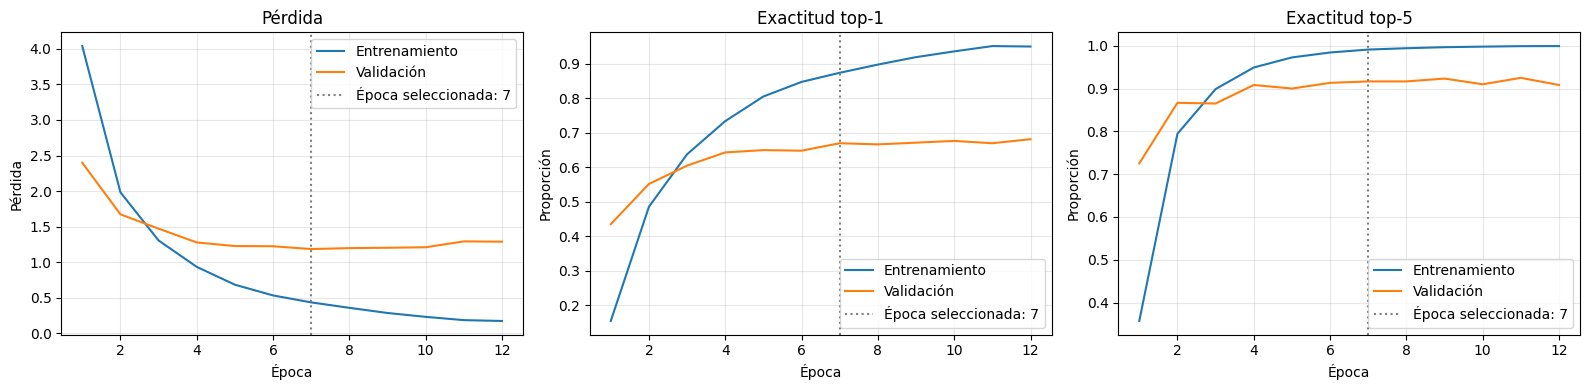

In [ ]:
# ------------------------------------------------------------
# 1. PREPARAR EL EJE DE ÉPOCAS
# ------------------------------------------------------------
epochs_img = np.arange(1, len(history_img.epoch) + 1)


# ------------------------------------------------------------
# 2. REPRESENTAR LAS TRES MÉTRICAS
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "top5"],
    ["Pérdida", "Exactitud top-1", "Exactitud top-5"],
):
    ax.plot(
        epochs_img,
        history_img.history[metric],
        label="Entrenamiento",
    )

    ax.plot(
        epochs_img,
        history_img.history[f"val_{metric}"],
        label="Validación",
    )

    # Marcar la época cuyos pesos fueron restaurados.
    ax.axvline(
        best_epoch_img,
        color="gray",
        linestyle=":",
        label=f"Época seleccionada: {best_epoch_img}",
    )

    ax.set_title(title)
    ax.set_xlabel("Época")
    ax.set_ylabel("Pérdida" if metric == "loss" else "Proporción")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

El clasificador visual muestra una mejora inicial en entrenamiento y validación. A partir de la época 7, aumenta la separación entre ambas curvas: el modelo continúa ajustándose al entrenamiento sin una mejora sostenida de la pérdida de validación. Este comportamiento es compatible con sobreajuste y respalda la selección de la época 7 mediante EarlyStopping.

En esa época, la exactitud de validación fue del 67,00 % en top-1 y del 91,67 % en top-5. Estos valores describen el desempeño en validación, no todavía en prueba.

## 12. Evaluación del clasificador visual en prueba

Evaluamos el modelo seleccionado mediante la pérdida de validación,
sin modificar sus pesos ni ajustar hiperparámetros con prueba.

Calculamos cuatro métricas:

- Top-1: proporción de imágenes cuya especie se predice correctamente.
- Top-5: proporción cuya especie está entre las cinco más probables.
- F1-macro: promedio del F1 de las 200 especies, con igual peso por clase.
- ROC-AUC macro: promedio del área bajo la curva ROC de cada especie
  frente a las restantes (one-vs-rest).

Convertimos los logits a probabilidades mediante softmax.
Conservamos las predicciones en el mismo orden de los datos de prueba
para analizar posteriormente los errores y realizar late fusion.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    top_k_accuracy_score,
    f1_score,
    roc_auc_score,
)

# ------------------------------------------------------------
# 1. GENERAR LOS LOGITS DE PRUEBA
# ------------------------------------------------------------
# image_test_ds no mezcla las observaciones.
# predict utiliza el modo de inferencia: Dropout está desactivado.
logits_img_test = image_model.predict(
    image_test_ds,
    verbose=1,
)

y_test = prepared["test"]["labels"]

assert logits_img_test.shape == (len(y_test), NUM_CLASSES)
assert np.isfinite(logits_img_test).all()


# ------------------------------------------------------------
# 2. CONVERTIR LOS LOGITS A PROBABILIDADES
# ------------------------------------------------------------
probs_img_test = tf.nn.softmax(
    logits_img_test,
    axis=1,
).numpy()

# La clase predicha corresponde a la mayor probabilidad.
pred_img_test = np.argmax(probs_img_test, axis=1)

np.testing.assert_allclose(
    probs_img_test.sum(axis=1),
    1.0,
    atol=1e-5,
)


# ------------------------------------------------------------
# 3. COMPROBAR LA PRESENCIA DE LAS 200 ESPECIES
# ------------------------------------------------------------
# ROC-AUC requiere ejemplos positivos y negativos por clase.
assert np.array_equal(
    np.unique(y_test),
    np.arange(NUM_CLASSES),
), "No están representadas todas las especies en prueba."


# ------------------------------------------------------------
# 4. CALCULAR LAS MÉTRICAS
# ------------------------------------------------------------
metrics_img_test = {
    "modelo": "Solo imagen",
    "top1": accuracy_score(y_test, pred_img_test),

    "top5": top_k_accuracy_score(
        y_test,
        probs_img_test,
        k=5,
        labels=np.arange(NUM_CLASSES),
    ),

    "f1_macro": f1_score(
        y_test,
        pred_img_test,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0,
    ),

    # Cada especie se compara con el conjunto de las restantes.
    "roc_auc_macro_ovr": roc_auc_score(
        y_test,
        probs_img_test,
        labels=np.arange(NUM_CLASSES),
        multi_class="ovr",
        average="macro",
    ),
}


# ------------------------------------------------------------
# 5. MOSTRAR LOS RESULTADOS
# ------------------------------------------------------------
display(
    pd.DataFrame([metrics_img_test])
    .set_index("modelo")
    .round(4)
)

print("Fotografías evaluadas:", len(y_test))
print("✓ Predicciones conservadas para el análisis posterior.")

182/182 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


,top1,top5,f1_macro,roc_auc_macro_ovr
modelo,,,,
Solo imagen,0.6804,0.9127,0.6806,0.9942


Fotografías evaluadas: 5794
✓ Predicciones conservadas para el análisis posterior.


### Resultados del clasificador visual

El modelo seleccionado obtuvo en las 5.794 fotografías de prueba
una exactitud top-1 del 68,04 % y top-5 del 91,27 %. El F1-macro
fue de 0,6806, cercano a la exactitud global, aunque esta similitud
no implica que todas las especies se clasifiquen con igual desempeño.

El ROC-AUC macro one-vs-rest fue de 0,9942. Este valor indica una
alta capacidad para ordenar los ejemplos de cada especie frente
a los de las restantes. No equivale a acertar el 99,42 % de las
clasificaciones: elegir la especie correcta entre 200 alternativas
es una exigencia distinta, medida por top-1 y top-5.

Los resultados de prueba son cercanos a los de validación de la
época seleccionada: 67,00 % en top-1 y 91,67 % en top-5.
Esta proximidad no muestra una caída marcada entre ambos conjuntos
en esta ejecución, pero no demuestra ausencia de sobreajuste.

Estos resultados constituyen la referencia visual para comparar
posteriormente los modelos de texto, atributos y fusión multimodal.

## 13. Parejas de especies con mayor confusión

Construimos una matriz de confusión con las etiquetas reales y
las predicciones del clasificador visual.

Para cada pareja de especies A y B, sumamos los errores en ambas
direcciones: imágenes de A clasificadas como B e imágenes de B
clasificadas como A. Ordenamos las parejas por ese total y mostramos
las diez con mayor confusión.

Este resumen utiliza conteos absolutos. También mostramos el número
de imágenes de prueba de cada especie para contextualizar los errores.
Las confusiones identificadas no se utilizarán para ajustar el modelo
con los datos de prueba.

In [ ]:
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. CONSTRUIR LA MATRIZ DE CONFUSIÓN
# ------------------------------------------------------------
# Filas: especie real.
# Columnas: especie predicha.
cm_img = confusion_matrix(
    y_test,
    pred_img_test,
    labels=np.arange(NUM_CLASSES),
)

# La suma de cada fila es el número de imágenes de esa especie.
class_support = cm_img.sum(axis=1)


# ------------------------------------------------------------
# 2. SUMAR LOS ERRORES ENTRE CADA PAREJA
# ------------------------------------------------------------
# cm[A, B] + cm[B, A] reúne las dos direcciones de confusión.
pair_errors = cm_img + cm_img.T

# Seleccionamos solo el triángulo superior, sin la diagonal:
# así no incluimos aciertos ni repetimos las parejas.
rows, cols = np.triu_indices(NUM_CLASSES, k=1)

pairs_img = pd.DataFrame({
    "label_A": rows,
    "label_B": cols,
    "errores_A_a_B": cm_img[rows, cols],
    "errores_B_a_A": cm_img[cols, rows],
    "errores_totales": pair_errors[rows, cols],
    "imagenes_A": class_support[rows],
    "imagenes_B": class_support[cols],
})


# ------------------------------------------------------------
# 3. SELECCIONAR LAS DIEZ PAREJAS CON MÁS ERRORES
# ------------------------------------------------------------
# Conservamos solo parejas con al menos una confusión.
# Los IDs resuelven empates de forma reproducible.
top_pairs_img = (
    pairs_img.loc[pairs_img["errores_totales"] > 0]
    .sort_values(
        ["errores_totales", "label_A", "label_B"],
        ascending=[False, True, True],
    )
    .head(10)
    .copy()
)

# Incorporamos los nombres utilizando las etiquetas 0...199.
top_pairs_img["especie_A"] = top_pairs_img["label_A"].map(class_names)
top_pairs_img["especie_B"] = top_pairs_img["label_B"].map(class_names)


# ------------------------------------------------------------
# 4. MOSTRAR EL RESUMEN
# ------------------------------------------------------------
display(
    top_pairs_img[
        [
            "especie_A",
            "especie_B",
            "errores_A_a_B",
            "errores_B_a_A",
            "errores_totales",
            "imagenes_A",
            "imagenes_B",
        ]
    ].reset_index(drop=True)
)

print("Errores totales del clasificador:", int((y_test != pred_img_test).sum()))
print("✓ Diez parejas con mayor confusión identificadas.")

,especie_A,especie_B,errores_A_a_B,errores_B_a_A,errores_totales,imagenes_A,imagenes_B
0,001.Black_footed_Albatross,003.Sooty_Albatross,19,0,19,30,28
1,037.Acadian_Flycatcher,039.Least_Flycatcher,18,1,19,29,29
2,029.American_Crow,030.Fish_Crow,12,3,15,30,30
3,039.Least_Flycatcher,043.Yellow_bellied_Flycatcher,1,14,15,29,29
4,144.Common_Tern,146.Forsters_Tern,12,3,15,30,30
5,111.Loggerhead_Shrike,112.Great_Grey_Shrike,12,1,13,30,30
6,022.Chuck_will_Widow,105.Whip_poor_Will,2,10,12,26,19
7,023.Brandt_Cormorant,025.Pelagic_Cormorant,1,11,12,29,30
8,030.Fish_Crow,107.Common_Raven,1,11,12,30,30
9,121.Grasshopper_Sparrow,131.Vesper_Sparrow,11,1,12,30,30


Errores totales del clasificador: 1852
✓ Diez parejas con mayor confusión identificadas.


### Análisis de las principales confusiones visuales

El clasificador cometió 1.852 errores entre las 5.794 imágenes de
prueba, correspondientes aproximadamente al 31,96 % de los ejemplos.

Las mayores confusiones se observaron entre Black-footed Albatross
y Sooty Albatross, y entre Acadian Flycatcher y Least Flycatcher,
con 19 errores por pareja.

Los errores presentan asimetrías importantes. Por ejemplo, 19 de
las 30 imágenes de Black-footed Albatross se clasificaron como
Sooty Albatross (63,33 %), mientras que ninguna de las 28 imágenes
de Sooty Albatross se clasificó como Black-footed Albatross.

Asimismo, 18 de las 29 imágenes de Acadian Flycatcher se asignaron
a Least Flycatcher (62,07 %), frente a un error en la dirección
contraria.

Estos resultados identifican dificultades específicas del modelo,
pero no permiten atribuirlas todavía a una causa concreta.
La inspección de las fotografías ayudará a explorar posibles
semejanzas visuales, efectos del recorte o variaciones de apariencia.
Posteriormente compararemos estas confusiones con las del modelo
textual para examinar si las modalidades aportan información
complementaria.


## 14. Clasificador unimodal de texto: preparación de los lotes

Utilizamos las descripciones codificadas en el primer taller.
Cada imagen dispone de diez secuencias de 25 posiciones.

Durante el entrenamiento seleccionamos una descripción al azar
en cada lectura. En validación y prueba utilizamos siempre la primera,
como establece el pipeline del primer taller.

Cada entrada será una secuencia de identificadores de palabras.
El valor 0 representa relleno y posteriormente será enmascarado
mediante Embedding(mask_zero=True). Las longitudes válidas permanecen
disponibles en los datos preparados, aunque este modelo utilizará
la máscara para identificar las posiciones de relleno.

Las etiquetas se conservan como enteros de 0 a 199.


In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR LA SELECCIÓN DE UNA DESCRIPCIÓN
# ------------------------------------------------------------
def select_text_caption(caption_ids, caption_lengths, label, training=False):

    if training:
        # Elegir una de las diez descripciones en cada lectura.
        caption_idx = tf.random.uniform(
            shape=[],
            minval=0,
            maxval=tf.shape(caption_ids)[0],
            dtype=tf.int32,
        )
    else:
        # Mantener una entrada fija en validación y prueba.
        caption_idx = tf.constant(0, dtype=tf.int32)

    input_ids = tf.gather(caption_ids, caption_idx)
    length = tf.gather(caption_lengths, caption_idx)

    # Comprobar que el número de posiciones no nulas
    # coincide con la longitud válida registrada.
    tf.debugging.assert_equal(
        tf.reduce_sum(
            tf.cast(input_ids != 0, tf.int64)
        ),
        length,
    )

    return tf.ensure_shape(input_ids, [max_len]), label


# ------------------------------------------------------------
# 2. CONSTRUIR EL DATASET TEXTUAL DE UNA PARTICIÓN
# ------------------------------------------------------------
def build_text_classifier_dataset(split, training=False):
    data = prepared[split]

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            data["caption_ids"],
            data["caption_lengths"],
            data["labels"],
        )
    )

    # Mezclar las imágenes únicamente en entrenamiento.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(data["labels"]),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    # Como en el ejemplo del profesor, utilizamos map
    # para preparar cada observación antes de agruparla.
    dataset = dataset.map(
        lambda ids, lengths, label: select_text_caption(
            ids,
            lengths,
            label,
            training=training,
        ),
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )

    # No colocamos cache después de la selección aleatoria:
    # eso fijaría las captions elegidas en el primer recorrido.
    dataset = dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    )

    return dataset.prefetch(AUTOTUNE)


# ------------------------------------------------------------
# 3. CREAR LOS TRES DATASETS
# ------------------------------------------------------------
text_train_ds = build_text_classifier_dataset(
    "train",
    training=True,
)

text_val_ds = build_text_classifier_dataset("val")
text_test_ds = build_text_classifier_dataset("test")


# ------------------------------------------------------------
# 4. INSPECCIONAR UN LOTE DE ENTRENAMIENTO
# ------------------------------------------------------------
for text_batch, text_labels_batch in text_train_ds.take(1):
    print(
        "Texto:",
        tuple(text_batch.shape),
        text_batch.dtype.name,
    )
    print(
        "Etiquetas:",
        tuple(text_labels_batch.shape),
        text_labels_batch.dtype.name,
    )

    assert tuple(text_batch.shape) == (BATCH_SIZE, max_len)
    assert tuple(text_labels_batch.shape) == (BATCH_SIZE,)

    # Reconstruir la primera descripción sin el relleno.
    first_ids = text_batch[0].numpy()

    print("\nPrimera descripción del lote:")
    print(
        " ".join(
            id_to_word[int(index)]
            for index in first_ids
            if index != 0
        )
    )

print("\n✓ Lotes del clasificador textual preparados.")

Texto: (32, 25) int64
Etiquetas: (32,) int64

Primera descripción del lote:
a small black and brown bird with light eyes and black feet

✓ Lotes del clasificador textual preparados.


## 15. Construcción del clasificador unimodal de texto

El modelo recibe secuencias de 25 identificadores de palabras.
Una capa Embedding representa cada palabra mediante un vector
aprendible de 128 valores. Estos vectores se entrenan desde cero.

La opción mask_zero=True identifica las posiciones de relleno
para que la LSTM no las utilice como palabras de la descripción.

Una LSTM de 256 unidades procesa la secuencia y produce una
representación de la descripción. Finalmente, una capa densa
genera 200 logits, uno por especie.

Siguiendo el ejemplo de clase, configuramos el entrenamiento
con Adam. Utilizamos SparseCategoricalCrossentropy porque
las etiquetas son enteros, y registramos exactitud top-1 y top-5.


In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EL CLASIFICADOR TEXTUAL
# ------------------------------------------------------------
def build_text_classifier():

    # Cada entrada contiene max_len identificadores enteros.
    inputs = layers.Input(
        shape=(max_len,),
        dtype="int64",
        name="input_ids",
    )

    # Convertir los IDs en vectores aprendibles de 128 valores.
    # mask_zero=True genera una máscara para el relleno.
    x = layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True,
        name="word_embedding",
    )(inputs)

    # Procesar la secuencia y devolver su representación final.
    # La máscara de Embedding se transmite automáticamente.
    x = layers.LSTM(
        units=256,
        name="text_lstm",
    )(x)

    # Generar un logit por especie, sin softmax.
    logits = layers.Dense(
        NUM_CLASSES,
        name="logits",
    )(x)

    return tf.keras.Model(
        inputs=inputs,
        outputs=logits,
        name="text_classifier",
    )


# ------------------------------------------------------------
# 2. CREAR EL MODELO CON UNA SEMILLA FIJA
# ------------------------------------------------------------
tf.keras.utils.set_random_seed(SEED)

text_model = build_text_classifier()


# ------------------------------------------------------------
# 3. CONFIGURAR EL ENTRENAMIENTO
# ------------------------------------------------------------
# Mantenemos el optimizador y las métricas del modelo visual.
text_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True,
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy",
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top5",
        ),
    ],
)


# ------------------------------------------------------------
# 4. MOSTRAR LA ARQUITECTURA
# ------------------------------------------------------------
text_model.summary()

assert text_model.input_shape == (None, max_len)
assert text_model.output_shape == (None, NUM_CLASSES)


# ------------------------------------------------------------
# 5. COMPROBAR LA SALIDA CON UN LOTE DE VALIDACIÓN
# ------------------------------------------------------------
# Es una pasada de inferencia, sin actualizar los pesos.
for input_ids, labels in text_val_ds.take(1):
    example_logits = text_model(
        input_ids,
        training=False,
    )

    assert tuple(example_logits.shape) == (
        int(tf.shape(labels)[0].numpy()),
        NUM_CLASSES,
    )

    tf.debugging.assert_all_finite(
        example_logits,
        "El modelo textual produjo valores no finitos.",
    )

    print("\nForma de entrada:", tuple(input_ids.shape))
    print("Forma de salida:", tuple(example_logits.shape))

print("\n✓ Clasificador textual construido y configurado.")

Model: "text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 25)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_embedding      │ (None, 25, 128)   │    266,112 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 25)        │          0 │ input_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_lstm (LSTM)    │ (None, 256)       │    394,240 │ word_embedding[0… │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, 200)       │     51,400 │ text_lstm[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 711,752 (2.72 MB)

 Trainable params: 711,752 (2.72 MB)

 Non-trainable params: 0 (0.00 B)


Forma de entrada: (32, 25)
Forma de salida: (32, 200)

✓ Clasificador textual construido y configurado.


## 16. Entrenamiento del clasificador textual

Entrenamos desde cero los embeddings de palabras, la LSTM y la
capa de clasificación. Cada recorrido de entrenamiento selecciona
una de las diez descripciones disponibles por imagen.

En validación utilizamos siempre la primera descripción para
mantener una evaluación estable.

Establecemos un máximo inicial de 30 épocas. EarlyStopping detendrá
el entrenamiento después de cinco épocas sin mejorar la pérdida
de validación y restaurará los pesos de la mejor época.

El conjunto de prueba no participa en la selección del modelo.


In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EL MÁXIMO DE ÉPOCAS
# ------------------------------------------------------------
# Utilizamos el mismo máximo inicial que para imagen.
TEXT_EPOCHS = 30


# ------------------------------------------------------------
# 2. ENTRENAR EL MODELO TEXTUAL
# ------------------------------------------------------------
# Reutilizamos la función make_callbacks ya definida.
# Cada llamada crea un callback nuevo e independiente.
history_text = text_model.fit(
    text_train_ds,
    validation_data=text_val_ds,
    epochs=TEXT_EPOCHS,
    callbacks=make_callbacks(patience=5),
    verbose=2,
)


# ------------------------------------------------------------
# 3. IDENTIFICAR LA ÉPOCA SELECCIONADA
# ------------------------------------------------------------
# El criterio es la menor pérdida de validación,
# no necesariamente la mayor exactitud.
best_epoch_text = int(
    np.argmin(history_text.history["val_loss"]) + 1
)

best_index_text = best_epoch_text - 1

print("\nÉpocas ejecutadas:", len(history_text.epoch))
print("Mejor época según val_loss:", best_epoch_text)

print(
    "Pérdida de validación:",
    f"{history_text.history['val_loss'][best_index_text]:.4f}",
)

print(
    "Top-1 de validación:",
    f"{history_text.history['val_accuracy'][best_index_text]:.4f}",
)

print(
    "Top-5 de validación:",
    f"{history_text.history['val_top5'][best_index_text]:.4f}",
)

Epoch 1/30
169/169 - 6s - 37ms/step - accuracy: 0.0095 - loss: 5.2066 - top5: 0.0462 - val_accuracy: 0.0133 - val_loss: 4.9578 - val_top5: 0.0700
Epoch 2/30
169/169 - 2s - 11ms/step - accuracy: 0.0239 - loss: 4.8095 - top5: 0.1010 - val_accuracy: 0.0200 - val_loss: 4.6855 - val_top5: 0.1333
Epoch 3/30
169/169 - 2s - 12ms/step - accuracy: 0.0350 - loss: 4.5515 - top5: 0.1583 - val_accuracy: 0.0467 - val_loss: 4.4374 - val_top5: 0.1800
Epoch 4/30
169/169 - 1s - 9ms/step - accuracy: 0.0551 - loss: 4.3455 - top5: 0.2106 - val_accuracy: 0.0583 - val_loss: 4.2487 - val_top5: 0.2100
Epoch 5/30
169/169 - 1s - 9ms/step - accuracy: 0.0717 - loss: 4.2041 - top5: 0.2445 - val_accuracy: 0.0800 - val_loss: 4.1048 - val_top5: 0.2717
Epoch 6/30
169/169 - 1s - 8ms/step - accuracy: 0.0812 - loss: 4.0454 - top5: 0.2827 - val_accuracy: 0.0783 - val_loss: 4.0467 - val_top5: 0.2717
Epoch 7/30
169/169 - 3s - 15ms/step - accuracy: 0.0964 - loss: 3.9598 - top5: 0.3092 - val_accuracy: 0.1117 - val_loss: 3.9387 

## 17. Curvas de aprendizaje del clasificador textual

El modelo textual completó las 30 épocas previstas. La menor pérdida
de validación se obtuvo en la época 28, cuyos pesos fueron restaurados.

En esa época, la exactitud de validación fue del 23,33 % en top-1
y del 50,33 % en top-5.

La pérdida de validación disminuyó durante gran parte del entrenamiento.
Por ello, alcanzar el máximo de épocas no demuestra que el aprendizaje
haya convergido. Conservamos esta ejecución como configuración inicial
y examinamos sus curvas antes de evaluar en prueba.

La comparación posterior con imagen debe considerar que ResNet50
utiliza preentrenamiento en ImageNet, mientras que los embeddings
textuales y la LSTM se entrenaron desde cero.

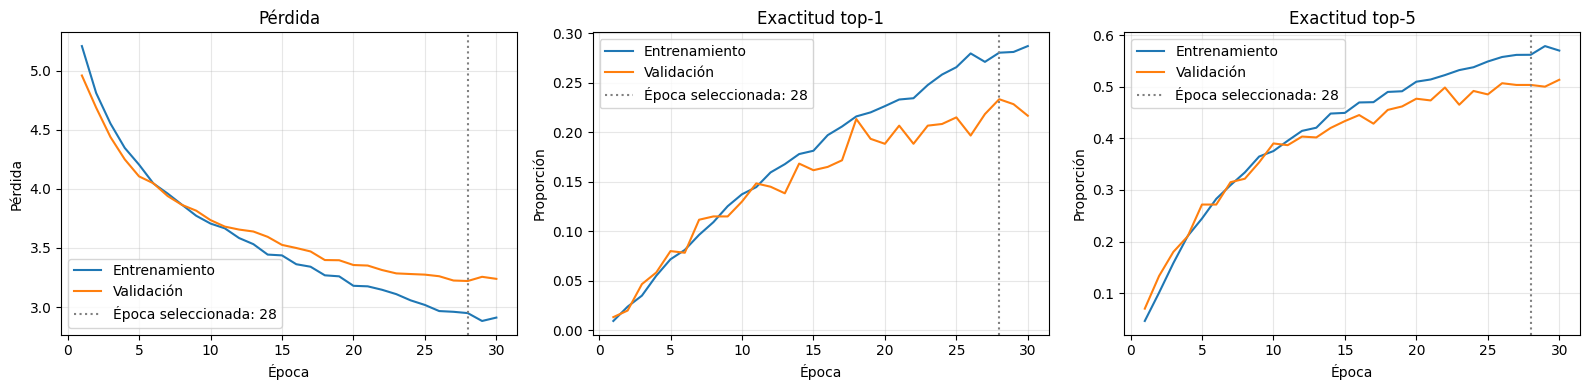

In [ ]:
# ------------------------------------------------------------
# 1. PREPARAR EL EJE DE ÉPOCAS
# ------------------------------------------------------------
epochs_text = np.arange(1, len(history_text.epoch) + 1)


# ------------------------------------------------------------
# 2. REPRESENTAR PÉRDIDA, TOP-1 Y TOP-5
# ------------------------------------------------------------
# Conservamos el formato utilizado para el clasificador visual.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "top5"],
    ["Pérdida", "Exactitud top-1", "Exactitud top-5"],
):
    ax.plot(
        epochs_text,
        history_text.history[metric],
        label="Entrenamiento",
    )

    ax.plot(
        epochs_text,
        history_text.history[f"val_{metric}"],
        label="Validación",
    )

    # Señalar la época cuyos pesos utiliza el modelo actual.
    ax.axvline(
        best_epoch_text,
        color="gray",
        linestyle=":",
        label=f"Época seleccionada: {best_epoch_text}",
    )

    ax.set_title(title)
    ax.set_xlabel("Época")
    ax.set_ylabel("Pérdida" if metric == "loss" else "Proporción")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Interpretación de las curvas del modelo textual

La pérdida disminuye tanto en entrenamiento como en validación,
mientras las exactitudes top-1 y top-5 aumentan progresivamente.
Este comportamiento indica que el modelo está aprendiendo relaciones
útiles entre las descripciones y las especies.

A medida que avanza el entrenamiento, aparece una brecha entre ambos
conjuntos, compatible con un mayor ajuste a los datos de entrenamiento.
Sin embargo, la pérdida de validación continúa mejorando hasta etapas
tardías, por lo que las curvas no permiten afirmar que el aprendizaje
haya convergido.

La época 28 fue seleccionada por su menor pérdida de validación:
3,2202, con top-1 del 23,33 % y top-5 del 50,33 %. Aunque la época 30
obtuvo un top-5 mayor, ese no fue el criterio de selección establecido.

La comparación con el modelo visual debe considerar que este utiliza
representaciones preentrenadas en ImageNet, mientras que el modelo
textual aprende desde cero y recibe una descripción limitada a
25 tokens por observación.

## 18. Evaluación del clasificador textual en prueba

Evaluamos el modelo seleccionado mediante la pérdida de validación,
sin modificar sus pesos. Cada imagen de prueba aporta únicamente
su primera descripción, según el protocolo establecido.

Calculamos exactitud top-1, exactitud top-5, F1-macro y ROC-AUC macro
one-vs-rest. Conservamos los logits y las probabilidades en el orden
original de prueba para analizar errores y realizar late fusion.

La comparación con imagen corresponde a estas configuraciones
específicas, no a una superioridad general de una modalidad.

In [ ]:
# ------------------------------------------------------------
# 1. GENERAR LOS LOGITS DEL MODELO TEXTUAL
# ------------------------------------------------------------
# text_test_ds conserva el orden y utiliza la primera caption.
# predict desactiva el comportamiento de entrenamiento.
logits_text_test = text_model.predict(
    text_test_ds,
    verbose=1,
)

y_test = prepared["test"]["labels"]

assert logits_text_test.shape == (len(y_test), NUM_CLASSES)
assert np.isfinite(logits_text_test).all()


# ------------------------------------------------------------
# 2. CONVERTIR LOS LOGITS A PROBABILIDADES
# ------------------------------------------------------------
probs_text_test = tf.nn.softmax(
    logits_text_test,
    axis=1,
).numpy()

pred_text_test = np.argmax(
    probs_text_test,
    axis=1,
)

# Cada fila debe representar una distribución de probabilidades.
np.testing.assert_allclose(
    probs_text_test.sum(axis=1),
    1.0,
    atol=1e-5,
)


# ------------------------------------------------------------
# 3. COMPROBAR EL ORDEN DE LAS ETIQUETAS
# ------------------------------------------------------------
# Verificamos que las predicciones correspondan al mismo orden
# utilizado por los datos preparados y el clasificador visual.
labels_from_text_ds = np.concatenate([
    labels.numpy()
    for _, labels in text_test_ds
])

np.testing.assert_array_equal(
    labels_from_text_ds,
    y_test,
)

assert np.array_equal(
    np.unique(y_test),
    np.arange(NUM_CLASSES),
)


# ------------------------------------------------------------
# 4. CALCULAR LAS MÉTRICAS
# ------------------------------------------------------------
# Reutilizamos las funciones de sklearn importadas
# en la evaluación del clasificador visual.
metrics_text_test = {
    "modelo": "Solo texto",

    "top1": accuracy_score(
        y_test,
        pred_text_test,
    ),

    "top5": top_k_accuracy_score(
        y_test,
        probs_text_test,
        k=5,
        labels=np.arange(NUM_CLASSES),
    ),

    "f1_macro": f1_score(
        y_test,
        pred_text_test,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0,
    ),

    "roc_auc_macro_ovr": roc_auc_score(
        y_test,
        probs_text_test,
        labels=np.arange(NUM_CLASSES),
        multi_class="ovr",
        average="macro",
    ),
}


# ------------------------------------------------------------
# 5. COMPARAR LOS DOS MODELOS EVALUADOS
# ------------------------------------------------------------
unimodal_results = pd.DataFrame([
    metrics_img_test,
    metrics_text_test,
]).set_index("modelo")

display(unimodal_results.round(4))

print("Descripciones de prueba evaluadas:", len(y_test))
print("✓ Predicciones textuales conservadas.")

182/182 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


,top1,top5,f1_macro,roc_auc_macro_ovr
modelo,,,,
Solo imagen,0.6804,0.9127,0.6806,0.9942
Solo texto,0.2337,0.5197,0.2230,0.9346


Descripciones de prueba evaluadas: 5794
✓ Predicciones textuales conservadas.


### Resultados del clasificador textual y comparación inicial

En las 5.794 descripciones de prueba, el modelo textual obtuvo
una exactitud top-1 del 23,37 %, top-5 del 51,97 %, F1-macro de
0,2230 y ROC-AUC macro one-vs-rest de 0,9346.

En esta configuración, el clasificador visual superó al textual
en las cuatro métricas. La diferencia en top-1 fue de 44,67 puntos
porcentuales. Esta comparación debe considerar que el modelo visual
utiliza características preentrenadas en ImageNet, mientras que
el modelo textual se entrenó desde cero y recibe una única
descripción truncada a un máximo de 25 tokens.

El ROC-AUC textual indica capacidad discriminativa frente a las
clases restantes, pero no equivale a exactitud al seleccionar
una especie entre las 200 alternativas.

El menor desempeño individual del texto no descarta que aporte
información complementaria a la imagen. Para examinarlo, compararemos
sus errores y posteriormente evaluaremos la fusión multimodal.


## 19. Confusiones del modelo textual y comparación con imagen

Construimos la matriz de confusión del clasificador textual y
seleccionamos las diez parejas de especies con más errores,
sumando ambas direcciones de confusión.

Después comparamos esas parejas con las diez principales del
clasificador visual. La coincidencia entre listas describe errores
compartidos; sus diferencias sugieren dificultades distintas, pero
no demuestran por sí solas que la fusión vaya a mejorar el desempeño.

También contamos los casos donde solo uno de los modelos acierta.
Esto permite examinar su posible complementariedad por observación.


In [ ]:
# ------------------------------------------------------------
# 1. CONSTRUIR LA MATRIZ DE CONFUSIÓN TEXTUAL
# ------------------------------------------------------------
cm_text = confusion_matrix(
    y_test,
    pred_text_test,
    labels=np.arange(NUM_CLASSES),
)

support_text = cm_text.sum(axis=1)


# ------------------------------------------------------------
# 2. REUNIR LAS CONFUSIONES EN AMBAS DIRECCIONES
# ------------------------------------------------------------
# Seleccionamos cada pareja una sola vez, sin incluir aciertos.
rows, cols = np.triu_indices(NUM_CLASSES, k=1)

pairs_text = pd.DataFrame({
    "label_A": rows,
    "label_B": cols,
    "errores_A_a_B": cm_text[rows, cols],
    "errores_B_a_A": cm_text[cols, rows],
    "errores_totales": cm_text[rows, cols] + cm_text[cols, rows],
    "imagenes_A": support_text[rows],
    "imagenes_B": support_text[cols],
})


# ------------------------------------------------------------
# 3. SELECCIONAR LAS DIEZ PAREJAS PRINCIPALES
# ------------------------------------------------------------
top_pairs_text = (
    pairs_text.loc[pairs_text["errores_totales"] > 0]
    .sort_values(
        ["errores_totales", "label_A", "label_B"],
        ascending=[False, True, True],
    )
    .head(10)
    .copy()
)

top_pairs_text["especie_A"] = (
    top_pairs_text["label_A"].map(class_names)
)
top_pairs_text["especie_B"] = (
    top_pairs_text["label_B"].map(class_names)
)

print("Diez parejas con mayor confusión textual:")

display(
    top_pairs_text[
        [
            "especie_A",
            "especie_B",
            "errores_A_a_B",
            "errores_B_a_A",
            "errores_totales",
            "imagenes_A",
            "imagenes_B",
        ]
    ].reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. COMPARAR LAS LISTAS DE CONFUSIONES PRINCIPALES
# ------------------------------------------------------------
# Utilizamos los identificadores, no los nombres, para comparar.
image_pair_set = set(
    zip(top_pairs_img["label_A"], top_pairs_img["label_B"])
)

text_pair_set = set(
    zip(top_pairs_text["label_A"], top_pairs_text["label_B"])
)

shared_pairs = sorted(image_pair_set & text_pair_set)

print(
    "\nParejas compartidas entre los dos top-10:",
    len(shared_pairs),
)

for label_a, label_b in shared_pairs:
    print(
        f"- {class_names[label_a]} ↔ {class_names[label_b]}"
    )


# ------------------------------------------------------------
# 5. COMPARAR LOS ACIERTOS POR OBSERVACIÓN
# ------------------------------------------------------------
# Ambos vectores de predicción corresponden al mismo orden
# de imágenes de prueba.
assert pred_img_test.shape == pred_text_test.shape == y_test.shape

image_correct = pred_img_test == y_test
text_correct = pred_text_test == y_test

# Conservamos estas máscaras para seleccionar ejemplos después.
only_image_correct = image_correct & ~text_correct
only_text_correct = ~image_correct & text_correct
both_correct = image_correct & text_correct
both_wrong = ~image_correct & ~text_correct

comparison_counts = pd.DataFrame({
    "resultado": [
        "Ambos aciertan",
        "Solo imagen acierta",
        "Solo texto acierta",
        "Ambos fallan",
    ],
    "observaciones": [
        int(both_correct.sum()),
        int(only_image_correct.sum()),
        int(only_text_correct.sum()),
        int(both_wrong.sum()),
    ],
})

comparison_counts["porcentaje"] = (
    comparison_counts["observaciones"] / len(y_test) * 100
)

assert comparison_counts["observaciones"].sum() == len(y_test)

display(comparison_counts.round({"porcentaje": 2}))

print("✓ Comparación de errores completada.")

Diez parejas con mayor confusión textual:


,especie_A,especie_B,errores_A_a_B,errores_B_a_A,errores_totales,imagenes_A,imagenes_B
0,027.Shiny_Cowbird,030.Fish_Crow,6,8,14,30,30
1,029.American_Crow,030.Fish_Crow,9,5,14,30,30
2,030.Fish_Crow,107.Common_Raven,4,9,13,30,30
3,029.American_Crow,107.Common_Raven,5,5,10,30,30
4,042.Vermilion_Flycatcher,139.Scarlet_Tanager,3,7,10,30,30
5,050.Eared_Grebe,051.Horned_Grebe,7,3,10,30,30
6,141.Artic_Tern,144.Common_Tern,5,5,10,29,30
7,004.Groove_billed_Ani,027.Shiny_Cowbird,6,3,9,30,30
8,004.Groove_billed_Ani,030.Fish_Crow,8,1,9,30,30
9,009.Brewer_Blackbird,011.Rusty_Blackbird,5,4,9,29,30



Parejas compartidas entre los dos top-10: 2
- 029.American_Crow ↔ 030.Fish_Crow
- 030.Fish_Crow ↔ 107.Common_Raven


,resultado,observaciones,porcentaje
0,Ambos aciertan,1118,19.30
1,Solo imagen acierta,2824,48.74
2,Solo texto acierta,236,4.07
3,Ambos fallan,1616,27.89


✓ Comparación de errores completada.


### Comparación de errores entre imagen y texto

Los modelos comparten dos parejas entre sus diez confusiones principales:
American Crow–Fish Crow y Fish Crow–Common Raven. Por tanto, sus
dificultades coinciden parcialmente, pero también presentan diferencias.

Ambos clasificadores aciertan en 1.118 observaciones (19,30 %).
Solo imagen acierta en 2.824 (48,74 %) y solo texto en 236 (4,07 %).
Los dos fallan en 1.616 observaciones (27,89 %).

Los 236 aciertos exclusivos del texto muestran información potencialmente
complementaria. Sin embargo, disponer de esa complementariedad no
garantiza que una regla de fusión pueda identificar correctamente
cuándo confiar en cada modelo.

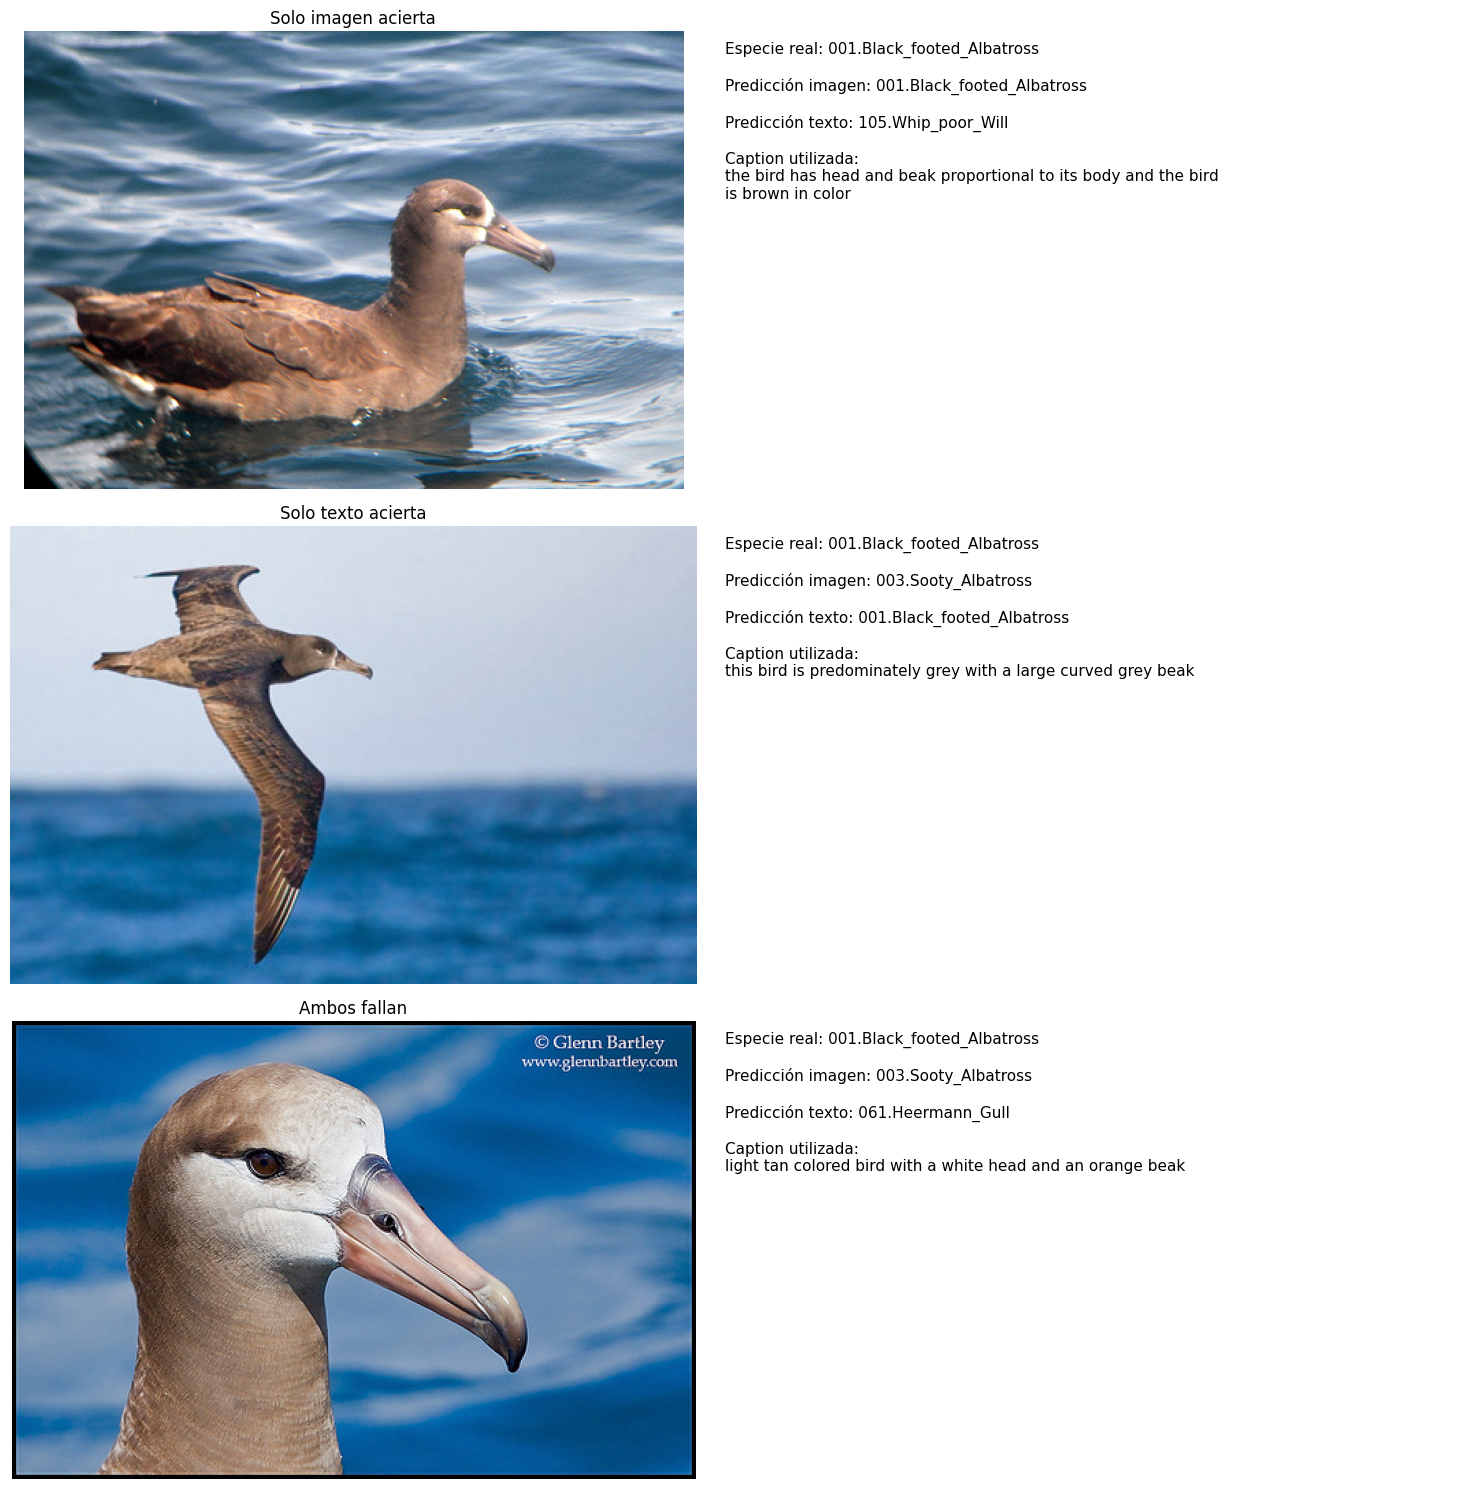

In [ ]:
from PIL import Image
import textwrap

# ------------------------------------------------------------
# 1. SELECCIONAR UN EJEMPLO POR TIPO DE RESULTADO
# ------------------------------------------------------------
# Tomamos el primer caso disponible de cada categoría.
cases = [
    ("Solo imagen acierta", only_image_correct),
    ("Solo texto acierta", only_text_correct),
    ("Ambos fallan", both_wrong),
]

selected = []

for title, mask in cases:
    indices = np.flatnonzero(mask)

    if len(indices) > 0:
        selected.append((title, int(indices[0])))


# ------------------------------------------------------------
# 2. PREPARAR LA FIGURA
# ------------------------------------------------------------
fig, axes = plt.subplots(
    len(selected),
    2,
    figsize=(15, 5 * len(selected)),
    squeeze=False,
)

test_data = prepared["test"]


# ------------------------------------------------------------
# 3. MOSTRAR FOTOGRAFÍA, CAPTION Y PREDICCIONES
# ------------------------------------------------------------
for row, (title, idx) in enumerate(selected):

    # Abrimos la fotografía original para contextualizar el caso.
    # No es el recorte exacto utilizado por ResNet50.
    image_path = IMAGES_DIR / str(test_data["image_paths"][idx])

    with Image.open(image_path) as source:
        photo = source.convert("RGB")

    # Recuperamos la primera caption codificada:
    # es la que recibió el clasificador textual en prueba.
    length = int(test_data["caption_lengths"][idx, 0])
    token_ids = test_data["caption_ids"][idx, 0, :length]

    caption = " ".join(
        id_to_word[int(token_id)]
        for token_id in token_ids
    )

    true_label = int(y_test[idx])
    image_pred = int(pred_img_test[idx])
    text_pred = int(pred_text_test[idx])

    axes[row, 0].imshow(photo)
    axes[row, 0].set_title(title)
    axes[row, 0].axis("off")

    description = (
        f"Especie real: {class_names[true_label]}\n\n"
        f"Predicción imagen: {class_names[image_pred]}\n\n"
        f"Predicción texto: {class_names[text_pred]}\n\n"
        f"Caption utilizada:\n{textwrap.fill(caption, width=65)}"
    )

    axes[row, 1].text(
        0,
        0.98,
        description,
        transform=axes[row, 1].transAxes,
        va="top",
        fontsize=11,
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

## 20. Clasificador unimodal de atributos

Este modelo utiliza exclusivamente las 318 características tabulares:
312 atributos visuales binarios y seis variables geométricas
estandarizadas con estadísticas de entrenamiento.

Construimos una red densa con una capa oculta de 128 unidades,
activación ReLU y Dropout de 0,30. La capa final produce 200 logits.

Los atributos son anotaciones proporcionadas por el dataset,
no características predichas por este modelo. Por ello, su desempeño
supone que esa información está disponible al clasificar.

No volvemos a escalar los datos: los arreglos recuperados del primer
taller ya contienen la transformación correspondiente.


In [ ]:
# ------------------------------------------------------------
# 1. CONSTRUIR LOS DATASETS TABULARES
# ------------------------------------------------------------
def build_attribute_dataset(split, training=False):
    data = prepared[split]

    dataset = tf.data.Dataset.from_tensor_slices(
        (data["tabular"], data["labels"])
    )

    # Mantener el mismo criterio de mezcla de los otros modelos.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(data["labels"]),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    return dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    ).prefetch(AUTOTUNE)


attribute_train_ds = build_attribute_dataset("train", training=True)
attribute_val_ds = build_attribute_dataset("val")
attribute_test_ds = build_attribute_dataset("test")


# ------------------------------------------------------------
# 2. INSPECCIONAR UN LOTE
# ------------------------------------------------------------
for attributes_batch, labels_batch in attribute_train_ds.take(1):
    assert tuple(attributes_batch.shape) == (BATCH_SIZE, 318)
    assert tuple(labels_batch.shape) == (BATCH_SIZE,)

    tf.debugging.assert_all_finite(
        attributes_batch,
        "Hay características tabulares no finitas.",
    )

    print(
        "Atributos:",
        tuple(attributes_batch.shape),
        attributes_batch.dtype.name,
    )
    print(
        "Etiquetas:",
        tuple(labels_batch.shape),
        labels_batch.dtype.name,
    )


# ------------------------------------------------------------
# 3. DEFINIR EL CLASIFICADOR
# ------------------------------------------------------------
def build_attribute_classifier():
    return tf.keras.Sequential(
        [
            layers.Input(shape=(318,)),
            layers.Dense(128, activation="relu"),
            layers.Dropout(0.30),
            layers.Dense(NUM_CLASSES, name="logits"),
        ],
        name="attribute_classifier",
    )


# ------------------------------------------------------------
# 4. CREAR Y CONFIGURAR EL MODELO
# ------------------------------------------------------------
tf.keras.utils.set_random_seed(SEED)

attribute_model = build_attribute_classifier()

attribute_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True,
    ),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy",
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top5",
        ),
    ],
)


# ------------------------------------------------------------
# 5. COMPROBAR LA ARQUITECTURA
# ------------------------------------------------------------
attribute_model.summary()

assert attribute_model.input_shape == (None, 318)
assert attribute_model.output_shape == (None, NUM_CLASSES)

print("\n✓ Clasificador de atributos construido y configurado.")

Atributos: (32, 318) float32
Etiquetas: (32,) int64


Model: "attribute_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │        40,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 200)            │        25,800 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,632 (260.28 KB)

 Trainable params: 66,632 (260.28 KB)

 Non-trainable params: 0 (0.00 B)


✓ Clasificador de atributos construido y configurado.


## 21. Entrenamiento del clasificador de atributos

Entrenamos la red utilizando las 318 características tabulares
y las etiquetas de especie.

Mantenemos el máximo inicial de 30 épocas y el criterio de selección
utilizado en los otros clasificadores: menor pérdida de validación.
EarlyStopping detendrá el entrenamiento después de cinco épocas
sin mejora y restaurará los mejores pesos.

El conjunto de prueba no participa en el entrenamiento ni en la
selección de la época.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EL MÁXIMO DE ÉPOCAS
# ------------------------------------------------------------
ATTRIBUTE_EPOCHS = 30


# ------------------------------------------------------------
# 2. ENTRENAR EL CLASIFICADOR TABULAR
# ------------------------------------------------------------
# Cada llamada a make_callbacks crea un callback independiente.
history_attribute = attribute_model.fit(
    attribute_train_ds,
    validation_data=attribute_val_ds,
    epochs=ATTRIBUTE_EPOCHS,
    callbacks=make_callbacks(patience=5),
    verbose=2,
)


# ------------------------------------------------------------
# 3. IDENTIFICAR LA ÉPOCA SELECCIONADA
# ------------------------------------------------------------
best_epoch_attribute = int(
    np.argmin(history_attribute.history["val_loss"]) + 1
)

best_index_attribute = best_epoch_attribute - 1

print("\nÉpocas ejecutadas:", len(history_attribute.epoch))
print("Mejor época según val_loss:", best_epoch_attribute)

print(
    "Pérdida de validación:",
    f"{history_attribute.history['val_loss'][best_index_attribute]:.4f}",
)

print(
    "Top-1 de validación:",
    f"{history_attribute.history['val_accuracy'][best_index_attribute]:.4f}",
)

print(
    "Top-5 de validación:",
    f"{history_attribute.history['val_top5'][best_index_attribute]:.4f}",
)

Epoch 1/30
169/169 - 11s - 67ms/step - accuracy: 0.0412 - loss: 5.0173 - top5: 0.1372 - val_accuracy: 0.1850 - val_loss: 4.3527 - val_top5: 0.3950
Epoch 2/30
169/169 - 11s - 62ms/step - accuracy: 0.2054 - loss: 3.7462 - top5: 0.4659 - val_accuracy: 0.2850 - val_loss: 3.2801 - val_top5: 0.6117
Epoch 3/30
169/169 - 0s - 3ms/step - accuracy: 0.3016 - loss: 3.0112 - top5: 0.6151 - val_accuracy: 0.3517 - val_loss: 2.8139 - val_top5: 0.6883
Epoch 4/30
169/169 - 0s - 3ms/step - accuracy: 0.3758 - loss: 2.6025 - top5: 0.6889 - val_accuracy: 0.3900 - val_loss: 2.5455 - val_top5: 0.7250
Epoch 5/30
169/169 - 0s - 3ms/step - accuracy: 0.4253 - loss: 2.3311 - top5: 0.7330 - val_accuracy: 0.4267 - val_loss: 2.3921 - val_top5: 0.7500
Epoch 6/30
169/169 - 0s - 3ms/step - accuracy: 0.4753 - loss: 2.1091 - top5: 0.7786 - val_accuracy: 0.4300 - val_loss: 2.2541 - val_top5: 0.7567
Epoch 7/30
169/169 - 0s - 3ms/step - accuracy: 0.5108 - loss: 1.9441 - top5: 0.7998 - val_accuracy: 0.4583 - val_loss: 2.1690 

## 22. Curvas de aprendizaje del clasificador de atributos

El clasificador mejoró durante las primeras épocas y alcanzó su
menor pérdida de validación en la época 18. Después transcurrieron
cinco épocas sin mejorar ese criterio, por lo que EarlyStopping
detuvo el entrenamiento y restauró los pesos seleccionados.

La pérdida de entrenamiento continuó disminuyendo mientras la
de validación se estabilizó, un patrón compatible con sobreajuste.
En la época seleccionada se obtuvo un 50,00 % de exactitud top-1
y un 79,00 % de top-5 en validación.

Estos resultados corresponden al modelo tabular completo:
312 atributos anotados y seis variables geométricas. No permiten
separar todavía la contribución de ambos grupos.

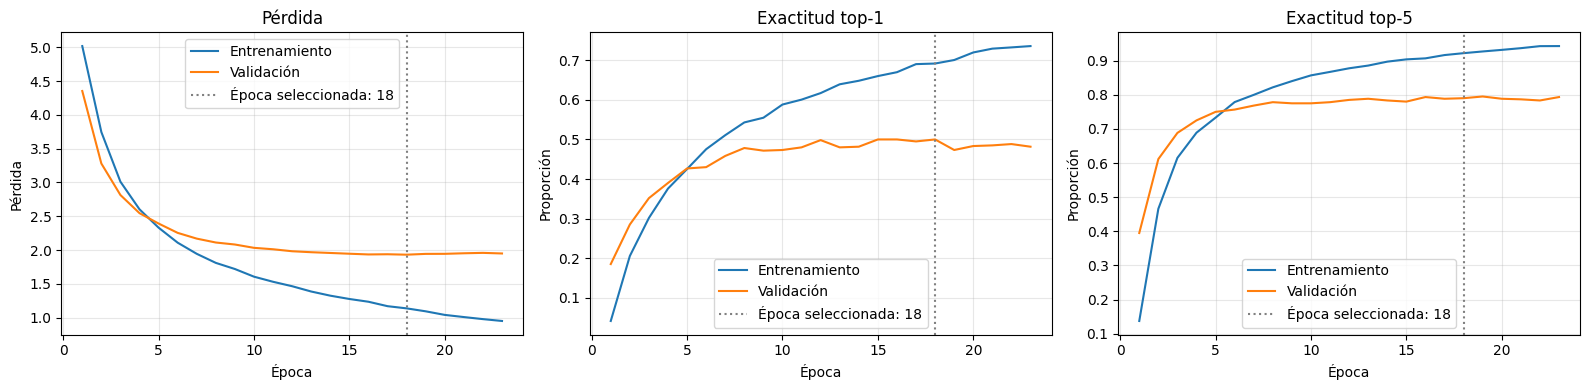

In [ ]:
# ------------------------------------------------------------
# 1. PREPARAR EL EJE DE ÉPOCAS
# ------------------------------------------------------------
epochs_attribute = np.arange(
    1,
    len(history_attribute.epoch) + 1,
)


# ------------------------------------------------------------
# 2. REPRESENTAR LAS CURVAS DE APRENDIZAJE
# ------------------------------------------------------------
# Conservamos el formato de los clasificadores anteriores.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "top5"],
    ["Pérdida", "Exactitud top-1", "Exactitud top-5"],
):
    ax.plot(
        epochs_attribute,
        history_attribute.history[metric],
        label="Entrenamiento",
    )

    ax.plot(
        epochs_attribute,
        history_attribute.history[f"val_{metric}"],
        label="Validación",
    )

    # Marcar la época cuyos pesos fueron restaurados.
    ax.axvline(
        best_epoch_attribute,
        color="gray",
        linestyle=":",
        label=f"Época seleccionada: {best_epoch_attribute}",
    )

    ax.set_title(title)
    ax.set_xlabel("Época")
    ax.set_ylabel("Pérdida" if metric == "loss" else "Proporción")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Interpretación de las curvas del modelo de atributos

El modelo mejora rápidamente durante las primeras épocas. Después,
las exactitudes de validación se estabilizan alrededor del 50 % en
top-1 y del 79 % en top-5, mientras el desempeño de entrenamiento
continúa aumentando.

Esta separación es compatible con sobreajuste. La época 18 fue
seleccionada por su menor pérdida de validación, aunque otras épocas
alcanzaron valores similares o superiores en alguna métrica de
exactitud. El criterio de selección se mantuvo fijo en val_loss.

El modelo actual conserva los pesos de la época 18. Las curvas
muestran las 23 épocas ejecutadas.

## 23. Evaluación del clasificador de atributos en prueba

Calculamos top-1, top-5, F1-macro y ROC-AUC macro one-vs-rest
utilizando el modelo seleccionado mediante validación.

Conservamos las predicciones en el orden original de prueba para
analizar confusiones y combinar posteriormente las tres modalidades.


In [ ]:
# ------------------------------------------------------------
# 1. GENERAR LOS LOGITS DE PRUEBA
# ------------------------------------------------------------
logits_attribute_test = attribute_model.predict(
    attribute_test_ds,
    verbose=1,
)

y_test = prepared["test"]["labels"]

assert logits_attribute_test.shape == (len(y_test), NUM_CLASSES)
assert np.isfinite(logits_attribute_test).all()


# ------------------------------------------------------------
# 2. VERIFICAR EL ORDEN DE LAS ETIQUETAS
# ------------------------------------------------------------
# Confirmamos la alineación con las otras modalidades.
labels_from_attribute_ds = np.concatenate([
    labels.numpy()
    for _, labels in attribute_test_ds
])

np.testing.assert_array_equal(
    labels_from_attribute_ds,
    y_test,
)


# ------------------------------------------------------------
# 3. OBTENER PROBABILIDADES Y PREDICCIONES
# ------------------------------------------------------------
probs_attribute_test = tf.nn.softmax(
    logits_attribute_test,
    axis=1,
).numpy()

pred_attribute_test = np.argmax(
    probs_attribute_test,
    axis=1,
)

np.testing.assert_allclose(
    probs_attribute_test.sum(axis=1),
    1.0,
    atol=1e-5,
)


# ------------------------------------------------------------
# 4. CALCULAR LAS MISMAS MÉTRICAS DE LOS OTROS MODELOS
# ------------------------------------------------------------
metrics_attribute_test = {
    "modelo": "Solo atributos",

    "top1": accuracy_score(y_test, pred_attribute_test),

    "top5": top_k_accuracy_score(
        y_test,
        probs_attribute_test,
        k=5,
        labels=np.arange(NUM_CLASSES),
    ),

    "f1_macro": f1_score(
        y_test,
        pred_attribute_test,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0,
    ),

    "roc_auc_macro_ovr": roc_auc_score(
        y_test,
        probs_attribute_test,
        labels=np.arange(NUM_CLASSES),
        multi_class="ovr",
        average="macro",
    ),
}


# ------------------------------------------------------------
# 5. MOSTRAR LA COMPARACIÓN DE LAS TRES MODALIDADES
# ------------------------------------------------------------
unimodal_results = pd.DataFrame([
    metrics_img_test,
    metrics_text_test,
    metrics_attribute_test,
]).set_index("modelo")

display(unimodal_results.round(4))

print("Observaciones de prueba evaluadas:", len(y_test))
print("✓ Predicciones de atributos conservadas.")

182/182 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


,top1,top5,f1_macro,roc_auc_macro_ovr
modelo,,,,
Solo imagen,0.6804,0.9127,0.6806,0.9942
Solo texto,0.2337,0.5197,0.2230,0.9346
Solo atributos,0.5007,0.7686,0.4956,0.9757


Observaciones de prueba evaluadas: 5794
✓ Predicciones de atributos conservadas.


### Comparación de los clasificadores unimodales

El clasificador visual obtuvo el mayor desempeño en las cuatro
métricas, seguido por el modelo de atributos y el modelo textual.

El modelo tabular alcanzó una exactitud top-1 del 50,07 %, top-5
del 76,86 %, F1-macro de 0,4956 y ROC-AUC macro one-vs-rest de
0,9757. Su exactitud top-1 fue cercana al 50,00 % observado en
validación para la época seleccionada.

Estas comparaciones corresponden a las configuraciones evaluadas.
El modelo visual utiliza representaciones preentrenadas en ImageNet;
el textual se entrenó desde cero y recibe una descripción de hasta
25 tokens; el tabular recibe atributos anotados y geometría de la
caja delimitadora.

El orden de desempeño individual no determina qué combinación
será mejor. Las siguientes etapas examinarán si las modalidades
aportan información complementaria mediante fusión de
representaciones y de predicciones.

## 24. Principales confusiones del clasificador de atributos

Construimos la matriz de confusión del modelo tabular y sumamos
los errores en ambas direcciones para cada pareja de especies.

Mostramos las diez parejas con mayor número de confusiones,
incluyendo los errores por dirección y el número de imágenes
de cada especie. Finalmente, identificamos cuáles aparecen
también en las listas principales de imagen y texto.

La comparación es descriptiva: no utilizamos estos errores
de prueba para ajustar los modelos.

In [ ]:
# ------------------------------------------------------------
# 1. CONSTRUIR LA MATRIZ DE CONFUSIÓN
# ------------------------------------------------------------
# Filas: etiqueta real. Columnas: etiqueta predicha.
cm_attribute = confusion_matrix(
    y_test,
    pred_attribute_test,
    labels=np.arange(NUM_CLASSES),
)

support_attribute = cm_attribute.sum(axis=1)


# ------------------------------------------------------------
# 2. CONTAR LOS ERRORES ENTRE PAREJAS DE ESPECIES
# ------------------------------------------------------------
# Excluimos la diagonal y evitamos repetir cada pareja.
rows, cols = np.triu_indices(NUM_CLASSES, k=1)

pairs_attribute = pd.DataFrame({
    "label_A": rows,
    "label_B": cols,
    "errores_A_a_B": cm_attribute[rows, cols],
    "errores_B_a_A": cm_attribute[cols, rows],
    "errores_totales": (
        cm_attribute[rows, cols] + cm_attribute[cols, rows]
    ),
    "imagenes_A": support_attribute[rows],
    "imagenes_B": support_attribute[cols],
})


# ------------------------------------------------------------
# 3. SELECCIONAR LAS DIEZ PAREJAS PRINCIPALES
# ------------------------------------------------------------
top_pairs_attribute = (
    pairs_attribute.loc[
        pairs_attribute["errores_totales"] > 0
    ]
    .sort_values(
        ["errores_totales", "label_A", "label_B"],
        ascending=[False, True, True],
    )
    .head(10)
    .copy()
)

top_pairs_attribute["especie_A"] = (
    top_pairs_attribute["label_A"].map(class_names)
)
top_pairs_attribute["especie_B"] = (
    top_pairs_attribute["label_B"].map(class_names)
)

display(
    top_pairs_attribute[
        [
            "especie_A",
            "especie_B",
            "errores_A_a_B",
            "errores_B_a_A",
            "errores_totales",
            "imagenes_A",
            "imagenes_B",
        ]
    ].reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. COMPARAR LAS LISTAS DE CONFUSIONES
# ------------------------------------------------------------
attribute_pair_set = set(
    zip(
        top_pairs_attribute["label_A"],
        top_pairs_attribute["label_B"],
    )
)

# Recalculamos los conjuntos a partir de las tablas existentes.
image_pair_set = set(
    zip(top_pairs_img["label_A"], top_pairs_img["label_B"])
)

text_pair_set = set(
    zip(top_pairs_text["label_A"], top_pairs_text["label_B"])
)

for name, other_pairs in [
    ("imagen", image_pair_set),
    ("texto", text_pair_set),
]:
    common = sorted(attribute_pair_set & other_pairs)

    print(
        f"\nParejas compartidas entre atributos y {name}: "
        f"{len(common)}"
    )

    for label_a, label_b in common:
        print(
            f"- {class_names[label_a]} ↔ "
            f"{class_names[label_b]}"
        )


# ------------------------------------------------------------
# 5. MOSTRAR EL NÚMERO TOTAL DE ERRORES
# ------------------------------------------------------------
n_errors_attribute = int(
    (pred_attribute_test != y_test).sum()
)

print(
    "\nErrores totales del clasificador de atributos:",
    n_errors_attribute,
)

print("✓ Análisis de confusiones de atributos completado.")

,especie_A,especie_B,errores_A_a_B,errores_B_a_A,errores_totales,imagenes_A,imagenes_B
0,029.American_Crow,030.Fish_Crow,6,15,21,30,30
1,143.Caspian_Tern,145.Elegant_Tern,5,14,19,30,30
2,023.Brandt_Cormorant,025.Pelagic_Cormorant,4,14,18,29,30
3,183.Northern_Waterthrush,184.Louisiana_Waterthrush,11,7,18,30,30
4,111.Loggerhead_Shrike,112.Great_Grey_Shrike,10,7,17,30,30
5,014.Indigo_Bunting,054.Blue_Grosbeak,7,6,13,30,30
6,029.American_Crow,107.Common_Raven,5,8,13,30,30
7,067.Anna_Hummingbird,068.Ruby_throated_Hummingbird,8,4,12,30,30
8,141.Artic_Tern,144.Common_Tern,4,8,12,29,30
9,193.Bewick_Wren,195.Carolina_Wren,6,6,12,30,30



Parejas compartidas entre atributos y imagen: 3
- 023.Brandt_Cormorant ↔ 025.Pelagic_Cormorant
- 029.American_Crow ↔ 030.Fish_Crow
- 111.Loggerhead_Shrike ↔ 112.Great_Grey_Shrike

Parejas compartidas entre atributos y texto: 3
- 029.American_Crow ↔ 030.Fish_Crow
- 029.American_Crow ↔ 107.Common_Raven
- 141.Artic_Tern ↔ 144.Common_Tern

Errores totales del clasificador de atributos: 2893
✓ Análisis de confusiones de atributos completado.


### Interpretación de las confusiones del modelo de atributos

El clasificador de atributos cometió 2.893 errores en las 5.794
observaciones de prueba. La pareja con mayor confusión fue
American Crow–Fish Crow, con 21 errores: seis en una dirección
y quince en la contraria.

Su lista de diez principales confusiones comparte tres parejas
con imagen y tres con texto. American Crow–Fish Crow aparece
en las tres listas, lo que identifica una dificultad compartida
por las configuraciones evaluadas.

Las coincidencias son parciales. Esto sugiere diferencias en los
patrones de error, pero las listas por parejas no bastan para
determinar si los modelos fallan en las mismas observaciones
ni si una fusión mejorará los resultados.

## 25. Early fusion: preparación de las entradas multimodales

Construimos un único dataset que entrega el embedding visual,
una descripción codificada y las características tabulares
de la misma fotografía.

Durante entrenamiento seleccionamos una caption al azar.
En validación y prueba utilizamos siempre la primera.

El ejemplo del profesor trabaja con datasets y pares multimodales.
Conservamos esa organización, pero aquí la correspondencia viene
dada por la fotografía: no emparejamos ejemplos distintos de
la misma especie.

En el siguiente paso fusionaremos las representaciones de las
tres ramas antes de la clasificación. Aunque el taller lo denomina
early fusion, corresponde a una fusión a nivel de características
o fusión intermedia.

In [ ]:
# ------------------------------------------------------------
# 1. SELECCIONAR EL TEXTO SIN SEPARAR LAS MODALIDADES
# ------------------------------------------------------------
def select_fusion_inputs(features, label, training=False):

    if training:
        caption_idx = tf.random.uniform(
            shape=[],
            minval=0,
            maxval=tf.shape(features["caption_ids"])[0],
            dtype=tf.int32,
        )
    else:
        caption_idx = tf.constant(0, dtype=tf.int32)

    # Las tres entradas proceden de la misma observación.
    inputs = {
        "image_embedding": features["image_embedding"],
        "input_ids": tf.gather(
            features["caption_ids"], caption_idx
        ),
        "attributes": features["attributes"],
    }

    return inputs, label


# ------------------------------------------------------------
# 2. CONSTRUIR EL PIPELINE MULTIMODAL
# ------------------------------------------------------------
def build_fusion_dataset(split, training=False):
    data = prepared[split]

    assert len(visual_embeddings[split]) == len(data["labels"])

    # Agrupamos antes de mezclar para mantener la correspondencia.
    features = {
        "image_embedding": visual_embeddings[split],
        "caption_ids": data["caption_ids"],
        "attributes": data["tabular"],
    }

    dataset = tf.data.Dataset.from_tensor_slices(
        (features, data["labels"])
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(data["labels"]),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        lambda inputs, label: select_fusion_inputs(
            inputs, label, training=training
        ),
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )

    # No almacenamos en caché después de elegir la caption:
    # queremos permitir nuevas selecciones en entrenamiento.
    return dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    ).prefetch(AUTOTUNE)


# ------------------------------------------------------------
# 3. CREAR LOS TRES DATASETS
# ------------------------------------------------------------
fusion_train_ds = build_fusion_dataset("train", training=True)
fusion_val_ds = build_fusion_dataset("val")
fusion_test_ds = build_fusion_dataset("test")


# ------------------------------------------------------------
# 4. INSPECCIONAR UN LOTE
# ------------------------------------------------------------
for inputs, labels in fusion_train_ds.take(1):
    for name, tensor in inputs.items():
        print(
            f"{name}: forma={tuple(tensor.shape)}, "
            f"tipo={tensor.dtype.name}"
        )

    print(
        f"labels: forma={tuple(labels.shape)}, "
        f"tipo={labels.dtype.name}"
    )

    assert tuple(inputs["image_embedding"].shape) == (BATCH_SIZE, 2048)
    assert tuple(inputs["input_ids"].shape) == (BATCH_SIZE, max_len)
    assert tuple(inputs["attributes"].shape) == (BATCH_SIZE, 318)
    assert tuple(labels.shape) == (BATCH_SIZE,)

print("\n✓ Lotes multimodales preparados para early fusion.")

image_embedding: forma=(32, 2048), tipo=float32
input_ids: forma=(32, 25), tipo=int64
attributes: forma=(32, 318), tipo=float32
labels: forma=(32,), tipo=int64

✓ Lotes multimodales preparados para early fusion.


## 26. Construcción del modelo de early fusion

Cada modalidad se transforma mediante una rama específica:

- Imagen: embedding de 2.048 valores → Dense de 512 unidades.
- Texto: IDs → Embedding de 128 dimensiones → LSTM de 256 unidades.
- Atributos: 318 características → Dense de 128 unidades.

Concatenamos las tres representaciones en un vector de 896 valores.
Una cabeza compartida aprende a combinarlas y produce 200 logits.

Entrenamos conjuntamente las tres ramas y la cabeza con una sola
pérdida de clasificación. ResNet50 permanece congelada y fuera de
este modelo, porque utilizamos sus embeddings precalculados.

Inicializamos las ramas desde cero, sin reutilizar los pesos de
los clasificadores unimodales. La cabeza compartida de 256 unidades
y Dropout de 0,30 son decisiones de implementación.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR LAS TRES RAMAS Y SU FUSIÓN
# ------------------------------------------------------------
def build_early_fusion_model():

    # Rama visual: transformar los embeddings precalculados.
    image_input = layers.Input(
        shape=(2048,),
        dtype="float32",
        name="image_embedding",
    )

    image_features = layers.Dense(
        512,
        activation="relu",
        name="image_projection",
    )(image_input)

    # Rama textual: aprender representaciones desde cero.
    text_input = layers.Input(
        shape=(max_len,),
        dtype="int64",
        name="input_ids",
    )

    text_features = layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=128,
        mask_zero=True,
        name="word_embedding",
    )(text_input)

    text_features = layers.LSTM(
        256,
        name="text_lstm",
    )(text_features)

    # Rama tabular: transformar atributos y geometría.
    attribute_input = layers.Input(
        shape=(318,),
        dtype="float32",
        name="attributes",
    )

    attribute_features = layers.Dense(
        128,
        activation="relu",
        name="attribute_projection",
    )(attribute_input)

    # --------------------------------------------------------
    # 2. CONCATENAR LAS REPRESENTACIONES
    # --------------------------------------------------------
    # 512 de imagen + 256 de texto + 128 de atributos = 896.
    fused_features = layers.Concatenate(
        name="feature_fusion",
    )([
        image_features,
        text_features,
        attribute_features,
    ])

    # Cabeza compartida de clasificación.
    x = layers.Dense(
        256,
        activation="relu",
        name="fusion_dense",
    )(fused_features)

    x = layers.Dropout(
        0.30,
        name="fusion_dropout",
    )(x)

    logits = layers.Dense(
        NUM_CLASSES,
        name="logits",
    )(x)

    return tf.keras.Model(
        inputs={
            "image_embedding": image_input,
            "input_ids": text_input,
            "attributes": attribute_input,
        },
        outputs=logits,
        name="early_fusion_classifier",
    )


# ------------------------------------------------------------
# 3. CREAR Y CONFIGURAR EL MODELO
# ------------------------------------------------------------
tf.keras.utils.set_random_seed(SEED)

early_fusion_model = build_early_fusion_model()

early_fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),

    # Una única pérdida actualiza todas las ramas entrenables.
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True,
    ),

    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy",
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top5",
        ),
    ],
)

early_fusion_model.summary()


# ------------------------------------------------------------
# 4. COMPROBAR UNA PASADA DE INFERENCIA
# ------------------------------------------------------------
# Utilizamos validación para comprobar la estructura,
# sin actualizar los parámetros del modelo.
for inputs, labels in fusion_val_ds.take(1):
    logits = early_fusion_model(inputs, training=False)

    assert tuple(logits.shape) == (
        int(tf.shape(labels)[0].numpy()),
        NUM_CLASSES,
    )

    tf.debugging.assert_all_finite(
        logits,
        "La fusión produjo valores no finitos.",
    )

    print("\nForma de salida:", tuple(logits.shape))

print("✓ Modelo de early fusion construido y configurado.")

Model: "early_fusion_classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 25)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_embedding     │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_embedding      │ (None, 25, 128)   │    266,112 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 25)        │          0 │ input_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attributes          │ (None, 318)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_projection    │ (None, 512)       │  1,049,088 │ image_embedding[… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_lstm (LSTM)    │ (None, 256)       │    394,240 │ word_embedding[0… │
│                     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attribute_projecti… │ (None, 128)       │     40,832 │ attributes[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ feature_fusion      │ (None, 896)       │          0 │ image_projection… │
│ (Concatenate)       │                   │            │ text_lstm[0][0],  │
│                     │                   │            │ attribute_projec… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dense        │ (None, 256)       │    229,632 │ feature_fusion[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fusion_dropout      │ (None, 256)       │          0 │ fusion_dense[0][… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, 200)       │     51,400 │ fusion_dropout[0… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,031,304 (7.75 MB)

 Trainable params: 2,031,304 (7.75 MB)

 Non-trainable params: 0 (0.00 B)


Forma de salida: (32, 200)
✓ Modelo de early fusion construido y configurado.


## 27. Entrenamiento del modelo de early fusion

Entrenamos conjuntamente las ramas de imagen, texto y atributos,
junto con la cabeza compartida, mediante una única pérdida de
clasificación.

En cada lectura de entrenamiento se selecciona una descripción
al azar de la fotografía. En validación se utiliza siempre la primera.

Establecemos un máximo inicial de 30 épocas. EarlyStopping supervisa
la pérdida de validación, detiene el entrenamiento después de cinco
épocas sin mejora y restaura los mejores pesos.

El backbone visual permanece congelado. El conjunto de prueba
no interviene en la selección del modelo.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EL MÁXIMO DE ÉPOCAS
# ------------------------------------------------------------
EARLY_FUSION_EPOCHS = 30


# ------------------------------------------------------------
# 2. ENTRENAR LAS TRES RAMAS CON UNA SOLA PÉRDIDA
# ------------------------------------------------------------
history_early = early_fusion_model.fit(
    fusion_train_ds,
    validation_data=fusion_val_ds,
    epochs=EARLY_FUSION_EPOCHS,
    callbacks=make_callbacks(patience=5),
    verbose=2,
)


# ------------------------------------------------------------
# 3. IDENTIFICAR LA ÉPOCA SELECCIONADA
# ------------------------------------------------------------
best_epoch_early = int(
    np.argmin(history_early.history["val_loss"]) + 1
)

best_index_early = best_epoch_early - 1

print("\nÉpocas ejecutadas:", len(history_early.epoch))
print("Mejor época según val_loss:", best_epoch_early)

print(
    "Pérdida de validación:",
    f"{history_early.history['val_loss'][best_index_early]:.4f}",
)

print(
    "Top-1 de validación:",
    f"{history_early.history['val_accuracy'][best_index_early]:.4f}",
)

print(
    "Top-5 de validación:",
    f"{history_early.history['val_top5'][best_index_early]:.4f}",
)

Epoch 1/30
169/169 - 5s - 32ms/step - accuracy: 0.0951 - loss: 4.3717 - top5: 0.2618 - val_accuracy: 0.3817 - val_loss: 2.6165 - val_top5: 0.7050
Epoch 2/30
169/169 - 2s - 10ms/step - accuracy: 0.3912 - loss: 2.2961 - top5: 0.7312 - val_accuracy: 0.5333 - val_loss: 1.7131 - val_top5: 0.8467
Epoch 3/30
169/169 - 2s - 9ms/step - accuracy: 0.5805 - loss: 1.4866 - top5: 0.8782 - val_accuracy: 0.5983 - val_loss: 1.3721 - val_top5: 0.8917
Epoch 4/30
169/169 - 1s - 9ms/step - accuracy: 0.6867 - loss: 1.0475 - top5: 0.9381 - val_accuracy: 0.6300 - val_loss: 1.2605 - val_top5: 0.9183
Epoch 5/30
169/169 - 2s - 9ms/step - accuracy: 0.7723 - loss: 0.7500 - top5: 0.9690 - val_accuracy: 0.6800 - val_loss: 1.1481 - val_top5: 0.9250
Epoch 6/30
169/169 - 2s - 9ms/step - accuracy: 0.8293 - loss: 0.5550 - top5: 0.9846 - val_accuracy: 0.6483 - val_loss: 1.1767 - val_top5: 0.9233
Epoch 7/30
169/169 - 2s - 9ms/step - accuracy: 0.8637 - loss: 0.4351 - top5: 0.9913 - val_accuracy: 0.6733 - val_loss: 1.0623 - 

## 28. Curvas de aprendizaje de early fusion

El entrenamiento se detuvo en la época 12 y restauró los pesos
de la época 7, seleccionada por su menor pérdida de validación.

En esa época, el modelo obtuvo una pérdida de 1,0623, exactitud
top-1 del 67,33 % y top-5 del 92,50 %.

Aunque épocas posteriores alcanzaron mayor top-1, el criterio
de selección se mantuvo en val_loss. La pérdida de entrenamiento
continuó disminuyendo mientras la de validación dejó de mejorar,
un patrón compatible con sobreajuste.

Las diferencias frente al clasificador visual en validación son
pequeñas. Esta ejecución, por sí sola, no permite establecer
una mejora consistente atribuible a la fusión.

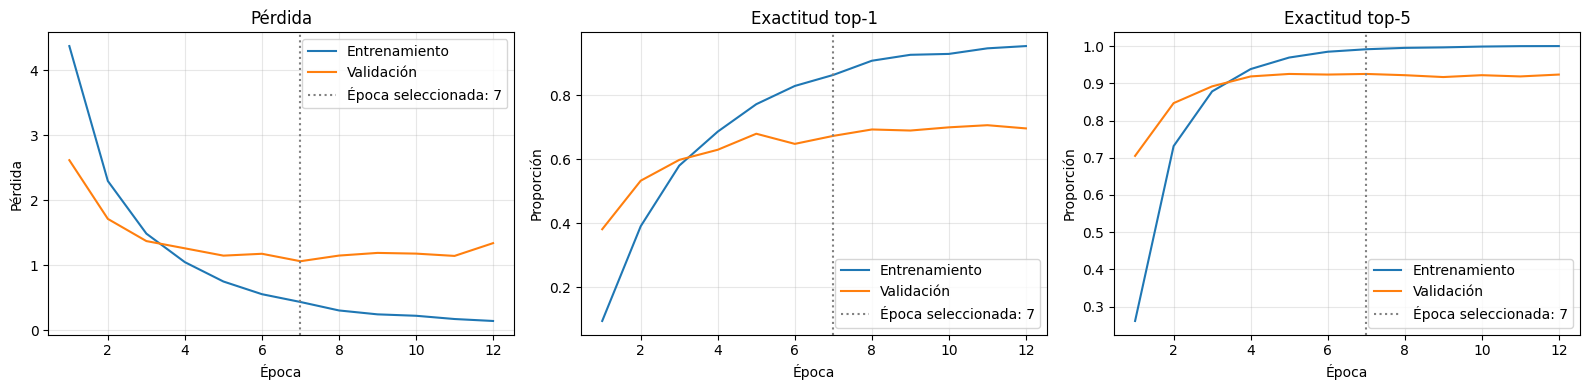

In [ ]:
# ------------------------------------------------------------
# 1. PREPARAR EL EJE DE ÉPOCAS
# ------------------------------------------------------------
epochs_early = np.arange(
    1,
    len(history_early.epoch) + 1,
)


# ------------------------------------------------------------
# 2. REPRESENTAR LAS CURVAS
# ------------------------------------------------------------
# Conservamos el formato de los modelos anteriores,
# siguiendo la visualización del notebook del profesor.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "top5"],
    ["Pérdida", "Exactitud top-1", "Exactitud top-5"],
):
    ax.plot(
        epochs_early,
        history_early.history[metric],
        label="Entrenamiento",
    )

    ax.plot(
        epochs_early,
        history_early.history[f"val_{metric}"],
        label="Validación",
    )

    # Señalar la época cuyos pesos fueron restaurados.
    ax.axvline(
        best_epoch_early,
        color="gray",
        linestyle=":",
        label=f"Época seleccionada: {best_epoch_early}",
    )

    ax.set_title(title)
    ax.set_xlabel("Época")
    ax.set_ylabel("Pérdida" if metric == "loss" else "Proporción")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

## 29. Evaluación de early fusion en prueba

Evaluamos el modelo con los pesos seleccionados mediante validación.
Utilizamos las tres modalidades de cada observación y siempre la
primera descripción textual.

Calculamos las mismas cuatro métricas de los modelos unimodales
y añadimos los resultados a la tabla comparativa. No ajustamos
el modelo a partir de los resultados de prueba.

In [ ]:
# ------------------------------------------------------------
# 1. GENERAR LOS LOGITS DE PRUEBA
# ------------------------------------------------------------
logits_early_test = early_fusion_model.predict(
    fusion_test_ds,
    verbose=1,
)

y_test = prepared["test"]["labels"]

assert logits_early_test.shape == (len(y_test), NUM_CLASSES)
assert np.isfinite(logits_early_test).all()


# ------------------------------------------------------------
# 2. COMPROBAR EL ORDEN DE LAS ETIQUETAS
# ------------------------------------------------------------
# El pipeline de prueba no mezcla las observaciones.
labels_from_fusion_ds = np.concatenate([
    labels.numpy()
    for _, labels in fusion_test_ds
])

np.testing.assert_array_equal(
    labels_from_fusion_ds,
    y_test,
)


# ------------------------------------------------------------
# 3. OBTENER PROBABILIDADES Y CLASES PREDICHAS
# ------------------------------------------------------------
probs_early_test = tf.nn.softmax(
    logits_early_test,
    axis=1,
).numpy()

pred_early_test = np.argmax(probs_early_test, axis=1)

np.testing.assert_allclose(
    probs_early_test.sum(axis=1),
    1.0,
    atol=1e-5,
)


# ------------------------------------------------------------
# 4. CALCULAR LAS MÉTRICAS
# ------------------------------------------------------------
metrics_early_test = {
    "modelo": "Early fusion",

    "top1": accuracy_score(y_test, pred_early_test),

    "top5": top_k_accuracy_score(
        y_test,
        probs_early_test,
        k=5,
        labels=np.arange(NUM_CLASSES),
    ),

    "f1_macro": f1_score(
        y_test,
        pred_early_test,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0,
    ),

    "roc_auc_macro_ovr": roc_auc_score(
        y_test,
        probs_early_test,
        labels=np.arange(NUM_CLASSES),
        multi_class="ovr",
        average="macro",
    ),
}


# ------------------------------------------------------------
# 5. ACTUALIZAR LA TABLA COMPARATIVA
# ------------------------------------------------------------
classification_results = pd.DataFrame([
    metrics_img_test,
    metrics_text_test,
    metrics_attribute_test,
    metrics_early_test,
]).set_index("modelo")

display(classification_results.round(4))


# ------------------------------------------------------------
# 6. MOSTRAR LA DIFERENCIA FRENTE A SOLO IMAGEN
# ------------------------------------------------------------
# Multiplicamos por 100 para expresar puntos porcentuales.
for metric in ["top1", "top5"]:
    difference = 100 * (
        metrics_early_test[metric] - metrics_img_test[metric]
    )

    print(
        f"Diferencia {metric} frente a solo imagen: "
        f"{difference:+.2f} puntos porcentuales"
    )

print("\n✓ Evaluación de early fusion completada.")

182/182 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


,top1,top5,f1_macro,roc_auc_macro_ovr
modelo,,,,
Solo imagen,0.6804,0.9127,0.6806,0.9942
Solo texto,0.2337,0.5197,0.2230,0.9346
Solo atributos,0.5007,0.7686,0.4956,0.9757
Early fusion,0.6838,0.9268,0.6837,0.9950


Diferencia top1 frente a solo imagen: +0.35 puntos porcentuales
Diferencia top5 frente a solo imagen: +1.42 puntos porcentuales

✓ Evaluación de early fusion completada.


### Resultados de early fusion

El modelo de fusión obtuvo una exactitud top-1 del 68,38 %,
top-5 del 92,68 %, F1-macro de 0,6837 y ROC-AUC macro
one-vs-rest de 0,9950.

Frente al clasificador visual, se observaron mejoras de 0,35 puntos
porcentuales en top-1 y 1,42 en top-5. La diferencia fue mayor
al considerar las cinco especies más probables que al seleccionar
una única respuesta.

Estos resultados son compatibles con un aporte complementario
de las modalidades en esta ejecución. Sin embargo, la mejora
top-1 es pequeña y una sola ejecución no permite establecer
su estabilidad frente a distintas inicializaciones.

La comparación tampoco aísla exclusivamente el efecto de añadir
modalidades, porque el modelo de fusión tiene una arquitectura
y un número de parámetros diferentes del clasificador visual.

## 30. Late fusion: selección de la regla con validación

Combinamos las predicciones de los tres clasificadores unimodales,
manteniendo sus pesos fijos.

Evaluamos dos reglas del ejercicio de clase:

- Promedio: media de las probabilidades de las tres modalidades.
- Producto: multiplicación de sus probabilidades y normalización
  del resultado. Lo calculamos en logaritmos para mejorar la
  estabilidad numérica.

Ambas reglas asignan igual peso a las modalidades. El producto
puede penalizar fuertemente una especie si alguno de los modelos
le asigna una probabilidad muy baja.

Seleccionamos la regla con mayor top-1 de validación. En caso
de empate, utilizamos top-5; si persiste, conservamos el promedio.
La selección no utiliza los resultados de prueba.

In [ ]:
# ------------------------------------------------------------
# 1. OBTENER LOS LOGITS DE VALIDACIÓN
# ------------------------------------------------------------
# Los tres datasets conservan el mismo orden.
# El modelo textual utiliza siempre la primera descripción.
val_models_and_datasets = {
    "imagen": (image_model, image_val_ds),
    "texto": (text_model, text_val_ds),
    "atributos": (attribute_model, attribute_val_ds),
}

y_val = prepared["val"]["labels"]
val_logits = {}

for name, (model, dataset) in val_models_and_datasets.items():

    # Comprobar el orden de las etiquetas antes de combinar.
    dataset_labels = np.concatenate([
        labels.numpy()
        for _, labels in dataset
    ])

    np.testing.assert_array_equal(dataset_labels, y_val)

    print(f"\nPredicciones de validación: {name}")

    logits = model.predict(dataset, verbose=0)

    assert logits.shape == (len(y_val), NUM_CLASSES)
    assert np.isfinite(logits).all()

    val_logits[name] = logits


# ------------------------------------------------------------
# 2. DEFINIR LAS DOS REGLAS DE FUSIÓN
# ------------------------------------------------------------
# La función acepta cualquier número de modalidades,
# lo que permitirá reutilizarla en la ablación por parejas.
def compute_late_fusion(logits_by_modality):

    # Forma: (modalidades, observaciones, especies).
    stacked_logits = tf.convert_to_tensor(
        np.stack(list(logits_by_modality.values())),
        dtype=tf.float64,
    )

    # Promedio de probabilidades, con igual peso por modalidad.
    probabilities = tf.nn.softmax(stacked_logits, axis=-1)

    mean_probabilities = tf.reduce_mean(
        probabilities,
        axis=0,
    )

    # log_softmax calcula log-probabilidades de forma estable.
    # Sumar log-probabilidades equivale a multiplicar
    # las probabilidades originales.
    summed_log_probabilities = tf.reduce_sum(
        tf.nn.log_softmax(stacked_logits, axis=-1),
        axis=0,
    )

    # Normalizar el producto para obtener probabilidades.
    product_probabilities = tf.nn.softmax(
        summed_log_probabilities,
        axis=-1,
    )

    return {
        "Promedio": mean_probabilities.numpy(),
        "Producto": product_probabilities.numpy(),
    }


# ------------------------------------------------------------
# 3. EVALUAR LAS REGLAS EN VALIDACIÓN
# ------------------------------------------------------------
late_val_probs = compute_late_fusion(val_logits)

late_val_rows = []

for rule, probabilities in late_val_probs.items():
    assert np.isfinite(probabilities).all()

    np.testing.assert_allclose(
        probabilities.sum(axis=1),
        1.0,
        atol=1e-8,
    )

    late_val_rows.append({
        "regla": rule,

        "top1": accuracy_score(
            y_val,
            np.argmax(probabilities, axis=1),
        ),

        "top5": top_k_accuracy_score(
            y_val,
            probabilities,
            k=5,
            labels=np.arange(NUM_CLASSES),
        ),
    })

late_val_results = pd.DataFrame(late_val_rows)

# Orden estable: si ambas métricas empatan, se mantiene
# el promedio, que fue incorporado primero.
late_val_results = late_val_results.sort_values(
    ["top1", "top5"],
    ascending=[False, False],
    kind="stable",
).reset_index(drop=True)

display(late_val_results.round(4))


# ------------------------------------------------------------
# 4. FIJAR LA REGLA SELECCIONADA
# ------------------------------------------------------------
best_late_rule = late_val_results.loc[0, "regla"]

print("Regla seleccionada con validación:", best_late_rule)
print("✓ Los clasificadores originales no fueron reentrenados.")


Predicciones de validación: imagen

Predicciones de validación: texto

Predicciones de validación: atributos


,regla,top1,top5
0,Producto,0.7567,0.9583
1,Promedio,0.7250,0.9300


Regla seleccionada con validación: Producto
✓ Los clasificadores originales no fueron reentrenados.


## 31. Evaluación de late fusion en prueba

La regla Producto fue seleccionada mediante validación, con top-1
del 75,67 % y top-5 del 95,83 %, frente al 72,50 % y 93,00 %
del promedio.

Aplicamos ambas reglas a las predicciones de prueba ya calculadas,
sin volver a entrenar los modelos. Reportamos sus resultados,
identificando Producto como la regla seleccionada previamente.

La evaluación de prueba no modifica esta elección.

In [ ]:
# ------------------------------------------------------------
# 1. REUNIR LOS LOGITS DE PRUEBA EN EL MISMO ORDEN
# ------------------------------------------------------------
test_logits = {
    "imagen": logits_img_test,
    "texto": logits_text_test,
    "atributos": logits_attribute_test,
}

for name, logits in test_logits.items():
    assert logits.shape == (len(y_test), NUM_CLASSES)
    assert np.isfinite(logits).all()


# ------------------------------------------------------------
# 2. APLICAR LAS DOS REGLAS YA DEFINIDAS
# ------------------------------------------------------------
late_test_probs = compute_late_fusion(test_logits)


# ------------------------------------------------------------
# 3. CALCULAR LAS MÉTRICAS DE CADA REGLA
# ------------------------------------------------------------
late_test_rows = []

for rule, probabilities in late_test_probs.items():
    predictions = np.argmax(probabilities, axis=1)

    late_test_rows.append({
        "modelo": f"Late fusion: {rule}",

        "top1": accuracy_score(y_test, predictions),

        "top5": top_k_accuracy_score(
            y_test,
            probabilities,
            k=5,
            labels=np.arange(NUM_CLASSES),
        ),

        "f1_macro": f1_score(
            y_test,
            predictions,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0,
        ),

        "roc_auc_macro_ovr": roc_auc_score(
            y_test,
            probabilities,
            labels=np.arange(NUM_CLASSES),
            multi_class="ovr",
            average="macro",
        ),
    })


# ------------------------------------------------------------
# 4. ACTUALIZAR LA TABLA COMPARATIVA
# ------------------------------------------------------------
classification_results = pd.DataFrame([
    metrics_img_test,
    metrics_text_test,
    metrics_attribute_test,
    metrics_early_test,
    *late_test_rows,
]).set_index("modelo")

display(classification_results.round(4))

print("Regla seleccionada previamente:", best_late_rule)


# ------------------------------------------------------------
# 5. CONSERVAR LA SALIDA DE LA REGLA SELECCIONADA
# ------------------------------------------------------------
# La utilizaremos después para ablación y robustez.
probs_late_test = late_test_probs[best_late_rule]
pred_late_test = np.argmax(probs_late_test, axis=1)

selected_late_metrics = next(
    row for row in late_test_rows
    if row["modelo"] == f"Late fusion: {best_late_rule}"
)

# Expresar diferencias como puntos porcentuales.
for baseline in [metrics_img_test, metrics_early_test]:
    difference = 100 * (
        selected_late_metrics["top1"] - baseline["top1"]
    )

    print(
        f"Diferencia top-1 frente a {baseline['modelo']}: "
        f"{difference:+.2f} puntos porcentuales"
    )

,top1,top5,f1_macro,roc_auc_macro_ovr
modelo,,,,
Solo imagen,0.6804,0.9127,0.6806,0.9942
Solo texto,0.2337,0.5197,0.2230,0.9346
Solo atributos,0.5007,0.7686,0.4956,0.9757
Early fusion,0.6838,0.9268,0.6837,0.9950
Late fusion: Promedio,0.7347,0.9246,0.7318,0.9941
Late fusion: Producto,0.7630,0.9496,0.7637,0.9968


Regla seleccionada previamente: Producto
Diferencia top-1 frente a Solo imagen: +8.27 puntos porcentuales
Diferencia top-1 frente a Early fusion: +7.92 puntos porcentuales


### Resultados de late fusion

La regla Producto, seleccionada previamente mediante validación,
obtuvo una exactitud top-1 del 76,30 %, top-5 del 94,96 %,
F1-macro de 0,7637 y ROC-AUC macro one-vs-rest de 0,9968.

En esta ejecución superó a los modelos unimodales, a early fusion
y al promedio de probabilidades. La mejora top-1 frente a solo
imagen fue de 8,27 puntos porcentuales.

Los resultados respaldan la utilidad de combinar las predicciones
de los clasificadores evaluados. Sin embargo, todavía no permiten
determinar cuánto aporta cada modalidad a la combinación ni
establecer que Producto sea superior en otras configuraciones.

A continuación, retiraremos una modalidad por vez y mantendremos
la misma regla de fusión para examinar su contribución.

## 32. Ablación de modalidades en late fusion

Aplicamos la regla Producto a tres combinaciones:

- Imagen + texto: retiramos atributos.
- Imagen + atributos: retiramos texto.
- Texto + atributos: retiramos imagen.

Comparamos sus resultados con la combinación de las tres modalidades.
Una caída positiva indica que retirar esa modalidad redujo el
desempeño; una caída negativa indica que la pareja obtuvo un
resultado superior.

Esta ablación describe el aporte de cada modalidad dentro de la
regla y los modelos evaluados. No demuestra que una modalidad
sea universalmente imprescindible.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR LAS COMBINACIONES
# ------------------------------------------------------------
ablation_combinations = [
    ("Tres modalidades", ["imagen", "texto", "atributos"], "Ninguna"),
    ("Imagen + texto", ["imagen", "texto"], "Atributos"),
    ("Imagen + atributos", ["imagen", "atributos"], "Texto"),
    ("Texto + atributos", ["texto", "atributos"], "Imagen"),
]

# Utilizamos la regla ya seleccionada, sin volver a elegirla.
assert best_late_rule == "Producto"

baseline_top1 = selected_late_metrics["top1"]
baseline_top5 = selected_late_metrics["top5"]


# ------------------------------------------------------------
# 2. EVALUAR CADA COMBINACIÓN
# ------------------------------------------------------------
ablation_rows = []
ablation_test_probs = {}

for combination, modalities, removed in ablation_combinations:

    # Recuperar los logits alineados de las modalidades elegidas.
    selected_logits = {
        modality: test_logits[modality]
        for modality in modalities
    }

    # Reutilizar la función de fusión; no se modifican pesos.
    probabilities = compute_late_fusion(
        selected_logits
    )[best_late_rule]

    ablation_test_probs[combination] = probabilities
    predictions = np.argmax(probabilities, axis=1)

    top1 = accuracy_score(y_test, predictions)

    top5 = top_k_accuracy_score(
        y_test,
        probabilities,
        k=5,
        labels=np.arange(NUM_CLASSES),
    )

    ablation_rows.append({
        "combinacion": combination,
        "modalidad_retirada": removed,
        "top1": top1,
        "top5": top5,

        # Baseline menos resultado de la pareja:
        # un valor positivo representa pérdida de desempeño.
        "caida_top1_pp": 100 * (baseline_top1 - top1),
        "caida_top5_pp": 100 * (baseline_top5 - top5),
    })


# ------------------------------------------------------------
# 3. MOSTRAR LA TABLA DE ABLACIÓN
# ------------------------------------------------------------
ablation_results = pd.DataFrame(
    ablation_rows
).set_index("combinacion")

display(
    ablation_results.round({
        "top1": 4,
        "top5": 4,
        "caida_top1_pp": 2,
        "caida_top5_pp": 2,
    })
)


# ------------------------------------------------------------
# 4. IDENTIFICAR LA MAYOR CAÍDA TOP-1
# ------------------------------------------------------------
# Es un resumen descriptivo de prueba, no una nueva selección
# de arquitectura, regla de fusión o hiperparámetros.
pair_results = ablation_results.drop(
    index="Tres modalidades"
)

largest_drop = pair_results["caida_top1_pp"].idxmax()
removed_modality = pair_results.loc[
    largest_drop, "modalidad_retirada"
]
drop_value = pair_results.loc[
    largest_drop, "caida_top1_pp"
]

if drop_value > 0:
    print(
        "\nMayor caída top-1 al retirar:",
        removed_modality,
        f"({drop_value:.2f} puntos porcentuales).",
    )
else:
    print(
        "\nNinguna retirada redujo el top-1 frente "
        "a la combinación de tres modalidades."
    )

print("✓ Ablación completada sin reentrenamiento.")

,modalidad_retirada,top1,top5,caida_top1_pp,caida_top5_pp
combinacion,,,,,
Tres modalidades,Ninguna,0.7630,0.9496,0.00,0.00
Imagen + texto,Atributos,0.7087,0.9244,5.44,2.52
Imagen + atributos,Texto,0.7496,0.9425,1.35,0.71
Texto + atributos,Imagen,0.5488,0.8359,21.42,11.37



Mayor caída top-1 al retirar: Imagen (21.42 puntos porcentuales).
✓ Ablación completada sin reentrenamiento.


### Interpretación de la ablación

La combinación de las tres modalidades obtuvo el mayor desempeño:
76,30 % de top-1 y 94,96 % de top-5. Retirar cualquiera de ellas
redujo ambas métricas.

La mayor caída ocurrió al retirar imagen: 21,42 puntos porcentuales
en top-1. Esto identifica la modalidad visual como la de mayor
contribución dentro de los modelos y la regla evaluados.

Retirar atributos redujo top-1 en 5,44 puntos porcentuales,
mientras que retirar texto lo redujo en 1,35 puntos. Por tanto,
el texto aportó una mejora adicional pese a presentar el menor
desempeño unimodal.

Estos resultados respaldan la complementariedad observada en esta
ejecución. No establecen que alguna modalidad sea imprescindible
en términos generales ni que las diferencias sean estables entre
distintas inicializaciones.


## 33. Robustez ante descripciones de otra especie

Construimos una versión alterada del conjunto de prueba en la que
cada observación recibe una descripción de otra especie, seleccionada
al azar con una semilla fija.

Conservamos imágenes, atributos y etiquetas originales. Utilizamos
la misma sustitución para el clasificador textual, early fusion
y late fusion, sin reentrenar ni cambiar la regla Producto.

La selección de una especie distinta utiliza las etiquetas únicamente
para construir esta perturbación experimental. Una caption de otra
especie puede seguir describiendo características visuales compartidas;
por tanto, no necesariamente será incompatible en todos sus detalles.

Comparamos top-1 y top-5 con los resultados originales. Las caídas
se expresan en puntos porcentuales.

In [ ]:
# ------------------------------------------------------------
# 1. SELECCIONAR UNA CAPTION DE OTRA ESPECIE
# ------------------------------------------------------------
robustness_rng = np.random.default_rng(SEED)

test_labels = prepared["test"]["labels"]

# Organizamos los índices por especie.
indices_by_class = {
    int(label): np.flatnonzero(test_labels == label)
    for label in np.unique(test_labels)
}

available_classes = np.array(sorted(indices_by_class))

replacement_indices = []

for original_label in test_labels:
    # Elegir uniformemente una especie diferente.
    other_classes = available_classes[
        available_classes != original_label
    ]
    other_label = int(robustness_rng.choice(other_classes))

    # Elegir una imagen de esa especie.
    replacement_indices.append(
        int(robustness_rng.choice(indices_by_class[other_label]))
    )

replacement_indices = np.asarray(
    replacement_indices,
    dtype=np.int64,
)

# Comprobar que todas las sustituciones son de otra especie.
assert (
    test_labels[replacement_indices] != test_labels
).all()

# Utilizamos la primera caption, como en la evaluación original.
wrong_caption_ids = prepared["test"]["caption_ids"][
    replacement_indices, 0, :
]

print("Descripciones sustituidas:", len(wrong_caption_ids))


# ------------------------------------------------------------
# 2. EVALUAR EL CLASIFICADOR TEXTUAL CON TEXTO ALTERADO
# ------------------------------------------------------------
logits_text_wrong = text_model.predict(
    wrong_caption_ids,
    batch_size=BATCH_SIZE,
    verbose=1,
)

probs_text_wrong = tf.nn.softmax(
    logits_text_wrong,
    axis=1,
).numpy()


# ------------------------------------------------------------
# 3. EVALUAR EARLY FUSION CON LA MISMA ALTERACIÓN
# ------------------------------------------------------------
# Las otras dos modalidades conservan sus valores originales.
wrong_text_fusion_ds = tf.data.Dataset.from_tensor_slices({
    "image_embedding": visual_embeddings["test"],
    "input_ids": wrong_caption_ids,
    "attributes": prepared["test"]["tabular"],
}).batch(BATCH_SIZE).prefetch(AUTOTUNE)

logits_early_wrong_text = early_fusion_model.predict(
    wrong_text_fusion_ds,
    verbose=1,
)

probs_early_wrong_text = tf.nn.softmax(
    logits_early_wrong_text,
    axis=1,
).numpy()


# ------------------------------------------------------------
# 4. EVALUAR LATE FUSION SIN CAMBIAR LA REGLA
# ------------------------------------------------------------
# Solo sustituimos los logits del modelo textual.
probs_late_wrong_text = compute_late_fusion({
    "imagen": logits_img_test,
    "texto": logits_text_wrong,
    "atributos": logits_attribute_test,
})[best_late_rule]


# ------------------------------------------------------------
# 5. COMPARAR RESULTADOS ORIGINALES Y ALTERADOS
# ------------------------------------------------------------
# Imagen y atributos funcionan como controles:
# sus entradas y predicciones no cambiaron.
robustness_cases = [
    ("Solo imagen", metrics_img_test, probs_img_test),
    ("Solo texto", metrics_text_test, probs_text_wrong),
    ("Solo atributos", metrics_attribute_test, probs_attribute_test),
    ("Early fusion", metrics_early_test, probs_early_wrong_text),
    (
        f"Late fusion: {best_late_rule}",
        selected_late_metrics,
        probs_late_wrong_text,
    ),
]

robustness_text_rows = []

for name, baseline, probabilities in robustness_cases:
    assert probabilities.shape == (len(test_labels), NUM_CLASSES)
    assert np.isfinite(probabilities).all()

    altered_top1 = accuracy_score(
        test_labels,
        np.argmax(probabilities, axis=1),
    )

    altered_top5 = top_k_accuracy_score(
        test_labels,
        probabilities,
        k=5,
        labels=np.arange(NUM_CLASSES),
    )

    robustness_text_rows.append({
        "modelo": name,
        "top1_original": baseline["top1"],
        "top1_texto_alterado": altered_top1,
        "caida_top1_pp": 100 * (baseline["top1"] - altered_top1),
        "top5_original": baseline["top5"],
        "top5_texto_alterado": altered_top5,
        "caida_top5_pp": 100 * (baseline["top5"] - altered_top5),
    })

robustness_text_results = pd.DataFrame(
    robustness_text_rows
).set_index("modelo")

display(robustness_text_results.round(4))

print("✓ Robustez ante sustitución de texto evaluada.")

Descripciones sustituidas: 5794
182/182 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
182/182 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


,top1_original,top1_texto_alterado,caida_top1_pp,top5_original,top5_texto_alterado,caida_top5_pp
modelo,,,,,,
Solo imagen,0.6804,0.6804,0.0000,0.9127,0.9127,0.0000
Solo texto,0.2337,0.0036,23.0066,0.5197,0.0212,49.8447
Solo atributos,0.5007,0.5007,0.0000,0.7686,0.7686,0.0000
Early fusion,0.6838,0.6802,0.3624,0.9268,0.9254,0.1381
Late fusion: Producto,0.7630,0.7047,5.8336,0.9496,0.9229,2.6752


✓ Robustez ante sustitución de texto evaluada.


### Robustez ante descripciones de otra especie

La sustitución del texto redujo la exactitud top-1 del clasificador
textual del 23,37 % al 0,36 %. Imagen y atributos conservaron
sus resultados porque sus entradas no fueron modificadas.

Early fusion presentó una caída de 0,36 puntos porcentuales en
top-1 y de 0,14 en top-5. Esta baja sensibilidad es compatible
con una influencia limitada del texto en este modelo, aunque
el experimento no demuestra que la rama textual sea ignorada.

Late fusion por Producto perdió 5,83 puntos porcentuales en
top-1 y 2,68 en top-5. La mayor sensibilidad es coherente con
una regla que permite que probabilidades textuales bajas
penalicen las especies respaldadas por las otras modalidades.

A pesar de esa caída, Producto conservó un top-1 del 70,47 %,
superior al 68,02 % de early fusion bajo la misma perturbación.
Por tanto, debemos distinguir entre menor caída de desempeño
y mayor desempeño absoluto.

Los resultados corresponden a una única realización de
sustituciones aleatorias con semilla fija.


## 34. Robustez visual: definición del ruido gaussiano

Añadimos ruido gaussiano de media cero y desviación estándar
σ ∈ {0,1; 0,25; 0,5} a los píxeles en escala [0, 1].

Aplicamos el ruido después del recorte central y antes del
preprocesamiento específico de ResNet50. Limitamos los valores
resultantes a [0, 1] y luego los devolvemos a escala 0–255.

Para conservar exactamente el preprocesamiento visual ya utilizado,
invertimos su transformación de canales y medias antes de añadir
el ruido, y la aplicamos nuevamente después.

Usamos ruido reproducible por identificador de imagen. Para cada
fotografía mantenemos el mismo patrón base entre intensidades:
solo cambia su amplitud. Texto, atributos, etiquetas y pesos
de los modelos permanecen intactos.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR LAS INTENSIDADES DEL EXPERIMENTO
# ------------------------------------------------------------
IMAGE_NOISE_SIGMAS = [0.10, 0.25, 0.50]

# Medias BGR utilizadas por preprocess_input de ResNet50.
RESNET_BGR_MEAN = tf.constant(
    [103.939, 116.779, 123.68],
    dtype=tf.float32,
)


# ------------------------------------------------------------
# 2. DEFINIR EL PREPROCESAMIENTO CON RUIDO
# ------------------------------------------------------------
def preprocess_noisy_resnet(image_path, bbox, image_id, sigma):

    # Reutilizar el recorte y redimensionamiento originales.
    clean_preprocessed = preprocess_for_resnet(image_path, bbox)

    # Invertir el preprocesamiento de ResNet50:
    # sumar las medias BGR y volver a ordenar los canales a RGB.
    rgb_255 = tf.reverse(
        clean_preprocessed + RESNET_BGR_MEAN,
        axis=[-1],
    )

    # Expresar los píxeles en [0, 1], escala en que definimos σ.
    rgb_01 = tf.clip_by_value(rgb_255 / 255.0, 0.0, 1.0)

    # Construir una semilla reproducible para cada fotografía.
    # stateless_normal no depende del orden de ejecución paralelo.
    noise_seed = tf.stack([
        tf.cast(SEED, tf.int32),
        tf.cast(image_id, tf.int32),
    ])

    # Generar ruido estándar y multiplicarlo por la intensidad.
    # La semilla no incluye sigma: así compartimos el patrón base.
    noise = tf.random.stateless_normal(
        shape=tf.shape(rgb_01),
        seed=noise_seed,
        dtype=tf.float32,
    )

    noisy_rgb_01 = tf.clip_by_value(
        rgb_01 + tf.cast(sigma, tf.float32) * noise,
        0.0,
        1.0,
    )

    # Aplicar nuevamente el preprocesamiento del backbone.
    noisy_preprocessed = preprocess_input(
        noisy_rgb_01 * 255.0
    )

    return tf.ensure_shape(
        noisy_preprocessed,
        [224, 224, 3],
    )


# ------------------------------------------------------------
# 3. DEFINIR EL PIPELINE DE IMÁGENES ALTERADAS
# ------------------------------------------------------------
def build_noisy_image_dataset(sigma):
    data = prepared["test"]

    paths = np.asarray([
        str(IMAGES_DIR / str(path))
        for path in data["image_paths"]
    ], dtype=str)

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, data["boxes"], data["image_ids"])
    )

    # No mezclamos el orden: los nuevos embeddings deben
    # seguir alineados con las otras modalidades.
    dataset = dataset.map(
        lambda path, box, image_id: preprocess_noisy_resnet(
            path, box, image_id, sigma
        ),
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )

    return dataset.batch(
        BATCH_SIZE,
        drop_remainder=False,
    ).prefetch(AUTOTUNE)


# ------------------------------------------------------------
# 4. COMPROBAR QUE SIGMA=0 RECUPERA LA ENTRADA ORIGINAL
# ------------------------------------------------------------
example_path = tf.constant(
    str(IMAGES_DIR / str(prepared["test"]["image_paths"][0]))
)

example_box = tf.convert_to_tensor(
    prepared["test"]["boxes"][0],
    dtype=tf.float32,
)

example_id = tf.convert_to_tensor(
    prepared["test"]["image_ids"][0]
)

clean_image = preprocess_for_resnet(example_path, example_box)

zero_noise_image = preprocess_noisy_resnet(
    example_path,
    example_box,
    example_id,
    sigma=0.0,
)

# Admitimos diferencias pequeñas por aritmética float32.
np.testing.assert_allclose(
    clean_image.numpy(),
    zero_noise_image.numpy(),
    rtol=0,
    atol=1e-4,
)

print("✓ Sigma=0 reproduce el preprocesamiento original.")
print("Intensidades preparadas:", IMAGE_NOISE_SIGMAS)

✓ Sigma=0 reproduce el preprocesamiento original.
Intensidades preparadas: [0.1, 0.25, 0.5]


## 35. Evaluación de robustez ante ruido visual

Para cada intensidad de ruido, extraemos nuevos embeddings de
las fotografías de prueba mediante ResNet50 congelada.

Evaluamos el clasificador visual, early fusion y late fusion
por Producto. Texto y atributos funcionan como controles:
sus entradas no cambian y reutilizamos sus predicciones originales.

Reportamos top-1, top-5 y sus caídas respecto a las imágenes limpias.
No reentrenamos modelos ni modificamos la regla de fusión.

In [ ]:
# ------------------------------------------------------------
# 1. PREPARAR LOS RESULTADOS Y LAS CAPTIONS FIJAS
# ------------------------------------------------------------
robustness_image_rows = []

# Primera caption de cada imagen, como en la evaluación original.
test_first_captions = prepared["test"]["caption_ids"][:, 0, :]

# Carpeta temporal para conservar los embeddings alterados.
NOISY_EMBEDDINGS_DIR = EMBEDDINGS_DIR / "noise"
NOISY_EMBEDDINGS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. RECALCULAR LOS EMBEDDINGS PARA CADA INTENSIDAD
# ------------------------------------------------------------
for sigma in IMAGE_NOISE_SIGMAS:
    print(f"\n--- Ruido visual: sigma={sigma:.2f} ---")

    noisy_dataset = build_noisy_image_dataset(sigma)

    noisy_embeddings = image_backbone.predict(
        noisy_dataset,
        verbose=1,
    ).astype(np.float32)

    assert noisy_embeddings.shape == (len(y_test), 2048)
    assert np.isfinite(noisy_embeddings).all()

    # Guardar los identificadores junto con los embeddings.
    np.savez_compressed(
        NOISY_EMBEDDINGS_DIR / f"test_sigma_{sigma:.2f}.npz",
        embeddings=noisy_embeddings,
        image_ids=prepared["test"]["image_ids"],
        sigma=np.asarray(sigma),
        seed=np.asarray(SEED),
    )


    # --------------------------------------------------------
    # 3. EVALUAR EL CLASIFICADOR VISUAL
    # --------------------------------------------------------
    noisy_image_logits = image_model.predict(
        noisy_embeddings,
        batch_size=BATCH_SIZE,
        verbose=0,
    )

    noisy_image_probs = tf.nn.softmax(
        noisy_image_logits,
        axis=1,
    ).numpy()


    # --------------------------------------------------------
    # 4. EVALUAR EARLY FUSION
    # --------------------------------------------------------
    # Solo cambia la entrada visual.
    noisy_fusion_dataset = tf.data.Dataset.from_tensor_slices({
        "image_embedding": noisy_embeddings,
        "input_ids": test_first_captions,
        "attributes": prepared["test"]["tabular"],
    }).batch(BATCH_SIZE).prefetch(AUTOTUNE)

    noisy_early_logits = early_fusion_model.predict(
        noisy_fusion_dataset,
        verbose=0,
    )

    noisy_early_probs = tf.nn.softmax(
        noisy_early_logits,
        axis=1,
    ).numpy()


    # --------------------------------------------------------
    # 5. EVALUAR LATE FUSION
    # --------------------------------------------------------
    # Reutilizar los logits limpios de texto y atributos.
    noisy_late_probs = compute_late_fusion({
        "imagen": noisy_image_logits,
        "texto": logits_text_test,
        "atributos": logits_attribute_test,
    })[best_late_rule]


    # --------------------------------------------------------
    # 6. CALCULAR LAS MÉTRICAS Y LAS CAÍDAS
    # --------------------------------------------------------
    cases = [
        ("Solo imagen", metrics_img_test, noisy_image_probs),
        ("Solo texto", metrics_text_test, probs_text_test),
        (
            "Solo atributos",
            metrics_attribute_test,
            probs_attribute_test,
        ),
        ("Early fusion", metrics_early_test, noisy_early_probs),
        (
            f"Late fusion: {best_late_rule}",
            selected_late_metrics,
            noisy_late_probs,
        ),
    ]

    for name, baseline, probabilities in cases:
        assert probabilities.shape == (len(y_test), NUM_CLASSES)
        assert np.isfinite(probabilities).all()

        top1 = accuracy_score(
            y_test,
            np.argmax(probabilities, axis=1),
        )

        top5 = top_k_accuracy_score(
            y_test,
            probabilities,
            k=5,
            labels=np.arange(NUM_CLASSES),
        )

        robustness_image_rows.append({
            "sigma": sigma,
            "modelo": name,
            "top1": top1,
            "top5": top5,
            "caida_top1_pp": 100 * (baseline["top1"] - top1),
            "caida_top5_pp": 100 * (baseline["top5"] - top5),
        })

    print(f"✓ Evaluación completada para sigma={sigma:.2f}")


# ------------------------------------------------------------
# 7. MOSTRAR LOS RESULTADOS
# ------------------------------------------------------------
robustness_image_results = pd.DataFrame(
    robustness_image_rows
).set_index(["sigma", "modelo"])

display(robustness_image_results.round(4))

print("\n✓ Robustez visual evaluada sin reentrenamiento.")


--- Ruido visual: sigma=0.10 ---
182/182 ━━━━━━━━━━━━━━━━━━━━ 62s 333ms/step
✓ Evaluación completada para sigma=0.10

--- Ruido visual: sigma=0.25 ---
182/182 ━━━━━━━━━━━━━━━━━━━━ 58s 317ms/step
✓ Evaluación completada para sigma=0.25

--- Ruido visual: sigma=0.50 ---
182/182 ━━━━━━━━━━━━━━━━━━━━ 58s 318ms/step
✓ Evaluación completada para sigma=0.50


top1    top5  caida_top1_pp  caida_top5_pp
sigma modelo                                                             
0.10  Solo imagen            0.3911  0.7094        28.9265        20.3314
      Solo texto             0.2337  0.5197         0.0000         0.0000
      Solo atributos         0.5007  0.7686         0.0000         0.0000
      Early fusion           0.4494  0.7729        23.4380        15.3952
      Late fusion: Producto  0.6470  0.8982        11.5982         5.1433
0.25  Solo imagen            0.0639  0.2059        61.6500        70.6766
      Solo texto             0.2337  0.5197         0.0000         0.0000
      Solo atributos         0.5007  0.7686         0.0000         0.0000
      Early fusion           0.1110  0.2929        57.2834        63.3932
      Late fusion: Producto  0.4018  0.7099        36.1236        23.9731
0.50  Solo imagen            0.0090  0.0404        67.1384        87.2282
      Solo texto             0.2337  0.5197         0.0000         0.0000
      Solo atributos         0.5007  0.7686         0.0000         0.0000
      Early fusion           0.0173  0.0563        66.6552        87.0556
      Late fusion: Producto  0.1888  0.4593        57.4215        49.0335


✓ Robustez visual evaluada sin reentrenamiento.


### Interpretación de la robustez visual

El ruido redujo progresivamente el desempeño de los modelos que
utilizan imagen. Texto y atributos conservaron sus resultados,
como se esperaba al mantener sus entradas intactas.

Con σ = 0,10, late fusion por Producto mantuvo un 64,70 % de
top-1, frente al 44,94 % de early fusion y al 39,11 % del
clasificador visual. Las modalidades adicionales amortiguaron
parte de la degradación en esta condición.

Sin embargo, con σ = 0,25 y σ = 0,50, Producto obtuvo un
40,18 % y un 18,88 % de top-1, respectivamente: ambos valores
son inferiores al 50,07 % del clasificador de atributos intacto.
Con σ = 0,50 también quedó por debajo del 54,88 % obtenido
previamente por la combinación texto + atributos.

Por tanto, la fusión no garantiza protección frente a una modalidad
degradada. En la regla Producto, una predicción visual que asigna
probabilidades muy bajas a la especie correcta puede perjudicar
la evidencia aportada por texto y atributos.

Early fusion mostró una fuerte sensibilidad al ruido visual.
Este resultado es compatible con una dependencia importante de
la representación de imagen en el modelo evaluado, aunque no
establece por sí solo el mecanismo interno responsable.

Los resultados corresponden a ruido añadido en escala [0, 1],
seguido de recorte de valores a ese intervalo, y a una única
realización reproducible por fotografía.

## 36. Curvas de robustez ante ruido visual

Representamos las exactitudes top-1 y top-5 para imágenes limpias
(σ = 0) y para las tres intensidades de ruido evaluadas.

Los modelos de texto y atributos sirven como controles: mantienen
sus entradas originales y, por tanto, sus resultados permanecen
constantes. Los cambios de imagen, early fusion y late fusion
reflejan su sensibilidad a la perturbación visual.

Distinguimos entre el desempeño absoluto bajo ruido y la caída
respecto al resultado limpio. Las curvas describen una realización
del ruido por fotografía, no un promedio entre múltiples semillas.

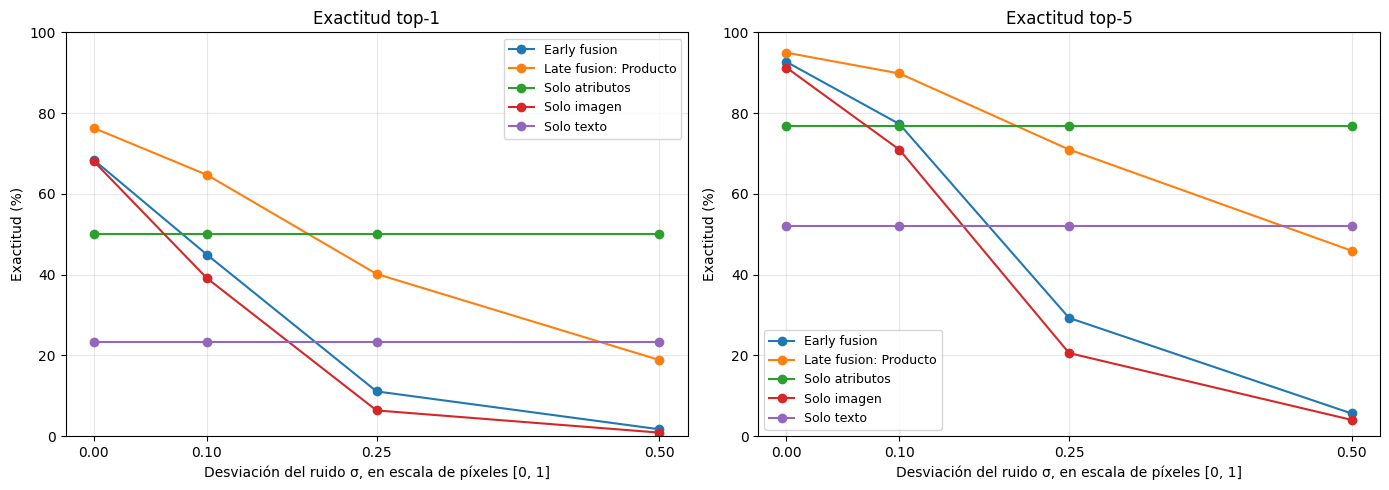

Resultados con sigma=0.50:


,top1,top5,caida_top1_pp,caida_top5_pp
modelo,,,,
Solo imagen,0.0090,0.0404,67.1384,87.2282
Solo texto,0.2337,0.5197,0.0000,0.0000
Solo atributos,0.5007,0.7686,0.0000,0.0000
Early fusion,0.0173,0.0563,66.6552,87.0556
Late fusion: Producto,0.1888,0.4593,57.4215,49.0335


In [ ]:
# ------------------------------------------------------------
# 1. RECUPERAR LOS RESULTADOS SIN RUIDO
# ------------------------------------------------------------
clean_baselines = [
    metrics_img_test,
    metrics_text_test,
    metrics_attribute_test,
    metrics_early_test,
    selected_late_metrics,
]

clean_rows = [
    {
        "sigma": 0.0,
        "modelo": metrics["modelo"],
        "top1": metrics["top1"],
        "top5": metrics["top5"],
        "caida_top1_pp": 0.0,
        "caida_top5_pp": 0.0,
    }
    for metrics in clean_baselines
]


# ------------------------------------------------------------
# 2. UNIR LOS RESULTADOS LIMPIOS Y ALTERADOS
# ------------------------------------------------------------
robustness_plot_data = pd.concat(
    [
        pd.DataFrame(clean_rows),
        robustness_image_results.reset_index(),
    ],
    ignore_index=True,
)

robustness_plot_data = robustness_plot_data.sort_values(
    ["modelo", "sigma"]
)


# ------------------------------------------------------------
# 3. GRAFICAR TOP-1 Y TOP-5
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, group in robustness_plot_data.groupby(
    "modelo", sort=False
):
    for ax, metric in zip(axes, ["top1", "top5"]):
        ax.plot(
            group["sigma"],
            100 * group[metric],
            marker="o",
            label=name,
        )

for ax, title in zip(
    axes,
    ["Exactitud top-1", "Exactitud top-5"],
):
    ax.set_title(title)
    ax.set_xlabel("Desviación del ruido σ, en escala de píxeles [0, 1]")
    ax.set_ylabel("Exactitud (%)")
    ax.set_xticks([0.0] + IMAGE_NOISE_SIGMAS)
    ax.set_ylim(0, 100)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. RESUMIR EL RESULTADO CON EL MAYOR RUIDO
# ------------------------------------------------------------
# Mostramos tanto el desempeño absoluto como su caída.
max_sigma = max(IMAGE_NOISE_SIGMAS)

print(f"Resultados con sigma={max_sigma:.2f}:")

display(
    robustness_image_results
    .xs(max_sigma, level="sigma")
    .round(4)
)

### Síntesis de las curvas de robustez

Con imágenes limpias, late fusion por Producto presenta el mayor
desempeño. Al aumentar el ruido visual, su exactitud disminuye,
aunque conserva mejores resultados que early fusion y solo imagen
en las tres intensidades evaluadas.

En top-1, el clasificador de atributos supera a Producto desde
σ = 0,25. Con σ = 0,50, incluso el clasificador textual obtiene
mayor exactitud que la combinación de las tres modalidades.

Early fusion se degrada de forma similar al modelo visual,
pese a recibir texto y atributos intactos. La presencia de varias
modalidades, por tanto, no asegura que el modelo pueda compensar
una entrada visual alterada.

Estas observaciones muestran una diferencia entre aprovechar
información complementaria en condiciones limpias y resistir
la degradación de una modalidad.

# Parte 4. Red siamesa de imágenes

## 37. Preparación de las particiones por especie

La red siamesa utilizará un encoder compartido para representar
las imágenes y aprender distancias entre ellas.

Reunimos los embeddings originales de las tres particiones
anteriores y construimos una nueva separación:

- Especies originales 1–100: entrenamiento y validación.
- Especies originales 101–200: evaluación, con todas sus imágenes.

Reservamos el 10 % de las imágenes de las primeras 100 especies
para validación, de forma estratificada y con semilla fija.

Nuestras etiquetas están numeradas desde cero. Por tanto,
las especies originales 1–100 corresponden a etiquetas 0–99,
y las especies 101–200 a etiquetas 100–199.

Reutilizamos únicamente los embeddings de ResNet50 congelada.
La cabeza siamesa se inicializará desde cero, sin utilizar los
pesos de los clasificadores entrenados con las 200 especies.

Las especies de evaluación serán nuevas para el entrenamiento
de la cabeza siamesa. Esto no implica que el backbone preentrenado
en ImageNet nunca haya visto esas especies o imágenes relacionadas.


In [ ]:
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. REUNIR LOS EMBEDDINGS LIMPIOS Y SUS IDENTIFICADORES
# ------------------------------------------------------------
# Utilizamos el mismo orden de particiones para todos los arreglos.
split_order = ["train", "val", "test"]

siam_all_embeddings = np.concatenate([
    visual_embeddings[split]
    for split in split_order
], axis=0)

siam_all_labels = np.concatenate([
    prepared[split]["labels"]
    for split in split_order
])

siam_all_ids = np.concatenate([
    prepared[split]["image_ids"]
    for split in split_order
])

siam_all_paths = np.concatenate([
    prepared[split]["image_paths"]
    for split in split_order
])

# Cada fotografía debe aparecer una sola vez.
assert siam_all_embeddings.shape == (11_788, 2048)
assert len(np.unique(siam_all_ids)) == 11_788
assert np.isfinite(siam_all_embeddings).all()


# ------------------------------------------------------------
# 2. SEPARAR LAS ESPECIES VISTAS Y NO VISTAS
# ------------------------------------------------------------
# La numeración interna comienza en cero.
seen_indices = np.flatnonzero(siam_all_labels < 100)
unseen_indices = np.flatnonzero(siam_all_labels >= 100)

assert set(siam_all_labels[seen_indices]) == set(range(100))
assert set(siam_all_labels[unseen_indices]) == set(range(100, 200))


# ------------------------------------------------------------
# 3. DIVIDIR LAS IMÁGENES DE LAS ESPECIES VISTAS
# ------------------------------------------------------------
# Esta división es independiente de los splits de clasificación.
# No modificamos prepared ni visual_embeddings.
siam_train_indices, siam_val_indices = train_test_split(
    seen_indices,
    test_size=0.10,
    stratify=siam_all_labels[seen_indices],
    random_state=SEED,
)

siam_test_indices = unseen_indices


# ------------------------------------------------------------
# 4. ORGANIZAR LAS NUEVAS PARTICIONES
# ------------------------------------------------------------
def select_siamese_partition(indices):
    return {
        "embeddings": siam_all_embeddings[indices],
        "labels": siam_all_labels[indices],
        "image_ids": siam_all_ids[indices],
        "image_paths": siam_all_paths[indices],
    }


siam_data = {
    "train": select_siamese_partition(siam_train_indices),
    "val": select_siamese_partition(siam_val_indices),
    "test": select_siamese_partition(siam_test_indices),
}


# ------------------------------------------------------------
# 5. VERIFICAR LA SEPARACIÓN
# ------------------------------------------------------------
train_classes = set(siam_data["train"]["labels"])
val_classes = set(siam_data["val"]["labels"])
test_classes = set(siam_data["test"]["labels"])

# Train y validación contienen las mismas 100 especies.
assert train_classes == val_classes == set(range(100))

# Ninguna especie de evaluación participa en train o validación.
assert train_classes.isdisjoint(test_classes)
assert val_classes.isdisjoint(test_classes)

# Ninguna fotografía aparece en dos particiones.
partition_ids = {
    split: set(data["image_ids"])
    for split, data in siam_data.items()
}

assert partition_ids["train"].isdisjoint(partition_ids["val"])
assert partition_ids["train"].isdisjoint(partition_ids["test"])
assert partition_ids["val"].isdisjoint(partition_ids["test"])


# ------------------------------------------------------------
# 6. MOSTRAR EL RESUMEN
# ------------------------------------------------------------
summary_siamese = []

for split, data in siam_data.items():
    labels = data["labels"]

    summary_siamese.append({
        "particion": split,
        "imagenes": len(labels),
        "especies": len(np.unique(labels)),
        "especie_original_min": int(labels.min()) + 1,
        "especie_original_max": int(labels.max()) + 1,
    })

display(
    pd.DataFrame(summary_siamese).set_index("particion")
)

print("✓ Particiones de la red siamesa verificadas.")

,imagenes,especies,especie_original_min,especie_original_max
particion,,,,
train,5277,100,1,100
val,587,100,1,100
test,5924,100,101,200


✓ Particiones de la red siamesa verificadas.


## 38. Construcción de lotes P × K

En aprendizaje métrico necesitamos que cada lote contenga ejemplos
de la misma especie y de especies diferentes.

Seleccionamos P = 16 especies y K = 4 imágenes por especie.
Cada observación tendrá tres posibles positivos y 60 negativos
dentro de su lote, excluyéndose a sí misma.

Los lotes de entrenamiento se generan aleatoriamente. Para validación
preparamos una colección fija de lotes, que se reutilizará al comparar
las configuraciones.

Este muestreo no garantiza recorrer cada imagen exactamente una vez
por época. Definimos la longitud de una época como 83 lotes, valor
obtenido al redondear hacia arriba 5.277 / 64.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EL MUESTREO
# ------------------------------------------------------------
P_SPECIES = 16
K_IMAGES = 4
SIAM_BATCH_SIZE = P_SPECIES * K_IMAGES

SIAM_STEPS_PER_EPOCH = int(
    np.ceil(len(siam_data["train"]["labels"]) / SIAM_BATCH_SIZE)
)

SIAM_VAL_STEPS = int(
    np.ceil(len(siam_data["val"]["labels"]) / SIAM_BATCH_SIZE)
)


# ------------------------------------------------------------
# 2. ORGANIZAR LOS ÍNDICES POR ESPECIE
# ------------------------------------------------------------
def build_class_pools(data):
    pools = {
        int(label): np.flatnonzero(data["labels"] == label)
        for label in np.unique(data["labels"])
    }

    assert len(pools) >= P_SPECIES

    # Necesitamos cuatro imágenes distintas por especie.
    assert all(len(indices) >= K_IMAGES for indices in pools.values())

    return pools


train_pools = build_class_pools(siam_data["train"])
val_pools = build_class_pools(siam_data["val"])


# ------------------------------------------------------------
# 3. DEFINIR LA SELECCIÓN DE UN LOTE
# ------------------------------------------------------------
def sample_pk_indices(pools, rng):
    # Elegir 16 especies sin repetirlas dentro del lote.
    chosen_classes = rng.choice(
        np.array(sorted(pools)),
        size=P_SPECIES,
        replace=False,
    )

    # Elegir cuatro imágenes distintas por especie.
    indices = np.concatenate([
        rng.choice(
            pools[int(label)],
            size=K_IMAGES,
            replace=False,
        )
        for label in chosen_classes
    ])

    return indices


# ------------------------------------------------------------
# 4. CONSTRUIR UN DATASET DE ENTRENAMIENTO RECREABLE
# ------------------------------------------------------------
# Lo crearemos nuevamente con la misma semilla para cada
# configuración, facilitando una comparación controlada.
def make_siam_train_dataset(seed=SEED):

    def generator():
        rng = np.random.default_rng(seed)

        while True:
            indices = sample_pk_indices(train_pools, rng)

            yield (
                siam_data["train"]["embeddings"][indices].astype(
                    np.float32
                ),
                siam_data["train"]["labels"][indices].astype(
                    np.int64
                ),
            )

    # Cada elemento generado YA es un lote de 64 observaciones.
    # Por eso no aplicamos batch() otra vez.
    return tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(
                shape=(SIAM_BATCH_SIZE, 2048),
                dtype=tf.float32,
            ),
            tf.TensorSpec(
                shape=(SIAM_BATCH_SIZE,),
                dtype=tf.int64,
            ),
        ),
    ).prefetch(1)


# ------------------------------------------------------------
# 5. PREPARAR LOTES FIJOS DE VALIDACIÓN
# ------------------------------------------------------------
val_rng = np.random.default_rng(SEED + 1)

fixed_val_indices = np.stack([
    sample_pk_indices(val_pools, val_rng)
    for _ in range(SIAM_VAL_STEPS)
])

siam_val_pk_ds = tf.data.Dataset.from_tensor_slices((
    siam_data["val"]["embeddings"][fixed_val_indices].astype(
        np.float32
    ),
    siam_data["val"]["labels"][fixed_val_indices].astype(
        np.int64
    ),
)).prefetch(1)


# ------------------------------------------------------------
# 6. INSPECCIONAR UN LOTE
# ------------------------------------------------------------
siam_train_pk_ds = make_siam_train_dataset()

for embeddings, labels in siam_train_pk_ds.take(1):
    classes, counts = np.unique(
        labels.numpy(),
        return_counts=True,
    )

    assert tuple(embeddings.shape) == (64, 2048)
    assert len(classes) == P_SPECIES
    assert (counts == K_IMAGES).all()

    print("Embeddings:", tuple(embeddings.shape))
    print("Etiquetas:", tuple(labels.shape))
    print("Especies por lote:", len(classes))
    print("Imágenes por especie:", counts.tolist())

print("\nLotes por época de entrenamiento:", SIAM_STEPS_PER_EPOCH)
print("Lotes fijos de validación:", SIAM_VAL_STEPS)
print("✓ Muestreo P × K preparado.")

Embeddings: (64, 2048)
Etiquetas: (64,)
Especies por lote: 16
Imágenes por especie: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]

Lotes por época de entrenamiento: 83
Lotes fijos de validación: 10
✓ Muestreo P × K preparado.


## 39. Encoder compartido de la red siamesa

Construimos la cabeza propuesta en el enunciado:

Embedding visual de 2.048 valores → Dense(512, ReLU)
→ Dense(128) → normalización L2.

El mismo encoder, con los mismos pesos, representará todas las
imágenes. Las pérdidas posteriores buscarán acercar representaciones
de la misma especie y separar representaciones de especies diferentes.

La normalización L2 produce vectores de norma aproximadamente 1.
Entre vectores unitarios, la distancia euclidiana está entre 0 y 2.

Inicializamos esta cabeza desde cero. ResNet50 permanece congelada
y no utilizamos los pesos de los clasificadores anteriores.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR UNA CAPA DE NORMALIZACIÓN L2
# ------------------------------------------------------------
# Siguiendo el ejemplo de CLIP del profesor, encapsulamos
# la normalización en una capa de Keras.
@tf.keras.utils.register_keras_serializable(package="CUB")
class L2Normalize(layers.Layer):
    def call(self, inputs):
        return tf.math.l2_normalize(inputs, axis=-1)


# ------------------------------------------------------------
# 2. DEFINIR EL ENCODER COMPARTIDO
# ------------------------------------------------------------
def build_siamese_encoder():
    return tf.keras.Sequential(
        [
            layers.Input(shape=(2048,)),

            layers.Dense(
                512,
                activation="relu",
                name="hidden_projection",
            ),

            # La proyección final es lineal antes de normalizar.
            layers.Dense(
                128,
                name="embedding_projection",
            ),

            L2Normalize(name="l2_normalization"),
        ],
        name="siamese_encoder",
    )


# ------------------------------------------------------------
# 3. CREAR UNA INSTANCIA INICIAL
# ------------------------------------------------------------
# Reutilizaremos la función para crear encoders nuevos
# al comparar pérdidas y métodos de muestreo.
tf.keras.utils.set_random_seed(SEED)

siam_encoder = build_siamese_encoder()
siam_encoder.summary()


# ------------------------------------------------------------
# 4. COMPROBAR LA SALIDA CON UN LOTE
# ------------------------------------------------------------
for embeddings, labels in siam_train_pk_ds.take(1):

    projected = siam_encoder(
        embeddings,
        training=False,
    )

    assert tuple(projected.shape) == (SIAM_BATCH_SIZE, 128)

    tf.debugging.assert_all_finite(
        projected,
        "El encoder produjo valores no finitos.",
    )

    # Cada fila debe tener norma L2 aproximadamente igual a 1.
    norms = tf.norm(projected, axis=1)

    np.testing.assert_allclose(
        norms.numpy(),
        np.ones(SIAM_BATCH_SIZE),
        atol=1e-5,
    )

    # Una misma entrada debe producir la misma representación
    # al pasar nuevamente por el mismo encoder.
    repeated = siam_encoder(embeddings, training=False)

    np.testing.assert_allclose(
        projected.numpy(),
        repeated.numpy(),
        rtol=1e-5,
        atol=1e-6,
    )

    print("\nForma de salida:", tuple(projected.shape))
    print(
        "Rango de normas L2:",
        f"[{tf.reduce_min(norms).numpy():.6f}, "
        f"{tf.reduce_max(norms).numpy():.6f}]",
    )

print("✓ Encoder compartido definido y comprobado.")


Model: "siamese_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_projection (Dense)       │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_projection (Dense)    │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l2_normalization (L2Normalize)  │ (None, 128)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,114,752 (4.25 MB)

 Trainable params: 1,114,752 (4.25 MB)

 Non-trainable params: 0 (0.00 B)


Forma de salida: (64, 128)
Rango de normas L2: [1.000000, 1.000000]
✓ Encoder compartido definido y comprobado.


## 40. Distancias y pares dentro del lote

Calculamos una matriz de distancias euclidianas entre las
representaciones del lote. Cada posición (i, j) indica la distancia
entre las imágenes i y j.

Definimos como positivos los pares de imágenes distintas de la
misma especie y como negativos los de especies diferentes.
Excluimos la diagonal, porque una imagen no debe utilizarse
como su propio positivo.

Con 16 especies y cuatro imágenes por especie, cada ancla dispone
de tres positivos y 60 negativos.

Esta estructura permitirá seleccionar pares aleatorios o difíciles:
el positivo más lejano y el negativo más cercano de cada ancla.
Todavía no actualizamos los pesos del encoder.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR LAS DISTANCIAS Y MÁSCARAS
# ------------------------------------------------------------
def pairwise_distances_and_masks(projected, labels):

    # Distancia euclidiana al cuadrado:
    # ||a - b||² = ||a||² + ||b||² - 2(a · b).
    squared_norms = tf.reduce_sum(
        tf.square(projected),
        axis=1,
        keepdims=True,
    )

    squared_distances = (
        squared_norms
        + tf.transpose(squared_norms)
        - 2.0 * tf.matmul(projected, projected, transpose_b=True)
    )

    # Corregir posibles valores negativos por redondeo.
    squared_distances = tf.maximum(squared_distances, 0.0)

    # El pequeño límite evita la derivada indefinida de sqrt en 0.
    distances = tf.sqrt(
        tf.maximum(squared_distances, 1e-12)
    )

    # Una imagen tiene distancia cero respecto a sí misma.
    batch_size = tf.shape(projected)[0]
    distances = tf.linalg.set_diag(
        distances,
        tf.zeros([batch_size], dtype=distances.dtype),
    )

    # Comparar las etiquetas de todas las parejas.
    same_species = tf.equal(
        labels[:, None],
        labels[None, :],
    )

    diagonal = tf.eye(batch_size, dtype=tf.bool)

    # Positivos: misma especie, excluyendo la propia imagen.
    positive_mask = tf.logical_and(
        same_species,
        tf.logical_not(diagonal),
    )

    # Negativos: especies distintas.
    negative_mask = tf.logical_not(same_species)

    return distances, positive_mask, negative_mask


# ------------------------------------------------------------
# 2. CALCULAR LAS DISTANCIAS DE UN LOTE
# ------------------------------------------------------------
for embeddings, labels in siam_train_pk_ds.take(1):
    projected = siam_encoder(embeddings, training=False)

    distances, positive_mask, negative_mask = (
        pairwise_distances_and_masks(projected, labels)
    )

    # Verificar la matriz y el número de candidatos por ancla.
    assert tuple(distances.shape) == (64, 64)

    tf.debugging.assert_equal(
        tf.reduce_sum(tf.cast(positive_mask, tf.int32), axis=1),
        K_IMAGES - 1,
    )

    tf.debugging.assert_equal(
        tf.reduce_sum(tf.cast(negative_mask, tf.int32), axis=1),
        SIAM_BATCH_SIZE - K_IMAGES,
    )

    tf.debugging.assert_all_finite(
        distances,
        "Hay distancias no finitas.",
    )


    # --------------------------------------------------------
    # 3. IDENTIFICAR LOS CANDIDATOS BATCH-HARD
    # --------------------------------------------------------
    # Para cada ancla, elegir el positivo más lejano.
    hardest_positive_distance = tf.reduce_max(
        tf.where(positive_mask, distances, -np.inf),
        axis=1,
    )

    # Para cada ancla, elegir el negativo más cercano.
    hardest_negative_distance = tf.reduce_min(
        tf.where(negative_mask, distances, np.inf),
        axis=1,
    )

    print("Matriz de distancias:", tuple(distances.shape))
    print("Positivos por ancla:", K_IMAGES - 1)
    print("Negativos por ancla:", SIAM_BATCH_SIZE - K_IMAGES)

    print(
        "Distancia media de positivos más difíciles:",
        f"{tf.reduce_mean(hardest_positive_distance).numpy():.4f}",
    )
    print(
        "Distancia media de negativos más difíciles:",
        f"{tf.reduce_mean(hardest_negative_distance).numpy():.4f}",
    )

print("\n✓ Distancias y máscaras verificadas.")

Matriz de distancias: (64, 64)
Positivos por ancla: 3
Negativos por ancla: 60
Distancia media de positivos más difíciles: 0.8565
Distancia media de negativos más difíciles: 0.7144

✓ Distancias y máscaras verificadas.


## 41. Pérdidas y selección de pares

Compararemos dos pérdidas:

1. Contrastiva: reduce la distancia entre positivos y penaliza
   los negativos cuya distancia sea menor que un margen.
2. Triplet: exige que el negativo esté más lejos del ancla
   que el positivo, al menos por un margen.

El enunciado define la pérdida contrastiva, pero no desarrolla
la segunda pérdida anunciada. Adoptamos triplet loss como
decisión de implementación.

Para cada pérdida compararemos dos estrategias:
- Aleatoria: un positivo y un negativo por ancla.
- Batch-hard: el positivo más lejano y el negativo más cercano.

Usaremos distancia euclidiana y márgenes iniciales de 1,0 para
contrastiva y 0,2 para triplet. Son hiperparámetros fijados antes
de evaluar en prueba.

In [ ]:
# ------------------------------------------------------------
# 1. FIJAR LOS MÁRGENES INICIALES
# ------------------------------------------------------------
CONTRASTIVE_MARGIN = 1.0
TRIPLET_MARGIN = 0.2


# ------------------------------------------------------------
# 2. SELECCIONAR UN POSITIVO Y UN NEGATIVO POR ANCLA
# ------------------------------------------------------------
def select_pair_distances(
    distances,
    positive_mask,
    negative_mask,
    mining="random",
    seed=(42, 0),
):
    if mining == "hard":
        # Elegir los candidatos más difíciles de cada fila.
        positive_distances = tf.reduce_max(
            tf.where(positive_mask, distances, -np.inf),
            axis=1,
        )

        negative_distances = tf.reduce_min(
            tf.where(negative_mask, distances, np.inf),
            axis=1,
        )

    elif mining == "random":
        # Asignar puntuaciones aleatorias a los candidatos.
        # El máximo de puntuaciones uniformes selecciona
        # uniformemente entre los candidatos válidos.
        seeds = tf.random.experimental.stateless_split(
            tf.convert_to_tensor(seed, dtype=tf.int32),
            num=2,
        )

        positive_scores = tf.random.stateless_uniform(
            tf.shape(distances),
            seed=seeds[0],
        )
        negative_scores = tf.random.stateless_uniform(
            tf.shape(distances),
            seed=seeds[1],
        )

        positive_indices = tf.argmax(
            tf.where(positive_mask, positive_scores, -np.inf),
            axis=1,
            output_type=tf.int32,
        )
        negative_indices = tf.argmax(
            tf.where(negative_mask, negative_scores, -np.inf),
            axis=1,
            output_type=tf.int32,
        )

        # Recuperar una distancia por fila.
        positive_distances = tf.gather(
            distances, positive_indices, axis=1, batch_dims=1
        )
        negative_distances = tf.gather(
            distances, negative_indices, axis=1, batch_dims=1
        )

    else:
        raise ValueError("mining debe ser 'random' o 'hard'.")

    return positive_distances, negative_distances


# ------------------------------------------------------------
# 3. DEFINIR LA PÉRDIDA PARA EL LOTE
# ------------------------------------------------------------
def siamese_batch_loss(
    projected,
    labels,
    loss_name="contrastive",
    mining="random",
    seed=(42, 0),
):
    distances, positive_mask, negative_mask = (
        pairwise_distances_and_masks(projected, labels)
    )

    positive_distances, negative_distances = select_pair_distances(
        distances,
        positive_mask,
        negative_mask,
        mining=mining,
        seed=seed,
    )

    if loss_name == "contrastive":
        # Positivos: d².
        positive_loss = tf.square(positive_distances)

        # Negativos: max(0, margen - d)².
        negative_loss = tf.square(
            tf.nn.relu(CONTRASTIVE_MARGIN - negative_distances)
        )

        # Promediar los dos pares seleccionados por ancla.
        loss = 0.5 * tf.reduce_mean(
            positive_loss + negative_loss
        )

    elif loss_name == "triplet":
        # max(0, distancia positiva - distancia negativa + margen).
        loss = tf.reduce_mean(
            tf.nn.relu(
                positive_distances
                - negative_distances
                + TRIPLET_MARGIN
            )
        )

    else:
        raise ValueError(
            "loss_name debe ser 'contrastive' o 'triplet'."
        )

    return loss, positive_distances, negative_distances


# ------------------------------------------------------------
# 4. COMPROBAR LAS CUATRO CONFIGURACIONES
# ------------------------------------------------------------
for embeddings, labels in siam_val_pk_ds.take(1):
    projected = siam_encoder(embeddings, training=False)

    check_rows = []

    for loss_name in ["contrastive", "triplet"]:
        for mining in ["random", "hard"]:
            loss, positive_distances, negative_distances = (
                siamese_batch_loss(
                    projected,
                    labels,
                    loss_name=loss_name,
                    mining=mining,
                    seed=(SEED, 0),
                )
            )

            tf.debugging.assert_all_finite(
                loss,
                "La pérdida no es finita.",
            )
            tf.debugging.assert_greater_equal(loss, 0.0)

            check_rows.append({
                "perdida": loss_name,
                "muestreo": mining,
                "valor_inicial": float(loss.numpy()),
                "distancia_positiva_media": float(
                    tf.reduce_mean(positive_distances).numpy()
                ),
                "distancia_negativa_media": float(
                    tf.reduce_mean(negative_distances).numpy()
                ),
            })

    display(pd.DataFrame(check_rows).round(4))

print("✓ Pérdidas y selección de pares comprobadas.")

,perdida,muestreo,valor_inicial,distancia_positiva_media,distancia_negativa_media
0,contrastive,random,0.3092,0.7720,0.9480
1,contrastive,hard,0.4101,0.8556,0.7331
2,triplet,random,0.0666,0.7720,0.9480
3,triplet,hard,0.3225,0.8556,0.7331


✓ Pérdidas y selección de pares comprobadas.


## 42. Modelo de entrenamiento para la red siamesa

Encapsulamos el encoder y la pérdida en un modelo personalizado
de Keras, siguiendo la organización del modelo contrastivo
del ejercicio de clase.

En train_step calculamos las representaciones, seleccionamos
positivos y negativos, calculamos la pérdida y actualizamos
los pesos mediante Adam.

En test_step utilizamos el mismo procedimiento sin actualizar
parámetros. Registramos la pérdida y las distancias medias
de los pares seleccionados.

Para el muestreo aleatorio, la semilla cambia entre pasos de
entrenamiento. En validación se repite una secuencia fija de
semillas en cada evaluación.

In [ ]:
# ------------------------------------------------------------
# PASO 42. MODELO DE ENTRENAMIENTO PARA LA RED SIAMESA
# ------------------------------------------------------------
# Seguimos la estructura del modelo contrastivo del profesor:
# train_step calcula gradientes y actualiza los pesos;
# test_step evalúa sin actualizarlos.


# ------------------------------------------------------------
# 1. DEFINIR EL MODELO PERSONALIZADO
# ------------------------------------------------------------
class SiameseTrainingModel(tf.keras.Model):

    def __init__(self, encoder, loss_name, mining):
        super().__init__()

        self.encoder = encoder
        self.loss_name = loss_name
        self.mining = mining

        # Registrar el contador como estado administrado por Keras.
        # Se utiliza para reproducir la selección aleatoria
        # de pares en cada evaluación de validación.
        self.val_step_counter = self.add_weight(
            name="val_step_counter",
            shape=(),
            initializer="zeros",
            trainable=False,
            dtype="int32",
        )

        # Promedios de pérdida y distancias seleccionadas.
        self.loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.positive_tracker = tf.keras.metrics.Mean(name="d_pos")
        self.negative_tracker = tf.keras.metrics.Mean(name="d_neg")

    @property
    def metrics(self):
        # Keras utiliza esta lista para gestionar las métricas.
        return [
            self.loss_tracker,
            self.positive_tracker,
            self.negative_tracker,
        ]

    def reset_metrics(self):
        # Reiniciar los promedios al comenzar cada fase.
        super().reset_metrics()

        # Reiniciar la secuencia de semillas de validación.
        self.val_step_counter.assign(0)

    def call(self, inputs, training=False):
        # Todas las imágenes pasan por el mismo encoder.
        return self.encoder(inputs, training=training)


    # --------------------------------------------------------
    # 2. CALCULAR LA PÉRDIDA Y LAS DISTANCIAS
    # --------------------------------------------------------
    def compute_metric_loss(self, embeddings, labels, training):
        projected = self(
            embeddings,
            training=training,
        )

        if training:
            # El optimizador incrementa iterations en cada paso.
            # Así cambia la selección aleatoria durante entrenamiento.
            step = tf.cast(
                self.optimizer.iterations,
                tf.int32,
            )

            seed = tf.stack([
                tf.constant(SEED, dtype=tf.int32),
                step,
            ])

        else:
            # Los lotes de validación y su secuencia de semillas
            # serán los mismos en cada evaluación.
            step = self.val_step_counter.assign_add(1) - 1

            seed = tf.stack([
                tf.constant(SEED + 1, dtype=tf.int32),
                step,
            ])

        return siamese_batch_loss(
            projected,
            labels,
            loss_name=self.loss_name,
            mining=self.mining,
            seed=seed,
        )


    # --------------------------------------------------------
    # 3. ACTUALIZAR LAS MÉTRICAS
    # --------------------------------------------------------
    def update_trackers(self, loss, positive, negative):
        self.loss_tracker.update_state(loss)

        self.positive_tracker.update_state(
            tf.reduce_mean(positive)
        )

        self.negative_tracker.update_state(
            tf.reduce_mean(negative)
        )


    # --------------------------------------------------------
    # 4. DEFINIR EL PASO DE ENTRENAMIENTO
    # --------------------------------------------------------
    def train_step(self, data):
        embeddings, labels = data

        # Registrar las operaciones para calcular gradientes.
        with tf.GradientTape() as tape:
            loss, positive, negative = self.compute_metric_loss(
                embeddings,
                labels,
                training=True,
            )

            tf.debugging.assert_all_finite(
                loss,
                "La pérdida de entrenamiento no es finita.",
            )

        # Calcular los gradientes de los parámetros del encoder.
        variables = self.trainable_variables
        gradients = tape.gradient(loss, variables)

        # Comprobar que todos los parámetros estén conectados
        # con la pérdida antes de actualizar sus valores.
        if any(gradient is None for gradient in gradients):
            raise ValueError(
                "Hay parámetros entrenables sin gradiente."
            )

        self.optimizer.apply_gradients(
            zip(gradients, variables)
        )

        self.update_trackers(loss, positive, negative)

        return {
            metric.name: metric.result()
            for metric in self.metrics
        }


    # --------------------------------------------------------
    # 5. DEFINIR EL PASO DE VALIDACIÓN
    # --------------------------------------------------------
    def test_step(self, data):
        embeddings, labels = data

        # No utilizamos GradientTape ni actualizamos pesos.
        loss, positive, negative = self.compute_metric_loss(
            embeddings,
            labels,
            training=False,
        )

        tf.debugging.assert_all_finite(
            loss,
            "La pérdida de validación no es finita.",
        )

        self.update_trackers(loss, positive, negative)

        return {
            metric.name: metric.result()
            for metric in self.metrics
        }


# ------------------------------------------------------------
# 6. DEFINIR LA CREACIÓN DE UN EXPERIMENTO INDEPENDIENTE
# ------------------------------------------------------------
def create_siamese_experiment(loss_name, mining):

    # Mantener la misma inicialización entre configuraciones.
    tf.keras.utils.set_random_seed(SEED)

    encoder = build_siamese_encoder()

    model = SiameseTrainingModel(
        encoder=encoder,
        loss_name=loss_name,
        mining=mining,
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3,
        ),

        # Desactivar XLA para evitar el conflicto observado
        # entre los recursos del contador y la ejecución en GPU.
        # Esto no desactiva la GPU.
        jit_compile=False,
    )

    # Construir el modelo mediante una entrada de ejemplo.
    model(
        tf.zeros((1, 2048), dtype=tf.float32),
        training=False,
    )

    return model


# ------------------------------------------------------------
# 7. CREAR UNA INSTANCIA DE COMPROBACIÓN
# ------------------------------------------------------------
siam_check_model = create_siamese_experiment(
    loss_name="contrastive",
    mining="random",
)


# ------------------------------------------------------------
# 8. EVALUAR SIN ENTRENAR
# ------------------------------------------------------------
# Utilizamos los diez lotes fijos de validación.
# Esta operación no modifica los pesos del encoder.
check_metrics = siam_check_model.evaluate(
    siam_val_pk_ds,
    verbose=0,
    return_dict=True,
)

print("Comprobación inicial en validación:")

for name, value in check_metrics.items():
    print(f"{name}: {value:.4f}")

print("\n✓ Modelo de entrenamiento preparado.")
print("✓ Comprobación realizada sin actualizar los pesos.")

Comprobación inicial en validación:
d_neg: 0.9292
d_pos: 0.7823
loss: 0.3193

✓ Modelo de entrenamiento preparado.
✓ Comprobación realizada sin actualizar los pesos.


## 43. Entrenamiento de las configuraciones siamesas

Entrenamos cuatro encoders independientes:

- Pérdida contrastiva con selección aleatoria.
- Pérdida contrastiva con selección batch-hard.
- Pérdida triplet con selección aleatoria.
- Pérdida triplet con selección batch-hard.

Cada configuración comienza con los mismos pesos iniciales,
el mismo generador de lotes P × K y el mismo optimizador.

Definimos un máximo de 30 épocas, con 83 lotes por época.
Detenemos cada entrenamiento después de cinco épocas sin mejorar
su pérdida de validación y restauramos los mejores pesos del encoder.

La pérdida permite seleccionar épocas dentro de una configuración.
No compararemos directamente sus valores entre pérdidas diferentes:
la comparación de encoders se realizará posteriormente con Recall@K
en validación. Las especies de prueba no participan en la selección.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EARLY STOPPING SOLO PARA EL ENCODER
# ------------------------------------------------------------
class EncoderEarlyStopping(tf.keras.callbacks.Callback):
    def __init__(self, patience=5):
        super().__init__()
        self.patience = patience

    def on_train_begin(self, logs=None):
        self.best_loss = np.inf
        self.best_epoch = None
        self.best_weights = None
        self.wait = 0

    def on_epoch_end(self, epoch, logs=None):
        current = float(logs["val_loss"])

        if not np.isfinite(current):
            raise ValueError("La pérdida de validación no es finita.")

        if current < self.best_loss:
            self.best_loss = current
            self.best_epoch = epoch + 1

            # Guardar solo el encoder, excluyendo el contador.
            self.best_weights = self.model.encoder.get_weights()
            self.wait = 0
        else:
            self.wait += 1

            if self.wait >= self.patience:
                self.model.stop_training = True
                print(f"\nEarlyStopping en época {epoch + 1}.")

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.encoder.set_weights(self.best_weights)

            print(
                "Pesos del encoder restaurados de la época",
                self.best_epoch,
            )


# ------------------------------------------------------------
# 2. DEFINIR LOS EXPERIMENTOS
# ------------------------------------------------------------
SIAM_EPOCHS = 30

siam_configurations = [
    ("contrastive", "random"),
    ("contrastive", "hard"),
    ("triplet", "random"),
    ("triplet", "hard"),
]

siam_models = {}
siam_histories = {}
siam_training_rows = []


# ------------------------------------------------------------
# 3. ENTRENAR CADA CONFIGURACIÓN DESDE CERO
# ------------------------------------------------------------
for loss_name, mining in siam_configurations:
    experiment_name = f"{loss_name}_{mining}"

    print(f"\n{'=' * 55}")
    print("Experimento:", experiment_name)

    model = create_siamese_experiment(
        loss_name=loss_name,
        mining=mining,
    )

    # Recrear el generador con la misma semilla para cada modelo.
    train_dataset = make_siam_train_dataset(seed=SEED)

    stopping = EncoderEarlyStopping(patience=5)

    history = model.fit(
        train_dataset,
        steps_per_epoch=SIAM_STEPS_PER_EPOCH,
        validation_data=siam_val_pk_ds,
        epochs=SIAM_EPOCHS,
        callbacks=[stopping],
        verbose=2,
    )

    # Conservar los modelos con sus mejores pesos restaurados.
    siam_models[experiment_name] = model
    siam_histories[experiment_name] = history

    siam_training_rows.append({
        "configuracion": experiment_name,
        "epocas_ejecutadas": len(history.epoch),
        "epoca_seleccionada": stopping.best_epoch,
        "menor_val_loss": stopping.best_loss,
    })


# ------------------------------------------------------------
# 4. MOSTRAR EL RESUMEN DE ENTRENAMIENTO
# ------------------------------------------------------------
siam_training_summary = pd.DataFrame(
    siam_training_rows
).set_index("configuracion")

display(siam_training_summary.round(4))

print("\n✓ Cuatro encoders entrenados.")
print("La comparación por Recall@K se realizará en el siguiente paso.")


Experimento: contrastive_random
Epoch 1/30
83/83 - 5s - 55ms/step - d_neg: 0.7777 - d_pos: 0.3544 - loss: 0.1316 - val_d_neg: 0.8464 - val_d_pos: 0.3325 - val_loss: 0.1058
Epoch 2/30
83/83 - 1s - 11ms/step - d_neg: 0.8593 - d_pos: 0.3138 - loss: 0.0956 - val_d_neg: 0.9088 - val_d_pos: 0.3337 - val_loss: 0.0945
Epoch 3/30
83/83 - 1s - 11ms/step - d_neg: 0.8945 - d_pos: 0.2911 - loss: 0.0845 - val_d_neg: 0.9102 - val_d_pos: 0.3218 - val_loss: 0.0921
Epoch 4/30
83/83 - 1s - 12ms/step - d_neg: 0.9285 - d_pos: 0.2728 - loss: 0.0742 - val_d_neg: 0.9043 - val_d_pos: 0.2979 - val_loss: 0.0875
Epoch 5/30
83/83 - 1s - 9ms/step - d_neg: 0.9599 - d_pos: 0.2565 - loss: 0.0676 - val_d_neg: 0.9494 - val_d_pos: 0.3095 - val_loss: 0.0872
Epoch 6/30
83/83 - 1s - 11ms/step - d_neg: 0.9749 - d_pos: 0.2397 - loss: 0.0614 - val_d_neg: 0.9974 - val_d_pos: 0.3111 - val_loss: 0.0848
Epoch 7/30
83/83 - 1s - 10ms/step - d_neg: 1.0113 - d_pos: 0.2253 - loss: 0.0541 - val_d_neg: 0.9974 - val_d_pos: 0.3028 - val_l

,epocas_ejecutadas,epoca_seleccionada,menor_val_loss
configuracion,,,
contrastive_random,19,14,0.0758
contrastive_hard,14,9,0.2410
triplet_random,18,13,0.0140
triplet_hard,19,14,0.1630



✓ Cuatro encoders entrenados.
La comparación por Recall@K se realizará en el siguiente paso.


## 44. Comparación de los encoders mediante Recall@K en validación

Representamos las 587 imágenes de validación con cada encoder.
Para cada imagen buscamos sus vecinos más cercanos entre las demás
imágenes de validación, excluyendo siempre la propia imagen.

Recall@K mide la proporción de consultas que tienen al menos una
imagen de su misma especie entre sus K vecinos más cercanos.
Utilizamos K = 1, 2, 4 y 8.

Seleccionamos la configuración por Recall@1 de validación.
Si hay empate, utilizamos Recall@2, Recall@4 y Recall@8, en ese orden.

También evaluamos los embeddings originales de ResNet50 como
referencia, sin utilizarlos como candidato de selección entre
las cuatro cabezas entrenadas.

Las especies 101–200 permanecen reservadas para evaluación final.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR RECALL@K
# ------------------------------------------------------------
def retrieval_recall_at_k(embeddings, labels, ks=(1, 2, 4, 8)):
    vectors = np.asarray(embeddings, dtype=np.float32)
    labels = np.asarray(labels)

    assert vectors.ndim == 2
    assert len(vectors) == len(labels)
    assert len(vectors) > max(ks)
    assert np.isfinite(vectors).all()

    # Normalizar también la referencia de ResNet50.
    # Para vectores unitarios, ordenar por similitud coseno
    # equivale a ordenar por distancia euclidiana.
    norms = np.linalg.norm(vectors, axis=1, keepdims=True)
    assert (norms > 0).all()
    vectors = vectors / norms

    # Calcular similitudes entre todas las imágenes.
    similarities = vectors @ vectors.T

    # Excluir la propia imagen de los vecinos candidatos.
    np.fill_diagonal(similarities, -np.inf)

    # Ordenar de mayor a menor similitud.
    neighbors = np.argsort(
        -similarities,
        axis=1,
        kind="stable",
    )[:, :max(ks)]

    same_species = labels[neighbors] == labels[:, None]

    return {
        f"recall@{k}": float(
            same_species[:, :k].any(axis=1).mean()
        )
        for k in ks
    }


# ------------------------------------------------------------
# 2. EVALUAR LA REFERENCIA SIN CABEZA ENTRENADA
# ------------------------------------------------------------
val_embeddings = siam_data["val"]["embeddings"]
val_labels = siam_data["val"]["labels"]

reference_recall = retrieval_recall_at_k(
    val_embeddings,
    val_labels,
)

print("Referencia ResNet50:")
display(pd.DataFrame([reference_recall]).round(4))


# ------------------------------------------------------------
# 3. EVALUAR LOS CUATRO ENCODERS
# ------------------------------------------------------------
siam_val_representations = {}
siam_val_rows = []

for name, model in siam_models.items():
    # Inferencia sobre todas las imágenes de validación,
    # no únicamente sobre los lotes P × K muestreados.
    representations = model.encoder.predict(
        val_embeddings,
        batch_size=128,
        verbose=0,
    )

    assert representations.shape == (len(val_labels), 128)

    siam_val_representations[name] = representations

    recalls = retrieval_recall_at_k(
        representations,
        val_labels,
    )

    siam_val_rows.append({
        "configuracion": name,
        **recalls,
    })


# ------------------------------------------------------------
# 4. SELECCIONAR SOLO CON VALIDACIÓN
# ------------------------------------------------------------
siam_val_results = pd.DataFrame(
    siam_val_rows
).sort_values(
    ["recall@1", "recall@2", "recall@4", "recall@8"],
    ascending=False,
    kind="stable",
).reset_index(drop=True)

display(siam_val_results.round(4))

best_siam_name = siam_val_results.loc[0, "configuracion"]
best_siam_encoder = siam_models[best_siam_name].encoder

print("\nConfiguración seleccionada:", best_siam_name)
print("✓ Selección realizada sin utilizar las especies de prueba.")

Referencia ResNet50:


,recall@1,recall@2,recall@4,recall@8
0,0.4532,0.552,0.6882,0.8092


,configuracion,recall@1,recall@2,recall@4,recall@8
0,triplet_hard,0.6576,0.7666,0.8688,0.9319
1,contrastive_hard,0.6474,0.7564,0.8467,0.9216
2,triplet_random,0.5060,0.6440,0.7751,0.8859
3,contrastive_random,0.4651,0.6031,0.7359,0.8382



Configuración seleccionada: triplet_hard
✓ Selección realizada sin utilizar las especies de prueba.


### Comparación de configuraciones en validación

Triplet con batch-hard obtuvo el mayor Recall@1 de validación:
65,76 %. Fue seleccionado antes de evaluar las especies reservadas.

Batch-hard superó al muestreo aleatorio con ambas pérdidas.
En esta ejecución, la selección de ejemplos difíciles mostró
una diferencia mayor que el cambio entre las dos pérdidas.

La ventaja de triplet-hard sobre contrastive-hard fue de
1,02 puntos porcentuales, equivalente a seis consultas entre
las 587 imágenes de validación. Una sola ejecución no permite
establecer la estabilidad de esa diferencia.

Estos resultados corresponden a imágenes nuevas de las especies
1–100. La generalización a las especies 101–200 se evaluará
por separado.

## 45. Recuperación en especies no vistas durante el entrenamiento

Evaluamos las 5.924 imágenes de las especies originales 101–200.
Cada imagen actúa como consulta y busca vecinos entre las demás,
excluyéndose a sí misma.

Reportamos Recall@1, @2, @4 y @8 para las cuatro configuraciones
y para ResNet50 como referencia. Conservamos la configuración
seleccionada en validación, aunque otra obtenga mayor resultado
en prueba.

Las especies son nuevas para las cabezas entrenadas en esta sección;
el backbone mantiene su preentrenamiento externo en ImageNet.

In [ ]:
# ------------------------------------------------------------
# 1. RECUPERAR LOS DATOS DE LAS ESPECIES RESERVADAS
# ------------------------------------------------------------
siam_test_embeddings = siam_data["test"]["embeddings"]
siam_test_labels = siam_data["test"]["labels"]

assert len(siam_test_labels) == 5_924
assert set(siam_test_labels) == set(range(100, 200))


# ------------------------------------------------------------
# 2. EVALUAR RESNET50 COMO REFERENCIA
# ------------------------------------------------------------
reference_test_recall = retrieval_recall_at_k(
    siam_test_embeddings,
    siam_test_labels,
)

siam_test_rows = [{
    "configuracion": "ResNet50 referencia",
    "seleccionada_en_val": False,
    **reference_test_recall,
}]


# ------------------------------------------------------------
# 3. EVALUAR LOS CUATRO ENCODERS SIN ACTUALIZAR PESOS
# ------------------------------------------------------------
siam_test_representations = {}

for name, model in siam_models.items():
    print("Evaluando:", name)

    # Inferencia directa por bloques para evitar crear funciones
    # de predict adicionales dentro del bucle.
    representations = np.concatenate([
        model.encoder(
            siam_test_embeddings[start:start + 128],
            training=False,
        ).numpy()
        for start in range(0, len(siam_test_embeddings), 128)
    ], axis=0)

    assert representations.shape == (5_924, 128)
    assert np.isfinite(representations).all()

    siam_test_representations[name] = representations

    recalls = retrieval_recall_at_k(
        representations,
        siam_test_labels,
    )

    siam_test_rows.append({
        "configuracion": name,
        "seleccionada_en_val": name == best_siam_name,
        **recalls,
    })


# ------------------------------------------------------------
# 4. MOSTRAR LA COMPARACIÓN FINAL
# ------------------------------------------------------------
# Conservamos el orden de los experimentos, sin seleccionar
# nuevamente por sus resultados de prueba.
siam_test_results = pd.DataFrame(
    siam_test_rows
).set_index("configuracion")

display(siam_test_results.round(4))

# Representación seleccionada para la visualización posterior.
best_siam_test_embeddings = siam_test_representations[
    best_siam_name
]

print("\nSelección mantenida desde validación:", best_siam_name)
print("✓ Evaluación de especies reservadas completada.")

Evaluando: contrastive_random
Evaluando: contrastive_hard
Evaluando: triplet_random
Evaluando: triplet_hard


,seleccionada_en_val,recall@1,recall@2,recall@4,recall@8
configuracion,,,,,
ResNet50 referencia,False,0.4975,0.6330,0.7507,0.8491
contrastive_random,False,0.2171,0.3140,0.4431,0.5825
contrastive_hard,False,0.4097,0.5380,0.6624,0.7782
triplet_random,False,0.4110,0.5402,0.6730,0.7814
triplet_hard,True,0.4218,0.5447,0.6774,0.7844



Selección mantenida desde validación: triplet_hard
✓ Evaluación de especies reservadas completada.


### Recuperación en especies no vistas

Triplet-hard, seleccionado mediante validación, obtuvo Recall@1
del 42,18 % y Recall@8 del 78,44 % en las especies 101–200.
ResNet50 sin cabeza entrenada alcanzó 49,75 % y 84,91 %,
respectivamente.

Todas las cabezas entrenadas presentaron menor recuperación que
la referencia en las cuatro métricas. Estos resultados son
compatibles con una especialización de las representaciones
en las especies utilizadas para entrenar, sin una mejora de
transferencia a las especies reservadas.

La validación utilizó imágenes distintas de las mismas especies
de entrenamiento; por tanto, no reproducía el cambio de especies
de la evaluación final. Esta diferencia limita su capacidad
para anticipar la generalización a especies nuevas.

Los valores de validación y prueba tampoco son directamente
comparables: difieren tanto las especies como el tamaño de
la galería y el número de ejemplos disponibles por especie.

El resultado no invalida el procedimiento: muestra que, bajo
esta configuración, el aprendizaje métrico no superó las
representaciones preentrenadas de referencia.

## 46. Visualización de diez especies mediante PCA

Seleccionamos diez especies de prueba con semilla fija y proyectamos
sus representaciones a dos dimensiones mediante PCA.

Mostramos las mismas fotografías en ambas representaciones.
Cada PCA se ajusta por separado y se utiliza únicamente para
visualización; no modifica los modelos ni sus resultados.

La figura resume una parte de la variación de los embeddings.
La separación visual en dos dimensiones no sustituye Recall@K.

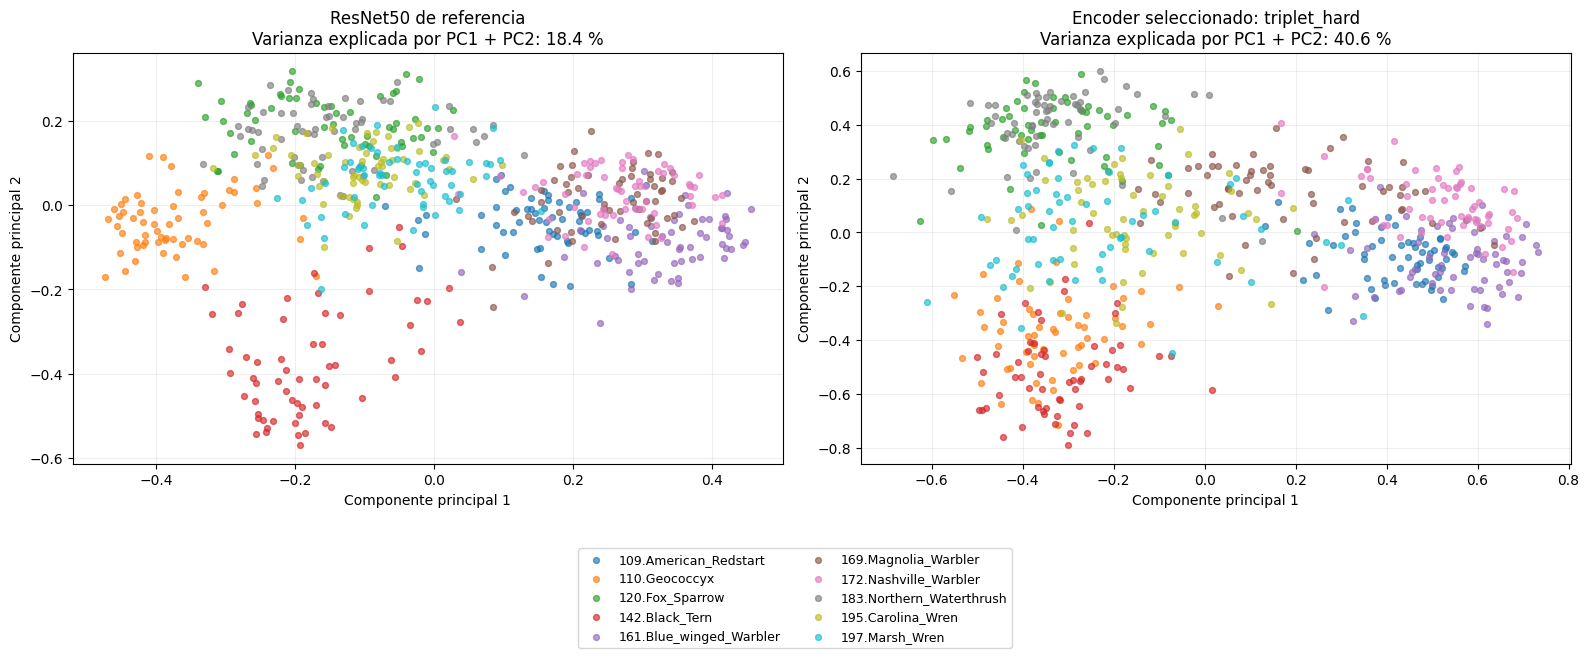

Imágenes representadas: 599
✓ Visualización realizada sin modificar los modelos.


In [ ]:
from sklearn.decomposition import PCA

# ------------------------------------------------------------
# 1. ELEGIR DIEZ ESPECIES SIN INSPECCIONAR SU DESEMPEÑO
# ------------------------------------------------------------
plot_rng = np.random.default_rng(SEED)

plot_species = np.sort(
    plot_rng.choice(
        np.unique(siam_test_labels),
        size=10,
        replace=False,
    )
)

plot_mask = np.isin(siam_test_labels, plot_species)
plot_labels = siam_test_labels[plot_mask]


# ------------------------------------------------------------
# 2. PREPARAR LAS DOS REPRESENTACIONES
# ------------------------------------------------------------
plot_representations = {
    "ResNet50 de referencia": siam_test_embeddings[plot_mask],
    f"Encoder seleccionado: {best_siam_name}":
        best_siam_test_embeddings[plot_mask],
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
colors = plt.get_cmap("tab10")

for ax, (title, vectors) in zip(
    axes, plot_representations.items()
):
    # Normalizar ambas representaciones, como en la recuperación.
    vectors = vectors / np.linalg.norm(
        vectors, axis=1, keepdims=True
    )

    # Ajustar PCA solo para esta visualización.
    pca = PCA(n_components=2, svd_solver="full")
    coordinates = pca.fit_transform(vectors)

    # Mantener el mismo color por especie en ambas figuras.
    for color_idx, label in enumerate(plot_species):
        mask = plot_labels == label

        ax.scatter(
            coordinates[mask, 0],
            coordinates[mask, 1],
            s=18,
            alpha=0.65,
            color=colors(color_idx),
            label=class_names[int(label)],
        )

    explained = 100 * pca.explained_variance_ratio_.sum()

    ax.set_title(
        f"{title}\n"
        f"Varianza explicada por PC1 + PC2: {explained:.1f} %"
    )
    ax.set_xlabel("Componente principal 1")
    ax.set_ylabel("Componente principal 2")
    ax.grid(alpha=0.2)

# Una leyenda compartida con los colores de las diez especies.
handles, legend_labels = axes[1].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

print("Imágenes representadas:", int(plot_mask.sum()))
print("✓ Visualización realizada sin modificar los modelos.")

### Interpretación de la proyección PCA

Las dos primeras componentes explican el 18,4 % de la varianza
de los embeddings de ResNet50 y el 40,6 % de los del encoder
triplet-hard, para las diez especies seleccionadas.

Este aumento indica que una mayor proporción de la variación
del encoder entrenado se concentra en dos direcciones. No implica
que esas direcciones separen mejor las especies.

En ambas figuras se observan agrupamientos parciales y regiones
de solapamiento. Por ejemplo, Geococcyx y Black Tern presentan
mayor proximidad visual en la proyección del encoder entrenado.
Sin embargo, los ejes de cada PCA se ajustaron por separado
y no son directamente equivalentes.

La visualización utiliza solo diez especies y dos dimensiones.
La evaluación cuantitativa sobre las 100 especies reservadas
mostró menor Recall@1 para triplet-hard (42,18 %) que para
ResNet50 de referencia (49,75 %).

# Parte 5. Modelo tipo CLIP imagen–texto

## 47. Separación por especies y recuperación del texto original

Entrenaremos dos encoders independientes para relacionar fotografías
con sus propias descripciones en un espacio compartido.

Utilizamos la alternativa de separación permitida por el enunciado:
especies originales 1–150 para entrenamiento y validación, y
151–200 para evaluación zero-shot. Reservamos el 10 % de las
imágenes de las especies de entrenamiento para validación.

Esta separación no reproduce exactamente las listas de Reed.
Las etiquetas se utilizarán para definir las particiones y evaluar,
pero no como objetivo de la pérdida contrastiva.

Reutilizamos los embeddings de ResNet50 congelada. Los encoders
de proyección visual y de texto se inicializarán desde cero.

Necesitamos recuperar las descripciones originales para construir
el vocabulario exclusivamente con el nuevo entrenamiento. Los IDs
del primer taller no permiten recuperar palabras sustituidas por
<unk> ni el texto eliminado por truncamiento.

In [ ]:
from pathlib import Path
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. REUNIR LOS IDENTIFICADORES DE TODAS LAS IMÁGENES
# ------------------------------------------------------------
# Reutilizamos los arreglos reunidos para la red siamesa.
# Incluyen las 11.788 fotografías y sus embeddings limpios.
assert siam_all_embeddings.shape == (11_788, 2048)
assert len(np.unique(siam_all_ids)) == 11_788


# ------------------------------------------------------------
# 2. DEFINIR EL SPLIT ALTERNATIVO AUTORIZADO
# ------------------------------------------------------------
# Etiquetas internas 0...149 → especies originales 1...150.
# Etiquetas internas 150...199 → especies originales 151...200.
clip_seen_indices = np.flatnonzero(siam_all_labels < 150)
clip_test_indices = np.flatnonzero(siam_all_labels >= 150)

clip_train_indices, clip_val_indices = train_test_split(
    clip_seen_indices,
    test_size=0.10,
    stratify=siam_all_labels[clip_seen_indices],
    random_state=SEED,
)

clip_indices = {
    "train": clip_train_indices,
    "val": clip_val_indices,
    "test": clip_test_indices,
}


# ------------------------------------------------------------
# 3. COMPROBAR LA SEPARACIÓN
# ------------------------------------------------------------
clip_train_classes = set(siam_all_labels[clip_train_indices])
clip_val_classes = set(siam_all_labels[clip_val_indices])
clip_test_classes = set(siam_all_labels[clip_test_indices])

assert clip_train_classes == clip_val_classes == set(range(150))
assert clip_test_classes == set(range(150, 200))
assert clip_train_classes.isdisjoint(clip_test_classes)

# Verificar que ninguna imagen aparezca en dos particiones.
for first, second in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test"),
]:
    assert set(clip_indices[first]).isdisjoint(
        set(clip_indices[second])
    )


# ------------------------------------------------------------
# 4. MOSTRAR LOS TAMAÑOS
# ------------------------------------------------------------
clip_split_rows = []

for split, indices in clip_indices.items():
    labels = siam_all_labels[indices]

    clip_split_rows.append({
        "particion": split,
        "imagenes": len(indices),
        "especies": len(np.unique(labels)),
        "especie_original_min": int(labels.min()) + 1,
        "especie_original_max": int(labels.max()) + 1,
    })

display(
    pd.DataFrame(clip_split_rows).set_index("particion")
)


# ------------------------------------------------------------
# 5. BUSCAR LAS DESCRIPCIONES ORIGINALES
# ------------------------------------------------------------
# Revisamos ubicaciones habituales sin descargar nada todavía.
caption_candidates = [
    Path("/content/data/text"),
    Path("/content/content/data/text"),
    Path("/content/text"),
    Path("/content/content/text"),
    Path("/content/data/text_c10"),
    Path("/content/content/data/text_c10"),
]

# Elegimos una carpeta que contenga la caption de una imagen.
example_relative_caption = Path(
    str(siam_all_paths[0])
).with_suffix(".txt")

CLIP_CAPTIONS_DIR = next(
    (
        folder
        for folder in caption_candidates
        if (folder / example_relative_caption).is_file()
    ),
    None,
)

if CLIP_CAPTIONS_DIR is None:
    print(
        "\nNo se encontraron las captions originales. "
        "El siguiente paso será recuperarlas del archivo "
        "birds_attngan.zip utilizado en el primer taller."
    )
else:
    print("\nCarpeta de captions encontrada:", CLIP_CAPTIONS_DIR)

print("\n✓ Particiones de CLIP preparadas.")

,imagenes,especies,especie_original_min,especie_original_max
particion,,,,
train,7939,150,1,150
val,883,150,1,150
test,2966,50,151,200



No se encontraron las captions originales. El siguiente paso será recuperarlas del archivo birds_attngan.zip utilizado en el primer taller.

✓ Particiones de CLIP preparadas.


## 48. Recuperación de las descripciones originales

Recuperamos las diez descripciones originales por fotografía desde
el archivo de metadatos de AttnGAN utilizado en el primer taller.

Extraemos únicamente los archivos de texto y verificamos que cada
imagen tenga diez descripciones no vacías. No utilizamos las
particiones de AttnGAN: conservamos el split de CLIP ya definido.

En este paso todavía no construimos el vocabulario.

In [ ]:
%pip -q install gdown

In [ ]:
from pathlib import Path
import zipfile
import io
import shutil
import gdown

# ------------------------------------------------------------
# 1. LOCALIZAR O DESCARGAR EL ARCHIVO DE CAPTIONS
# ------------------------------------------------------------
CLIP_TEXT_ROOT = Path("/content/data/clip_captions")
CLIP_TEXT_ROOT.mkdir(parents=True, exist_ok=True)

archive_candidates = [
    Path("/content/data/birds_attngan.zip"),
    Path("/content/birds_attngan.zip"),
    PREPARED_DIR.parent / "birds_attngan.zip",
]

CAPTIONS_ZIP = next(
    (path for path in archive_candidates if path.is_file()),
    None,
)

if CAPTIONS_ZIP is None:
    CAPTIONS_ZIP = Path("/content/data/birds_attngan.zip")

    # Mismo archivo utilizado en el primer taller.
    result = gdown.download(
        id="1O_LtUP9sch09QH3s_EBAgLEctBQ5JBSJ",
        output=str(CAPTIONS_ZIP),
        quiet=False,
    )

    if result is None:
        raise RuntimeError("No se pudo descargar el archivo de captions.")


# ------------------------------------------------------------
# 2. ABRIR EL ZIP INTERNO Y EXTRAER LOS TEXTOS ESPERADOS
# ------------------------------------------------------------
# Copiamos cada archivo a una ruta construida desde nuestras
# imágenes, conservando la correspondencia imagen–descripción.
CLIP_CAPTIONS_DIR = CLIP_TEXT_ROOT / "text"

with zipfile.ZipFile(CAPTIONS_ZIP) as outer_archive:
    damaged = outer_archive.testzip()
    if damaged is not None:
        raise ValueError(f"Archivo dañado en el ZIP principal: {damaged}")

    inner_bytes = outer_archive.read("birds/text.zip")

with zipfile.ZipFile(io.BytesIO(inner_bytes)) as text_archive:
    damaged = text_archive.testzip()
    if damaged is not None:
        raise ValueError(f"Archivo dañado en text.zip: {damaged}")

    available_names = set(text_archive.namelist())

    for relative_image in siam_all_paths:
        relative_caption = Path(
            str(relative_image)
        ).with_suffix(".txt")

        archive_name = "text/" + relative_caption.as_posix()

        if archive_name not in available_names:
            raise FileNotFoundError(
                f"Falta la descripción: {archive_name}"
            )

        destination = CLIP_CAPTIONS_DIR / relative_caption
        destination.parent.mkdir(parents=True, exist_ok=True)

        with text_archive.open(archive_name) as source:
            with destination.open("wb") as target:
                shutil.copyfileobj(source, target)


# ------------------------------------------------------------
# 3. LEER LAS DESCRIPCIONES EN EL ORDEN COMÚN
# ------------------------------------------------------------
clip_all_captions = []

for relative_image in siam_all_paths:
    caption_path = CLIP_CAPTIONS_DIR / Path(
        str(relative_image)
    ).with_suffix(".txt")

    captions = [
        line.strip()
        for line in caption_path.read_text(
            encoding="utf-8"
        ).splitlines()
        if line.strip()
    ]

    if len(captions) != 10:
        raise ValueError(
            f"{caption_path}: se encontraron {len(captions)} "
            "descripciones; se esperaban diez."
        )

    clip_all_captions.append(captions)

assert len(clip_all_captions) == len(siam_all_ids)


# ------------------------------------------------------------
# 4. MOSTRAR EL RESULTADO Y UN EJEMPLO DE ENTRENAMIENTO
# ------------------------------------------------------------
example_idx = int(clip_indices["train"][0])

print("Imágenes con captions:", len(clip_all_captions))
print("Descripciones totales:", sum(map(len, clip_all_captions)))
print("\nEjemplo de entrenamiento:", siam_all_paths[example_idx])
print("Primera descripción original:")
print(clip_all_captions[example_idx][0])

print("\n✓ Captions originales recuperadas y verificadas.")

Downloading...
From (original): https://drive.google.com/uc?id=1O_LtUP9sch09QH3s_EBAgLEctBQ5JBSJ
From (redirected): https://drive.google.com/uc?id=1O_LtUP9sch09QH3s_EBAgLEctBQ5JBSJ&confirm=t&uuid=895ec809-ee25-46a2-9024-274278cdabf1
To: /content/data/birds_attngan.zip
100%|██████████| 6.49M/6.49M [00:00<00:00, 31.0MB/s]


Imágenes con captions: 11788
Descripciones totales: 117880

Ejemplo de entrenamiento: 057.Rose_breasted_Grosbeak/Rose_Breasted_Grosbeak_0010_39238.jpg
Primera descripción original:
the bird has black throat, crown, nape and wingbars, and the breast is red and belly is white.

✓ Captions originales recuperadas y verificadas.


## 49. Vocabulario y codificación del texto para CLIP

Construimos un vocabulario nuevo con las diez descripciones de
cada una de las 7.939 imágenes de entrenamiento de CLIP.

Reservamos <pad> = 0 y <unk> = 1 e incluimos palabras con al menos
dos apariciones. Calculamos la longitud máxima mediante el
percentil 95 de las longitudes de entrenamiento, redondeado
hacia arriba.

Validación y prueba se codifican con ese mismo vocabulario
y longitud máxima, sin reajustarlos. Conservamos las diez
descripciones por imagen para seleccionar una durante
entrenamiento y utilizar todas al construir los prototipos
textuales de evaluación.

Estas variables llevan el prefijo clip_ para no modificar
la preparación de los experimentos anteriores.

In [ ]:
import re
from collections import Counter

# ------------------------------------------------------------
# 1. LIMPIAR Y TOKENIZAR LAS DESCRIPCIONES
# ------------------------------------------------------------
# Esta operación no aprende estadísticas del corpus.
def clip_tokenize(text):
    return re.findall(r"[a-z]+", text.lower())


clip_all_tokens = [
    [clip_tokenize(caption) for caption in captions]
    for captions in clip_all_captions
]


# ------------------------------------------------------------
# 2. CONTAR PALABRAS SOLO EN ENTRENAMIENTO
# ------------------------------------------------------------
clip_train_token_lists = [
    tokens
    for index in clip_indices["train"]
    for tokens in clip_all_tokens[int(index)]
]

assert len(clip_train_token_lists) == 7_939 * 10

clip_word_counts = Counter(
    word
    for tokens in clip_train_token_lists
    for word in tokens
)

clip_vocab = {"<pad>": 0, "<unk>": 1}

clip_retained_words = sorted(
    word
    for word, count in clip_word_counts.items()
    if count >= 2
)

clip_vocab.update({
    word: index
    for index, word in enumerate(clip_retained_words, start=2)
})

clip_id_to_word = {
    index: word
    for word, index in clip_vocab.items()
}

CLIP_VOCAB_SIZE = len(clip_vocab)


# ------------------------------------------------------------
# 3. CALCULAR LA LONGITUD MÁXIMA CON ENTRENAMIENTO
# ------------------------------------------------------------
clip_train_lengths = np.asarray([
    len(tokens)
    for tokens in clip_train_token_lists
])

CLIP_MAX_LEN = max(
    1,
    int(np.ceil(np.percentile(clip_train_lengths, 95))),
)

print("Descripciones de entrenamiento:", len(clip_train_token_lists))
print("Tamaño del vocabulario:", CLIP_VOCAB_SIZE)
print("Longitud máxima:", CLIP_MAX_LEN)

print(
    "Descripciones de entrenamiento que se truncarán:",
    f"{(clip_train_lengths > CLIP_MAX_LEN).mean():.2%}",
)


# ------------------------------------------------------------
# 4. DEFINIR LA CODIFICACIÓN CON TRUNCAMIENTO Y RELLENO
# ------------------------------------------------------------
def clip_encode_tokens(tokens):
    ids = [
        clip_vocab.get(word, clip_vocab["<unk>"])
        for word in tokens
    ]

    # Garantizar al menos una posición válida.
    if not ids:
        ids = [clip_vocab["<unk>"]]

    ids = ids[:CLIP_MAX_LEN]
    length = len(ids)

    ids += [clip_vocab["<pad>"]] * (CLIP_MAX_LEN - length)

    return ids, length


# ------------------------------------------------------------
# 5. PREPARAR LOS ARREGLOS DE CADA PARTICIÓN
# ------------------------------------------------------------
clip_data = {}

for split, indices in clip_indices.items():
    encoded_ids = []
    encoded_lengths = []

    for index in indices:
        encoded = [
            clip_encode_tokens(tokens)
            for tokens in clip_all_tokens[int(index)]
        ]

        encoded_ids.append([ids for ids, length in encoded])
        encoded_lengths.append([length for ids, length in encoded])

    clip_data[split] = {
        "embeddings": siam_all_embeddings[indices],
        "image_ids": siam_all_ids[indices],
        "image_paths": siam_all_paths[indices],
        "labels": siam_all_labels[indices],
        "caption_ids": np.asarray(encoded_ids, dtype=np.int64),
        "caption_lengths": np.asarray(
            encoded_lengths, dtype=np.int64
        ),
    }

    data = clip_data[split]
    n = len(indices)

    assert data["caption_ids"].shape == (n, 10, CLIP_MAX_LEN)
    assert data["caption_lengths"].shape == (n, 10)

    # Comprobar IDs y relleno en todas las descripciones.
    ids = data["caption_ids"]
    lengths = data["caption_lengths"]

    assert ((ids >= 0) & (ids < CLIP_VOCAB_SIZE)).all()
    assert ((lengths >= 1) & (lengths <= CLIP_MAX_LEN)).all()

    valid = (
        np.arange(CLIP_MAX_LEN)[None, None, :]
        < lengths[:, :, None]
    )

    assert (ids[valid] != 0).all()
    assert (ids[~valid] == 0).all()

    print(
        f"✓ {split}: imágenes {data['embeddings'].shape} | "
        f"textos {ids.shape}"
    )

print("\n✓ Vocabulario y codificación de CLIP preparados.")

Descripciones de entrenamiento: 79390
Tamaño del vocabulario: 2516
Longitud máxima: 24
Descripciones de entrenamiento que se truncarán: 5.00%
✓ train: imágenes (7939, 2048) | textos (7939, 10, 24)
✓ val: imágenes (883, 2048) | textos (883, 10, 24)
✓ test: imágenes (2966, 2048) | textos (2966, 10, 24)

✓ Vocabulario y codificación de CLIP preparados.


## 50. Lotes de pares imagen–texto para CLIP

Cada observación contiene un embedding visual y una descripción
de la misma fotografía. Durante entrenamiento seleccionamos una
de sus diez captions al azar; en validación utilizamos la primera.

Usamos lotes de 128 pares, como en el ejemplo del profesor.
Descartamos el último lote incompleto durante entrenamiento
y validación contrastiva, manteniendo una matriz de similitudes
de tamaño fijo.

Las etiquetas de especie no se entregan al modelo: la pérdida
identificará el emparejamiento correcto por la posición de cada
imagen y su texto dentro del lote.

Para las métricas finales utilizaremos todas las imágenes
y captions de prueba, sin descartar ejemplos.


In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EL TAMAÑO DEL LOTE CONTRASTIVO
# ------------------------------------------------------------
CLIP_BATCH_SIZE = 128


# ------------------------------------------------------------
# 2. SELECCIONAR UNA CAPTION DE LA PROPIA IMAGEN
# ------------------------------------------------------------
def select_clip_pair(features, training=False):
    if training:
        caption_idx = tf.random.uniform(
            shape=[],
            minval=0,
            maxval=tf.shape(features["caption_ids"])[0],
            dtype=tf.int32,
        )
    else:
        caption_idx = tf.constant(0, dtype=tf.int32)

    # Una única estructura de entradas, sin etiqueta supervisada.
    return {
        "image_embedding": features["image_embedding"],
        "input_ids": tf.gather(
            features["caption_ids"],
            caption_idx,
        ),
    }


# ------------------------------------------------------------
# 3. CONSTRUIR LOS PIPELINES
# ------------------------------------------------------------
def build_clip_pair_dataset(split, training=False):
    data = clip_data[split]

    dataset = tf.data.Dataset.from_tensor_slices({
        "image_embedding": data["embeddings"],
        "caption_ids": data["caption_ids"],
    })

    # Mezclar observaciones completas mantiene los pares alineados.
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(data["image_ids"]),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        lambda features: select_clip_pair(
            features,
            training=training,
        ),
        num_parallel_calls=AUTOTUNE,
        deterministic=True,
    )

    # No almacenar en caché después de la selección aleatoria.
    return dataset.batch(
        CLIP_BATCH_SIZE,
        drop_remainder=True,
    ).prefetch(AUTOTUNE)


clip_train_ds = build_clip_pair_dataset("train", training=True)
clip_val_ds = build_clip_pair_dataset("val")


# ------------------------------------------------------------
# 4. INSPECCIONAR UN LOTE
# ------------------------------------------------------------
for pair_batch in clip_train_ds.take(1):
    for name, tensor in pair_batch.items():
        print(
            f"{name}: forma={tuple(tensor.shape)}, "
            f"tipo={tensor.dtype.name}"
        )

    assert tuple(pair_batch["image_embedding"].shape) == (
        CLIP_BATCH_SIZE, 2048
    )
    assert tuple(pair_batch["input_ids"].shape) == (
        CLIP_BATCH_SIZE, CLIP_MAX_LEN
    )


# ------------------------------------------------------------
# 5. MOSTRAR LOS EJEMPLOS UTILIZADOS POR RECORRIDO
# ------------------------------------------------------------
for split, dataset in [
    ("train", clip_train_ds),
    ("val", clip_val_ds),
]:
    n = len(clip_data[split]["image_ids"])
    batches = int(dataset.cardinality().numpy())
    used = batches * CLIP_BATCH_SIZE

    print(
        f"{split}: {batches} lotes | "
        f"{used} pares utilizados | "
        f"{n - used} omitidos por recorrido"
    )

print("\n✓ Lotes de pares CLIP preparados.")

image_embedding: forma=(128, 2048), tipo=float32
input_ids: forma=(128, 24), tipo=int64
train: 62 lotes | 7936 pares utilizados | 3 omitidos por recorrido
val: 6 lotes | 768 pares utilizados | 115 omitidos por recorrido

✓ Lotes de pares CLIP preparados.


## 51. Encoders independientes de imagen y texto

El encoder visual transforma el embedding congelado de ResNet50
mediante Dense(512, ReLU) → Dense(256) → normalización L2.

El encoder textual utiliza Embedding(128) → LSTM(256)
→ Dense(256) → normalización L2. Se entrena desde cero
y utiliza una máscara para ignorar el relleno.

Los encoders no comparten pesos. Sus salidas tienen la misma
dimensión, lo que permitirá calcular similitudes mediante
el producto punto entre vectores unitarios.

Inicializamos ambas redes desde cero, sin utilizar las cabezas
de clasificación ni el encoder siamesa entrenados anteriormente.
ResNet50 permanece congelada y fuera de estos modelos.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR LA DIMENSIÓN DEL ESPACIO COMPARTIDO
# ------------------------------------------------------------
CLIP_EMBED_DIM = 256


# ------------------------------------------------------------
# 2. DEFINIR EL ENCODER VISUAL
# ------------------------------------------------------------
def build_clip_image_encoder():
    inputs = layers.Input(
        shape=(2048,),
        dtype="float32",
        name="image_embedding",
    )

    x = layers.Dense(
        512,
        activation="relu",
        name="visual_hidden",
    )(inputs)

    x = layers.Dense(
        CLIP_EMBED_DIM,
        name="visual_projection",
    )(x)

    # Reutilizamos la capa L2Normalize definida anteriormente.
    outputs = L2Normalize(
        name="visual_l2",
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name="clip_image_encoder",
    )


# ------------------------------------------------------------
# 3. DEFINIR EL ENCODER TEXTUAL
# ------------------------------------------------------------
def build_clip_text_encoder():
    inputs = layers.Input(
        shape=(CLIP_MAX_LEN,),
        dtype="int64",
        name="input_ids",
    )

    x = layers.Embedding(
        input_dim=CLIP_VOCAB_SIZE,
        output_dim=128,
        mask_zero=True,
        name="clip_word_embedding",
    )(inputs)

    x = layers.LSTM(
        256,
        name="clip_text_lstm",
    )(x)

    x = layers.Dense(
        CLIP_EMBED_DIM,
        name="text_projection",
    )(x)

    outputs = L2Normalize(
        name="text_l2",
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name="clip_text_encoder",
    )


# ------------------------------------------------------------
# 4. CREAR LOS ENCODERS INDEPENDIENTES
# ------------------------------------------------------------
tf.keras.utils.set_random_seed(SEED)

clip_image_encoder = build_clip_image_encoder()
clip_text_encoder = build_clip_text_encoder()

clip_image_encoder.summary()
clip_text_encoder.summary()


# ------------------------------------------------------------
# 5. COMPROBAR LAS REPRESENTACIONES Y SUS NORMAS
# ------------------------------------------------------------
for pair_batch in clip_val_ds.take(1):
    z_image = clip_image_encoder(
        pair_batch["image_embedding"],
        training=False,
    )

    z_text = clip_text_encoder(
        pair_batch["input_ids"],
        training=False,
    )

    assert tuple(z_image.shape) == (CLIP_BATCH_SIZE, CLIP_EMBED_DIM)
    assert tuple(z_text.shape) == (CLIP_BATCH_SIZE, CLIP_EMBED_DIM)

    for name, vectors in [
        ("Imagen", z_image),
        ("Texto", z_text),
    ]:
        tf.debugging.assert_all_finite(
            vectors,
            f"El encoder de {name} produjo valores no finitos.",
        )

        norms = tf.norm(vectors, axis=1)

        np.testing.assert_allclose(
            norms.numpy(),
            np.ones(CLIP_BATCH_SIZE),
            atol=1e-5,
        )

        print(
            f"{name}: forma={tuple(vectors.shape)} | "
            f"norma media={tf.reduce_mean(norms).numpy():.6f}"
        )

    # Producto punto entre vectores unitarios: similitud coseno.
    initial_similarity = tf.matmul(
        z_image,
        z_text,
        transpose_b=True,
    )

    assert tuple(initial_similarity.shape) == (
        CLIP_BATCH_SIZE, CLIP_BATCH_SIZE
    )

    print(
        "\nMatriz inicial de similitudes:",
        tuple(initial_similarity.shape),
    )

print("✓ Encoders independientes definidos y comprobados.")

Model: "clip_image_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_embedding (InputLayer)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ visual_hidden (Dense)           │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ visual_projection (Dense)       │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ visual_l2 (L2Normalize)         │ (None, 256)            │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,180,416 (4.50 MB)

 Trainable params: 1,180,416 (4.50 MB)

 Non-trainable params: 0 (0.00 B)

Model: "clip_text_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 24)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clip_word_embedding │ (None, 24, 128)   │    322,048 │ input_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 24)        │          0 │ input_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clip_text_lstm      │ (None, 256)       │    394,240 │ clip_word_embedd… │
│ (LSTM)              │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_projection     │ (None, 256)       │     65,792 │ clip_text_lstm[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_l2             │ (None, 256)       │          0 │ text_projection[… │
│ (L2Normalize)       │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 782,080 (2.98 MB)

 Trainable params: 782,080 (2.98 MB)

 Non-trainable params: 0 (0.00 B)

Imagen: forma=(128, 256) | norma media=1.000000
Texto: forma=(128, 256) | norma media=1.000000

Matriz inicial de similitudes: (128, 128)
✓ Encoders independientes definidos y comprobados.


## 52. Modelo CLIP: pérdida simétrica y temperatura aprendible

Calculamos una matriz de similitudes entre las imágenes y los
textos del lote. La imagen i está emparejada con el texto i,
por lo que los objetivos corresponden a la diagonal.

La pérdida promedia dos entropías cruzadas:
imagen → texto y texto → imagen.

Aprendemos log(1/τ), inicializado en log(1/0,07), y limitamos
1/τ a un máximo de 100. Este factor regula la concentración
de las probabilidades obtenidas de las similitudes.

Registramos la pérdida y la recuperación del par exacto dentro
del lote en ambas direcciones. Estas métricas no son exactitud
de clasificación por especie.

La formulación considera negativos los pares fuera de la diagonal.
Algunos pueden compartir especie o características visuales;
esta es una limitación de la pérdida de emparejamiento utilizada.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR EL MODELO CONTRASTIVO
# ------------------------------------------------------------
class CUBCLIPModel(tf.keras.Model):

    def __init__(self, image_encoder, text_encoder):
        super().__init__()

        self.image_encoder = image_encoder
        self.text_encoder = text_encoder

        # Parámetro escalar entrenable de temperatura inversa.
        self.log_inv_tau = self.add_weight(
            name="log_inv_tau",
            shape=(),
            initializer=tf.keras.initializers.Constant(
                np.log(1.0 / 0.07)
            ),
            trainable=True,
        )

        self.loss_tracker = tf.keras.metrics.Mean(name="loss")

        self.i2t_tracker = (
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="pair_i2t"
            )
        )
        self.t2i_tracker = (
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="pair_t2i"
            )
        )

    @property
    def metrics(self):
        return [
            self.loss_tracker,
            self.i2t_tracker,
            self.t2i_tracker,
        ]

    def scale(self):
        # Acotar antes de exponenciar evita desbordamientos.
        return tf.exp(
            tf.minimum(
                self.log_inv_tau,
                tf.math.log(tf.constant(100.0, tf.float32)),
            )
        )

    def call(self, inputs, training=False):
        return (
            self.image_encoder(
                inputs["image_embedding"],
                training=training,
            ),
            self.text_encoder(
                inputs["input_ids"],
                training=training,
            ),
        )


    # --------------------------------------------------------
    # 2. CALCULAR LA PÉRDIDA SIMÉTRICA
    # --------------------------------------------------------
    def contrastive_loss(self, z_image, z_text):
        logits = self.scale() * tf.matmul(
            z_image,
            z_text,
            transpose_b=True,
        )

        # El par correcto de cada fila está en la diagonal.
        targets = tf.range(tf.shape(logits)[0])

        image_to_text_loss = (
            tf.keras.losses.sparse_categorical_crossentropy(
                targets,
                logits,
                from_logits=True,
            )
        )

        text_to_image_loss = (
            tf.keras.losses.sparse_categorical_crossentropy(
                targets,
                tf.transpose(logits),
                from_logits=True,
            )
        )

        loss = 0.5 * (
            tf.reduce_mean(image_to_text_loss)
            + tf.reduce_mean(text_to_image_loss)
        )

        return loss, logits, targets


    # --------------------------------------------------------
    # 3. ACTUALIZAR LAS MÉTRICAS
    # --------------------------------------------------------
    def update_trackers(self, loss, logits, targets):
        self.loss_tracker.update_state(loss)
        self.i2t_tracker.update_state(targets, logits)
        self.t2i_tracker.update_state(
            targets,
            tf.transpose(logits),
        )


    # --------------------------------------------------------
    # 4. DEFINIR EL PASO DE ENTRENAMIENTO
    # --------------------------------------------------------
    def train_step(self, data):
        # El dataset entrega únicamente un diccionario de entradas.
        inputs, _, _ = tf.keras.utils.unpack_x_y_sample_weight(data)

        with tf.GradientTape() as tape:
            z_image, z_text = self(inputs, training=True)

            loss, logits, targets = self.contrastive_loss(
                z_image, z_text
            )

            tf.debugging.assert_all_finite(
                loss,
                "La pérdida CLIP no es finita.",
            )

        variables = self.trainable_variables
        gradients = tape.gradient(loss, variables)

        if any(gradient is None for gradient in gradients):
            raise ValueError("Hay parámetros de CLIP sin gradiente.")

        self.optimizer.apply_gradients(
            zip(gradients, variables)
        )

        # Mantener el parámetro dentro del límite superior.
        self.log_inv_tau.assign(
            tf.minimum(
                self.log_inv_tau,
                tf.math.log(tf.constant(100.0, tf.float32)),
            )
        )

        self.update_trackers(loss, logits, targets)

        return {
            metric.name: metric.result()
            for metric in self.metrics
        }


    # --------------------------------------------------------
    # 5. DEFINIR EL PASO DE VALIDACIÓN
    # --------------------------------------------------------
    def test_step(self, data):
        inputs, _, _ = tf.keras.utils.unpack_x_y_sample_weight(data)

        z_image, z_text = self(inputs, training=False)

        loss, logits, targets = self.contrastive_loss(
            z_image, z_text
        )

        tf.debugging.assert_all_finite(
            loss,
            "La pérdida de validación CLIP no es finita.",
        )

        self.update_trackers(loss, logits, targets)

        return {
            metric.name: metric.result()
            for metric in self.metrics
        }


# ------------------------------------------------------------
# 6. CREAR Y CONFIGURAR EL MODELO
# ------------------------------------------------------------
# Utilizamos los encoders recién inicializados del paso anterior.
clip_model = CUBCLIPModel(
    image_encoder=clip_image_encoder,
    text_encoder=clip_text_encoder,
)

clip_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3,
    ),

    # Evitar el conflicto de compilación XLA observado antes.
    # La GPU sigue disponible.
    jit_compile=False,
)


# ------------------------------------------------------------
# 7. CONSTRUIR Y EVALUAR SIN ENTRENAR
# ------------------------------------------------------------
for pair_batch in clip_val_ds.take(1):
    clip_model(pair_batch, training=False)

clip_initial_metrics = clip_model.evaluate(
    clip_val_ds,
    verbose=0,
    return_dict=True,
)

print("Comprobación inicial de CLIP:")

for name, value in clip_initial_metrics.items():
    print(f"{name}: {value:.4f}")

print("Temperatura inversa inicial:", float(clip_model.scale().numpy()))
print("✓ Modelo CLIP preparado, sin actualizar pesos.")

Comprobación inicial de CLIP:
loss: 5.1150
pair_i2t: 0.0052
pair_t2i: 0.0026
Temperatura inversa inicial: 14.285715103149414
✓ Modelo CLIP preparado, sin actualizar pesos.


## 53. Entrenamiento del modelo CLIP

Entrenamos conjuntamente el encoder visual, el encoder textual
y la temperatura mediante la pérdida contrastiva simétrica.
ResNet50 permanece congelada.

Cada recorrido utiliza una caption aleatoria de cada imagen
de entrenamiento. En validación se mantienen fijos los pares
y las agrupaciones del pipeline definido anteriormente.

Establecemos un máximo inicial de 30 épocas. EarlyStopping
supervisa val_loss, con paciencia de cinco épocas, y restaura
los mejores pesos, incluida la temperatura.

Registramos la recuperación del par exacto dentro del lote
y la temperatura inversa. Las 50 especies de evaluación
no participan en la selección de la época.

In [ ]:
# ------------------------------------------------------------
# 1. REGISTRAR LA TEMPERATURA INVERSA POR ÉPOCA
# ------------------------------------------------------------
# Como en el ejemplo del profesor, añadimos inv_tau a logs
# para que quede disponible en el historial.
class CLIPTemperatureLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs is not None:
            logs["inv_tau"] = float(
                self.model.scale().numpy()
            )


# ------------------------------------------------------------
# 2. DEFINIR EL ENTRENAMIENTO
# ------------------------------------------------------------
CLIP_EPOCHS = 30

clip_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    restore_best_weights=True,
    verbose=1,
)


# ------------------------------------------------------------
# 3. ENTRENAR EL MODELO
# ------------------------------------------------------------
history_clip = clip_model.fit(
    clip_train_ds,
    validation_data=clip_val_ds,
    epochs=CLIP_EPOCHS,
    callbacks=[
        CLIPTemperatureLogger(),
        clip_early_stopping,
    ],
    verbose=2,
)


# ------------------------------------------------------------
# 4. IDENTIFICAR LA ÉPOCA SELECCIONADA
# ------------------------------------------------------------
best_epoch_clip = int(
    np.argmin(history_clip.history["val_loss"]) + 1
)

best_index_clip = best_epoch_clip - 1

print("\nÉpocas ejecutadas:", len(history_clip.epoch))
print("Mejor época según val_loss:", best_epoch_clip)

print(
    "Pérdida de validación:",
    f"{history_clip.history['val_loss'][best_index_clip]:.4f}",
)

print(
    "Recuperación imagen → texto dentro del lote:",
    f"{history_clip.history['val_pair_i2t'][best_index_clip]:.4f}",
)

print(
    "Recuperación texto → imagen dentro del lote:",
    f"{history_clip.history['val_pair_t2i'][best_index_clip]:.4f}",
)

# El modelo ya tiene los mejores pesos restaurados.
print(
    "Temperatura inversa restaurada:",
    f"{clip_model.scale().numpy():.4f}",
)

print(
    "Temperatura τ restaurada:",
    f"{1.0 / clip_model.scale().numpy():.4f}",
)

Epoch 1/30
62/62 - 7s - 121ms/step - loss: 4.2383 - pair_i2t: 0.0565 - pair_t2i: 0.0539 - val_loss: 3.8594 - val_pair_i2t: 0.0872 - val_pair_t2i: 0.0677 - inv_tau: 14.0635
Epoch 2/30
62/62 - 2s - 26ms/step - loss: 3.6060 - pair_i2t: 0.1216 - pair_t2i: 0.1261 - val_loss: 3.5493 - val_pair_i2t: 0.1484 - val_pair_t2i: 0.1250 - inv_tau: 13.9237
Epoch 3/30
62/62 - 1s - 16ms/step - loss: 3.4290 - pair_i2t: 0.1523 - pair_t2i: 0.1450 - val_loss: 3.4022 - val_pair_i2t: 0.1510 - val_pair_t2i: 0.1380 - inv_tau: 13.8574
Epoch 4/30
62/62 - 1s - 13ms/step - loss: 3.3064 - pair_i2t: 0.1654 - pair_t2i: 0.1643 - val_loss: 3.3842 - val_pair_i2t: 0.1667 - val_pair_t2i: 0.1602 - inv_tau: 13.8040
Epoch 5/30
62/62 - 1s - 20ms/step - loss: 3.2353 - pair_i2t: 0.1849 - pair_t2i: 0.1811 - val_loss: 3.2858 - val_pair_i2t: 0.1758 - val_pair_t2i: 0.1693 - inv_tau: 13.8454
Epoch 6/30
62/62 - 2s - 28ms/step - loss: 3.1404 - pair_i2t: 0.1944 - pair_t2i: 0.1929 - val_loss: 3.2421 - val_pair_i2t: 0.1758 - val_pair_t2i:

## 54. Curvas de aprendizaje y temperatura de CLIP

La pérdida disminuyó durante el entrenamiento y alcanzó su menor
valor de validación en la época 30. Como esa época coincide con
el máximo establecido, no podemos afirmar que el entrenamiento
haya convergido.

La recuperación del par exacto aumentó en ambas direcciones,
aunque se observa una separación entre entrenamiento y validación.

La temperatura inversa pasó de aproximadamente 14,29 a 17,91,
equivalente a τ ≈ 0,0558. Este aumento concentra las probabilidades
sobre las similitudes más altas y permaneció por debajo del
límite de 100.

Las métricas de pares corresponden a candidatos dentro de cada
lote. No equivalen a clasificación por especie ni a recuperación
sobre toda la colección de prueba.

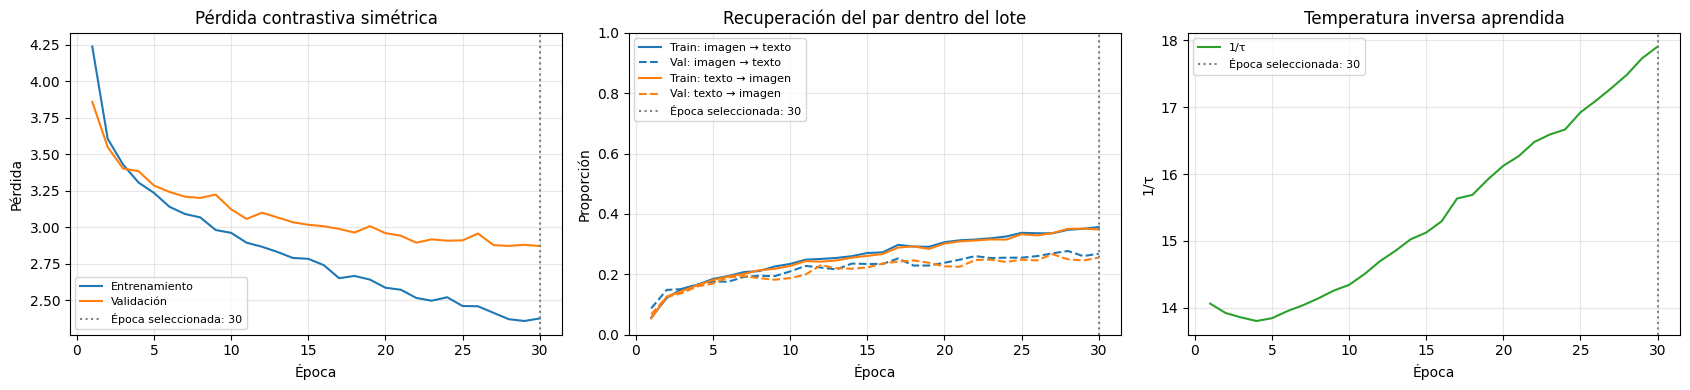

In [ ]:
# ------------------------------------------------------------
# 1. PREPARAR EL EJE DE ÉPOCAS
# ------------------------------------------------------------
epochs_clip = np.arange(
    1,
    len(history_clip.epoch) + 1,
)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))


# ------------------------------------------------------------
# 2. MOSTRAR LA PÉRDIDA CONTRASTIVA
# ------------------------------------------------------------
axes[0].plot(
    epochs_clip,
    history_clip.history["loss"],
    label="Entrenamiento",
)
axes[0].plot(
    epochs_clip,
    history_clip.history["val_loss"],
    label="Validación",
)
axes[0].set_title("Pérdida contrastiva simétrica")
axes[0].set_ylabel("Pérdida")


# ------------------------------------------------------------
# 3. MOSTRAR LA RECUPERACIÓN DEL PAR EXACTO
# ------------------------------------------------------------
for metric, color, direction in [
    ("pair_i2t", "C0", "imagen → texto"),
    ("pair_t2i", "C1", "texto → imagen"),
]:
    axes[1].plot(
        epochs_clip,
        history_clip.history[metric],
        color=color,
        label=f"Train: {direction}",
    )
    axes[1].plot(
        epochs_clip,
        history_clip.history[f"val_{metric}"],
        color=color,
        linestyle="--",
        label=f"Val: {direction}",
    )

axes[1].set_title("Recuperación del par dentro del lote")
axes[1].set_ylabel("Proporción")
axes[1].set_ylim(0, 1)


# ------------------------------------------------------------
# 4. MOSTRAR LA TEMPERATURA INVERSA
# ------------------------------------------------------------
axes[2].plot(
    epochs_clip,
    history_clip.history["inv_tau"],
    label="1/τ",
    color="C2",
)
axes[2].set_title("Temperatura inversa aprendida")
axes[2].set_ylabel("1/τ")


# ------------------------------------------------------------
# 5. MARCAR LA ÉPOCA SELECCIONADA
# ------------------------------------------------------------
for ax in axes:
    ax.axvline(
        best_epoch_clip,
        color="gray",
        linestyle=":",
        label=f"Época seleccionada: {best_epoch_clip}",
    )
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Paso 55. Obtener representaciones de las imágenes y los textos de prueba

Utilizamos los encoders con los pesos restaurados después del entrenamiento
para representar todas las imágenes y sus diez descripciones en el espacio
compartido de 256 dimensiones.

Esta operación se realiza en modo inferencia, sin actualizar los pesos.
Incluimos todas las observaciones de prueba, sin descartar el último lote.

Conservamos la correspondencia entre cada descripción, su imagen y su especie.
Estas representaciones permitirán construir los prototipos textuales para
clasificación y evaluar posteriormente la recuperación entre modalidades.

In [ ]:
# ------------------------------------------------------------
# 1. RECUPERAR TODAS LAS ENTRADAS DE PRUEBA
# ------------------------------------------------------------
clip_test_data = clip_data["test"]

clip_test_labels = np.asarray(
    clip_test_data["labels"],
    dtype=np.int64,
)

clip_test_caption_ids = np.asarray(
    clip_test_data["caption_ids"],
    dtype=np.int64,
)

n_test_images, n_captions_per_image, sequence_length = (
    clip_test_caption_ids.shape
)

assert n_test_images == len(clip_test_labels)
assert sequence_length == CLIP_MAX_LEN

# Cada imagen tiene diez descripciones.
# Pasamos de (imágenes, descripciones, longitud)
# a (descripciones totales, longitud).
# El orden conserva juntas las descripciones de cada imagen.
clip_test_flat_ids = clip_test_caption_ids.reshape(
    -1,
    sequence_length,
)


# ------------------------------------------------------------
# 2. CODIFICAR TODAS LAS IMÁGENES
# ------------------------------------------------------------
# predict utiliza modo inferencia y procesa también
# el último lote, aunque tenga menos observaciones.
print("Codificando imágenes de prueba…")

clip_test_image_vectors = clip_model.image_encoder.predict(
    clip_test_data["embeddings"],
    batch_size=128,
    verbose=1,
)


# ------------------------------------------------------------
# 3. CODIFICAR LAS DIEZ DESCRIPCIONES DE CADA IMAGEN
# ------------------------------------------------------------
print("\nCodificando descripciones de prueba…")

clip_test_text_vectors = clip_model.text_encoder.predict(
    clip_test_flat_ids,
    batch_size=256,
    verbose=1,
)


# ------------------------------------------------------------
# 4. CONSERVAR LA CORRESPONDENCIA TEXTO–IMAGEN–ESPECIE
# ------------------------------------------------------------
# Ejemplo: las primeras diez descripciones corresponden
# a la imagen situada en la posición 0.
clip_test_caption_to_image = np.repeat(
    np.arange(n_test_images),
    n_captions_per_image,
)

# Cada descripción recibe la etiqueta de su imagen.
clip_test_caption_labels = np.repeat(
    clip_test_labels,
    n_captions_per_image,
)


# ------------------------------------------------------------
# 5. VERIFICAR FORMAS, VALORES Y NORMALIZACIÓN
# ------------------------------------------------------------
assert clip_test_image_vectors.shape == (
    n_test_images,
    CLIP_EMBED_DIM,
)

assert clip_test_text_vectors.shape == (
    n_test_images * n_captions_per_image,
    CLIP_EMBED_DIM,
)

for name, vectors in [
    ("Imágenes", clip_test_image_vectors),
    ("Textos", clip_test_text_vectors),
]:
    assert np.isfinite(vectors).all(), (
        f"{name}: se encontraron valores no finitos."
    )

    norms = np.linalg.norm(vectors, axis=1)

    np.testing.assert_allclose(
        norms,
        np.ones_like(norms),
        atol=1e-5,
        rtol=1e-5,
    )

    print(
        f"{name}: forma={vectors.shape} | "
        f"norma media={norms.mean():.6f}"
    )

assert len(np.unique(clip_test_labels)) == 50
assert len(clip_test_caption_labels) == len(clip_test_text_vectors)

print(
    "\nDescripciones por imagen:",
    n_captions_per_image,
)
print("Especies reservadas:", len(np.unique(clip_test_labels)))
print("✓ Representaciones de prueba preparadas sin actualizar pesos.")

Codificando imágenes de prueba…
24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step

Codificando descripciones de prueba…
116/116 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step
Imágenes: forma=(2966, 256) | norma media=1.000000
Textos: forma=(29660, 256) | norma media=1.000000

Descripciones por imagen: 10
Especies reservadas: 50
✓ Representaciones de prueba preparadas sin actualizar pesos.


### Paso 56. Clasificación zero-shot mediante prototipos textuales

Construimos un prototipo por especie promediando las representaciones de
todas sus descripciones y normalizando nuevamente el vector resultante.

Para clasificar cada imagen, calculamos su similitud coseno con los
50 prototipos. La especie cuyo prototipo tenga mayor similitud será
la predicción top-1. También verificamos si la especie correcta aparece
entre las cinco primeras posiciones.

Las especies evaluadas no participaron en el entrenamiento de las
proyecciones de este modelo. Sus descripciones se utilizan únicamente
para construir los prototipos durante la evaluación, sin actualizar pesos.

Este protocolo emplea todas las descripciones de las especies de prueba,
incluidas las asociadas a las propias imágenes evaluadas. Por tanto,
los resultados deben interpretarse bajo esta disponibilidad de información
textual, y no como clasificación basada exclusivamente en nombres de especies.

Como referencia, una selección uniforme entre 50 especies tiene una
probabilidad de acierto de 2 % en top-1 y de 10 % en top-5.

In [ ]:
# ------------------------------------------------------------
# 1. IDENTIFICAR LAS 50 ESPECIES CANDIDATAS
# ------------------------------------------------------------
# Conservamos las etiquetas originales del dataset:
# índices de 150 a 199, equivalentes a especies 151 a 200.
clip_candidate_labels = np.unique(clip_test_labels)

assert len(clip_candidate_labels) == 50

clip_class_prototypes = []
clip_prototype_rows = []


# ------------------------------------------------------------
# 2. CONSTRUIR UN PROTOTIPO TEXTUAL POR ESPECIE
# ------------------------------------------------------------
for species_label in clip_candidate_labels:

    # Seleccionar todas las descripciones de esta especie.
    species_mask = (
        clip_test_caption_labels == species_label
    )

    species_vectors = clip_test_text_vectors[species_mask]

    assert len(species_vectors) > 0

    # Promediar en el espacio compartido de 256 dimensiones.
    prototype = species_vectors.mean(axis=0)

    # El promedio de vectores unitarios no necesariamente
    # tiene norma 1. Por eso lo normalizamos nuevamente.
    prototype_norm = np.linalg.norm(prototype)

    assert np.isfinite(prototype_norm)
    assert prototype_norm > 0

    prototype = prototype / prototype_norm

    clip_class_prototypes.append(prototype)

    clip_prototype_rows.append({
        "label": int(species_label),
        "especie": class_names[int(species_label)],
        "imagenes": int(
            np.sum(clip_test_labels == species_label)
        ),
        "descripciones": int(species_mask.sum()),
    })

clip_class_prototypes = np.stack(
    clip_class_prototypes,
    axis=0,
).astype(np.float32)

clip_prototype_summary = pd.DataFrame(
    clip_prototype_rows
)

assert clip_class_prototypes.shape == (50, 256)
assert np.isfinite(clip_class_prototypes).all()

np.testing.assert_allclose(
    np.linalg.norm(clip_class_prototypes, axis=1),
    np.ones(50),
    atol=1e-5,
    rtol=1e-5,
)

print("Prototipos textuales:", clip_class_prototypes.shape)
display(clip_prototype_summary.head())


# ------------------------------------------------------------
# 3. CALCULAR SIMILITUDES IMAGEN–PROTOTIPO
# ------------------------------------------------------------
# Como ambos lados tienen norma 1, el producto punto
# equivale a la similitud coseno.
# Resultado: una puntuación por imagen y especie candidata.
clip_zero_shot_scores = (
    clip_test_image_vectors @ clip_class_prototypes.T
)

assert clip_zero_shot_scores.shape == (
    len(clip_test_labels),
    50,
)

# No necesitamos aplicar temperatura ni softmax:
# una escala positiva común no cambia el orden de candidatos.
clip_zero_shot_ranking = np.argsort(
    -clip_zero_shot_scores,
    axis=1,
    kind="stable",
)

# El ranking contiene posiciones entre 0 y 49.
# Las convertimos a las etiquetas originales de las especies.
clip_zero_shot_ranked_labels = clip_candidate_labels[
    clip_zero_shot_ranking
]

clip_zero_shot_predictions = (
    clip_zero_shot_ranked_labels[:, 0]
)


# ------------------------------------------------------------
# 4. EVALUAR TOP-1 Y TOP-5
# ------------------------------------------------------------
clip_zero_shot_top1 = np.mean(
    clip_zero_shot_predictions == clip_test_labels
)

clip_zero_shot_top5 = np.mean(
    np.any(
        clip_zero_shot_ranked_labels[:, :5]
        == clip_test_labels[:, None],
        axis=1,
    )
)

clip_zero_shot_results = pd.DataFrame([
    {
        "metodo": "Referencia uniforme",
        "top1": 1 / len(clip_candidate_labels),
        "top5": 5 / len(clip_candidate_labels),
    },
    {
        "metodo": "CLIP con prototipos textuales",
        "top1": float(clip_zero_shot_top1),
        "top5": float(clip_zero_shot_top5),
    },
]).set_index("metodo")

display(clip_zero_shot_results.round(4))

print("Imágenes evaluadas:", len(clip_test_labels))
print("Especies candidatas:", len(clip_candidate_labels))
print("✓ Clasificación zero-shot evaluada sin actualizar pesos.")

Prototipos textuales: (50, 256)


,label,especie,imagenes,descripciones
0,150,151.Black_capped_Vireo,51,510
1,151,152.Blue_headed_Vireo,60,600
2,152,153.Philadelphia_Vireo,59,590
3,153,154.Red_eyed_Vireo,60,600
4,154,155.Warbling_Vireo,60,600


,top1,top5
metodo,,
Referencia uniforme,0.0200,0.1000
CLIP con prototipos textuales,0.3419,0.7283


Imágenes evaluadas: 2966
Especies candidatas: 50
✓ Clasificación zero-shot evaluada sin actualizar pesos.


### Paso 57. Recuperación imagen–texto mediante precisión@10

Evaluamos ambas direcciones de búsqueda en el espacio compartido:

- Imagen → texto: recuperar descripciones entre los 29.660 textos de prueba.
- Texto → imagen: recuperar fotografías entre las 2.966 imágenes de prueba.

Definimos como relevante un resultado que pertenezca a la misma especie
que la consulta. La precisión@10 es la proporción de resultados relevantes
entre los diez primeros, promediada sobre todas las consultas.

Esta métrica evalúa correspondencia semántica por especie; no exige
recuperar la fotografía exacta asociada a una descripción.

Calculamos las similitudes por bloques para limitar el uso de memoria.
Utilizamos todas las observaciones de prueba, sin actualizar pesos.

In [ ]:
# ------------------------------------------------------------
# 1. DEFINIR PRECISIÓN@K ENTRE MODALIDADES
# ------------------------------------------------------------
def cross_modal_precision_at_k(
    query_vectors,
    gallery_vectors,
    query_labels,
    gallery_labels,
    k=10,
    block_size=128,
):
    query_vectors = np.asarray(
        query_vectors, dtype=np.float32
    )
    gallery_vectors = np.asarray(
        gallery_vectors, dtype=np.float32
    )
    query_labels = np.asarray(query_labels)
    gallery_labels = np.asarray(gallery_labels)

    # Verificar correspondencia entre vectores y etiquetas.
    assert query_vectors.ndim == gallery_vectors.ndim == 2
    assert query_vectors.shape[1] == gallery_vectors.shape[1]
    assert len(query_vectors) == len(query_labels)
    assert len(gallery_vectors) == len(gallery_labels)
    assert 1 <= k <= len(gallery_vectors)
    assert np.isfinite(query_vectors).all()
    assert np.isfinite(gallery_vectors).all()

    # Asegurar que el producto punto sea similitud coseno.
    query_norms = np.linalg.norm(
        query_vectors, axis=1, keepdims=True
    )
    gallery_norms = np.linalg.norm(
        gallery_vectors, axis=1, keepdims=True
    )

    assert (query_norms > 0).all()
    assert (gallery_norms > 0).all()

    query_vectors = query_vectors / query_norms
    gallery_vectors = gallery_vectors / gallery_norms

    precision_per_query = np.empty(
        len(query_vectors), dtype=np.float64
    )

    for start in range(0, len(query_vectors), block_size):
        end = min(start + block_size, len(query_vectors))

        # Comparar este bloque con toda la galería.
        similarities = (
            query_vectors[start:end] @ gallery_vectors.T
        )

        # Ordenar por similitud descendente.
        # El orden estable resuelve empates de forma reproducible.
        top_indices = np.argsort(
            -similarities,
            axis=1,
            kind="stable",
        )[:, :k]

        # Un resultado es relevante si comparte especie
        # con la consulta.
        relevant = (
            gallery_labels[top_indices]
            == query_labels[start:end, None]
        )

        # Cada consulta recibe un valor entre 0 y 1.
        precision_per_query[start:end] = (
            relevant.mean(axis=1)
        )

    return float(precision_per_query.mean()), precision_per_query


# ------------------------------------------------------------
# 2. RECUPERAR TEXTOS A PARTIR DE IMÁGENES
# ------------------------------------------------------------
print("Evaluando imagen → texto…")

clip_p10_i2t, clip_p10_i2t_per_query = (
    cross_modal_precision_at_k(
        query_vectors=clip_test_image_vectors,
        gallery_vectors=clip_test_text_vectors,
        query_labels=clip_test_labels,
        gallery_labels=clip_test_caption_labels,
        k=10,
    )
)


# ------------------------------------------------------------
# 3. RECUPERAR IMÁGENES A PARTIR DE TEXTOS
# ------------------------------------------------------------
print("Evaluando texto → imagen…")

clip_p10_t2i, clip_p10_t2i_per_query = (
    cross_modal_precision_at_k(
        query_vectors=clip_test_text_vectors,
        gallery_vectors=clip_test_image_vectors,
        query_labels=clip_test_caption_labels,
        gallery_labels=clip_test_labels,
        k=10,
    )
)


# ------------------------------------------------------------
# 4. MOSTRAR Y CONSERVAR LOS RESULTADOS
# ------------------------------------------------------------
clip_retrieval_results = pd.DataFrame([
    {
        "direccion": "Imagen → texto",
        "consultas": len(clip_test_image_vectors),
        "candidatos": len(clip_test_text_vectors),
        "precision@10": clip_p10_i2t,
    },
    {
        "direccion": "Texto → imagen",
        "consultas": len(clip_test_text_vectors),
        "candidatos": len(clip_test_image_vectors),
        "precision@10": clip_p10_t2i,
    },
]).set_index("direccion")

display(clip_retrieval_results.round(4))

print("Relevancia: coincidencia de especie.")
print("✓ Recuperación entre modalidades evaluada.")

Evaluando imagen → texto…
Evaluando texto → imagen…


,consultas,candidatos,precision@10
direccion,,,
Imagen → texto,2966,29660,0.1602
Texto → imagen,29660,2966,0.1331


Relevancia: coincidencia de especie.
✓ Recuperación entre modalidades evaluada.


### Paso 58. Búsqueda de imágenes mediante consultas textuales propias

Escribimos tres descripciones nuevas y las procesamos con el mismo
tokenizador, vocabulario y longitud máxima utilizados al entrenar.

El encoder textual transforma cada consulta en un vector del espacio
compartido. Después recuperamos las cinco fotografías de prueba con
mayor similitud coseno.

Las consultas se fijan antes de observar los resultados. Este análisis
es cualitativo: permite examinar qué características visuales recupera
el modelo, sin asignar una especie correcta a cada consulta.

Mostramos también las palabras fuera del vocabulario y cualquier
truncamiento, porque pueden afectar la interpretación de la búsqueda.
Las similitudes mostradas no son probabilidades.

,consulta,palabras,longitud_utilizada,truncada,fuera_del_vocabulario
0,a small yellow bird with black wings,7,7,False,Ninguna
1,a brown bird with a streaked breast,7,7,False,Ninguna
2,a blue bird with a white belly,7,7,False,Ninguna


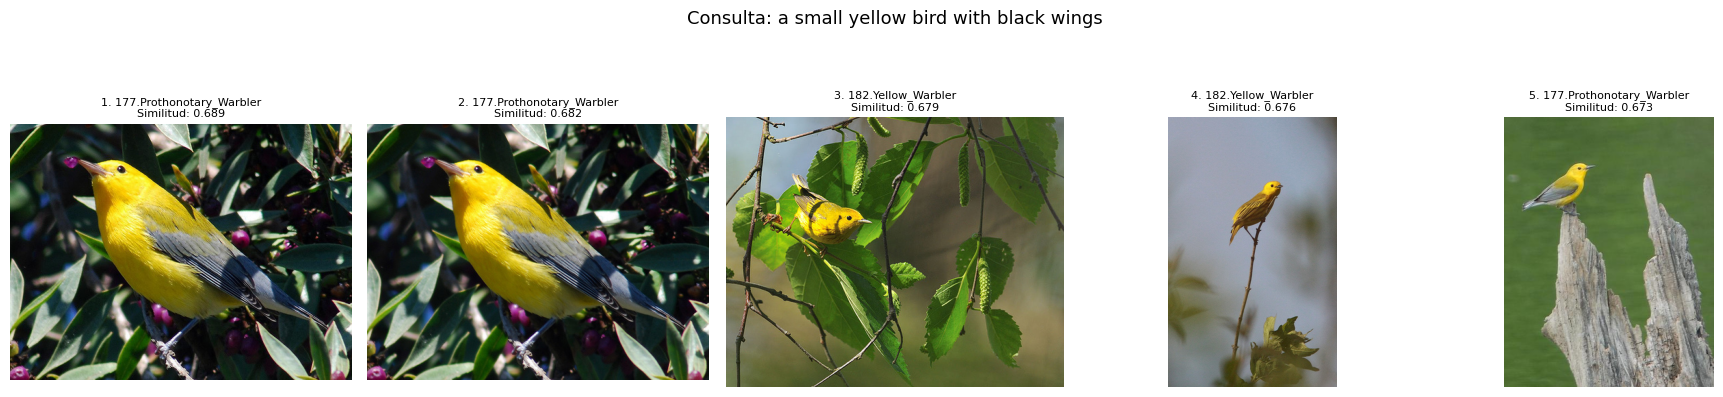

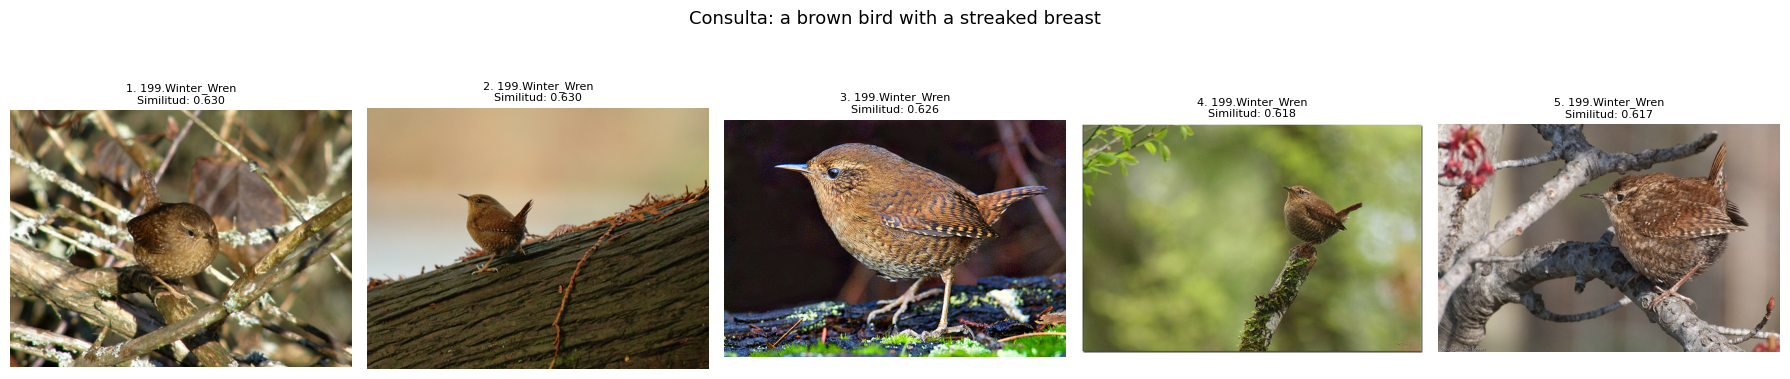

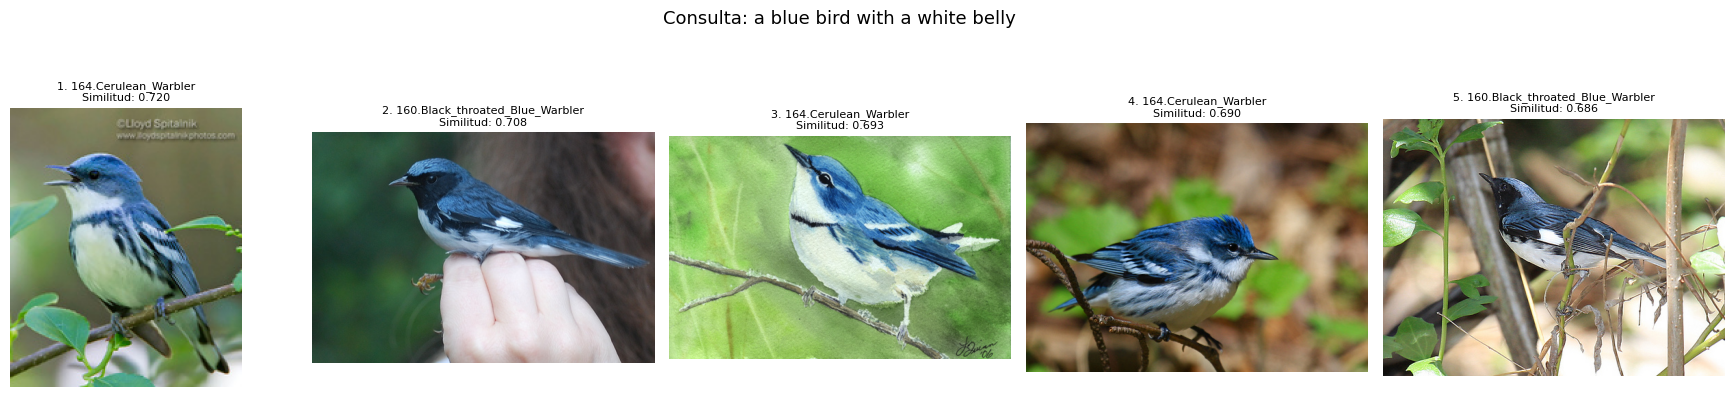

✓ Tres consultas evaluadas sobre la galería de prueba.


In [ ]:
# ------------------------------------------------------------
# 1. FIJAR TRES CONSULTAS NUEVAS
# ------------------------------------------------------------
# Las escribimos en inglés, como las descripciones de entrenamiento.
clip_custom_queries = [
    "a small yellow bird with black wings",
    "a brown bird with a streaked breast",
    "a blue bird with a white belly",
]


# ------------------------------------------------------------
# 2. CODIFICAR CON EL PREPROCESAMIENTO DEL ENTRENAMIENTO
# ------------------------------------------------------------
query_sequences = []
query_diagnostics = []

for query in clip_custom_queries:
    tokens = clip_tokenize(query)

    # Identificar palabras que se representarán como <unk>.
    unknown_words = [
        token for token in tokens
        if token not in clip_vocab
    ]

    # Truncar y rellenar con el mismo criterio del entrenamiento.
    token_ids = [
        clip_vocab.get(token, clip_vocab["<unk>"])
        for token in tokens
    ]

    if not token_ids:
        token_ids = [clip_vocab["<unk>"]]

    valid_length = min(len(token_ids), CLIP_MAX_LEN)

    sequence = np.full(
        CLIP_MAX_LEN,
        clip_vocab["<pad>"],
        dtype=np.int64,
    )
    sequence[:valid_length] = token_ids[:CLIP_MAX_LEN]

    query_sequences.append(sequence)

    query_diagnostics.append({
        "consulta": query,
        "palabras": len(tokens),
        "longitud_utilizada": valid_length,
        "truncada": len(tokens) > CLIP_MAX_LEN,
        "fuera_del_vocabulario": ", ".join(unknown_words) or "Ninguna",
    })

query_sequences = np.stack(query_sequences)

display(pd.DataFrame(query_diagnostics))


# ------------------------------------------------------------
# 3. OBTENER LOS VECTORES DE LAS CONSULTAS
# ------------------------------------------------------------
clip_query_vectors = clip_model.text_encoder.predict(
    query_sequences,
    verbose=0,
)

assert clip_query_vectors.shape == (3, CLIP_EMBED_DIM)
assert np.isfinite(clip_query_vectors).all()

# Normalizar ambos lados para calcular similitud coseno.
clip_query_vectors = clip_query_vectors / np.linalg.norm(
    clip_query_vectors,
    axis=1,
    keepdims=True,
)

gallery_vectors = clip_test_image_vectors / np.linalg.norm(
    clip_test_image_vectors,
    axis=1,
    keepdims=True,
)

clip_query_similarities = (
    clip_query_vectors @ gallery_vectors.T
)

clip_query_top5 = np.argsort(
    -clip_query_similarities,
    axis=1,
    kind="stable",
)[:, :5]


# ------------------------------------------------------------
# 4. MOSTRAR CINCO IMÁGENES POR CONSULTA
# ------------------------------------------------------------
from PIL import Image

clip_query_result_rows = []

for query_idx, query in enumerate(clip_custom_queries):
    fig, axes = plt.subplots(1, 5, figsize=(18, 4))
    fig.suptitle(f"Consulta: {query}", fontsize=13)

    for rank, image_idx in enumerate(
        clip_query_top5[query_idx],
        start=1,
    ):
        relative_path = str(
            clip_test_data["image_paths"][image_idx]
        )
        image_path = IMAGES_DIR / relative_path

        species_label = int(clip_test_labels[image_idx])
        species_name = class_names[species_label]
        similarity = float(
            clip_query_similarities[query_idx, image_idx]
        )

        # Mostrar la fotografía original como referencia visual.
        # La búsqueda utiliza los embeddings ya calculados.
        with Image.open(image_path) as source:
            image = source.convert("RGB")

        ax = axes[rank - 1]
        ax.imshow(image)
        ax.set_title(
            f"{rank}. {species_name}\n"
            f"Similitud: {similarity:.3f}",
            fontsize=8,
            wrap=True,
        )
        ax.axis("off")

        clip_query_result_rows.append({
            "consulta": query,
            "posicion": rank,
            "especie": species_name,
            "image_path": relative_path,
            "similitud_coseno": similarity,
        })

    plt.tight_layout(rect=[0, 0, 1, 0.90])
    plt.show()

clip_query_results = pd.DataFrame(clip_query_result_rows)

print("✓ Tres consultas evaluadas sobre la galería de prueba.")

### Paso 59. Visualizar las similitudes entre imágenes y textos de un lote

Tomamos un lote fijo de validación y calculamos la similitud coseno
entre cada imagen y cada descripción.

Cada fila representa una imagen y cada columna una descripción.
La diagonal contiene los pares originales imagen–texto; las demás
posiciones corresponden a combinaciones distintas.

Una diagonal con valores altos indica que el modelo reconoce los pares
originales. Sin embargo, otras posiciones también pueden mostrar
similitudes altas cuando las descripciones o las aves comparten rasgos.

Mostramos el lote completo y una ampliación de sus primeros 16 pares.
Esta visualización utiliza el modelo entrenado en modo inferencia,
sin modificar sus pesos.

Forma de la matriz: (128, 128)
Similitud media de los pares originales: 0.5228
Similitud media fuera de la diagonal: 0.1836


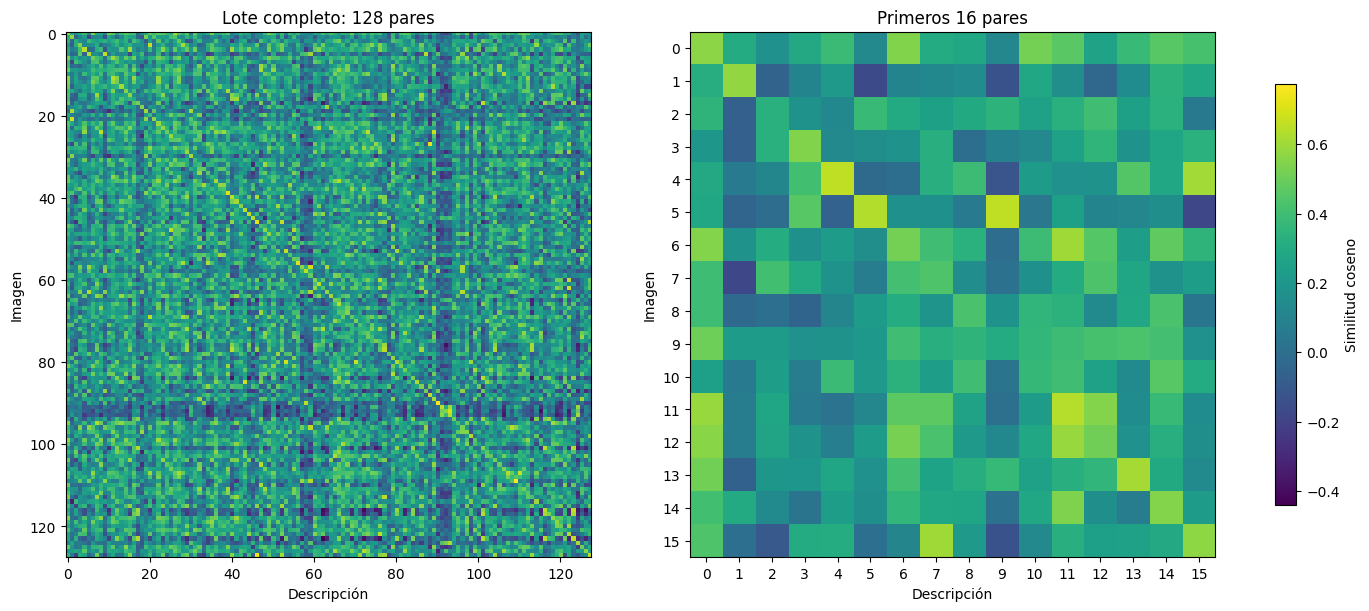

✓ Matriz de similitudes visualizada sin actualizar pesos.


In [ ]:
# ------------------------------------------------------------
# 1. RECUPERAR UN LOTE FIJO DE VALIDACIÓN
# ------------------------------------------------------------
# En validación utilizamos siempre la primera descripción.
clip_matrix_batch = next(iter(clip_val_ds))

# Obtener las representaciones con los pesos restaurados.
matrix_image_vectors, matrix_text_vectors = clip_model(
    clip_matrix_batch,
    training=False,
)

matrix_image_vectors = matrix_image_vectors.numpy()
matrix_text_vectors = matrix_text_vectors.numpy()


# ------------------------------------------------------------
# 2. CALCULAR LA MATRIZ DE SIMILITUD COSENO
# ------------------------------------------------------------
# Los encoders ya producen vectores con norma unitaria.
clip_batch_similarity = (
    matrix_image_vectors @ matrix_text_vectors.T
)

batch_n = len(matrix_image_vectors)

assert clip_batch_similarity.shape == (batch_n, batch_n)
assert np.isfinite(clip_batch_similarity).all()

# Comparar descriptivamente los pares originales
# con las demás combinaciones.
diagonal_mask = np.eye(batch_n, dtype=bool)

print("Forma de la matriz:", clip_batch_similarity.shape)
print(
    "Similitud media de los pares originales:",
    f"{clip_batch_similarity[diagonal_mask].mean():.4f}",
)
print(
    "Similitud media fuera de la diagonal:",
    f"{clip_batch_similarity[~diagonal_mask].mean():.4f}",
)


# ------------------------------------------------------------
# 3. MOSTRAR EL LOTE COMPLETO Y UNA AMPLIACIÓN
# ------------------------------------------------------------
# Compartimos la escala de color para comparar ambos paneles.
color_min = float(clip_batch_similarity.min())
color_max = float(clip_batch_similarity.max())

zoom_n = min(16, batch_n)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True,
)

axes[0].imshow(
    clip_batch_similarity,
    cmap="viridis",
    vmin=color_min,
    vmax=color_max,
    aspect="equal",
)
axes[0].set_title(f"Lote completo: {batch_n} pares")
axes[0].set_xlabel("Descripción")
axes[0].set_ylabel("Imagen")

zoom_plot = axes[1].imshow(
    clip_batch_similarity[:zoom_n, :zoom_n],
    cmap="viridis",
    vmin=color_min,
    vmax=color_max,
    aspect="equal",
)
axes[1].set_title(f"Primeros {zoom_n} pares")
axes[1].set_xlabel("Descripción")
axes[1].set_ylabel("Imagen")

axes[1].set_xticks(range(zoom_n))
axes[1].set_yticks(range(zoom_n))

fig.colorbar(
    zoom_plot,
    ax=axes,
    label="Similitud coseno",
    shrink=0.8,
)

plt.show()

print("✓ Matriz de similitudes visualizada sin actualizar pesos.")

Los pares originales imagen–texto presentan una similitud coseno media
de 0,5228, frente a 0,1836 para las combinaciones fuera de la diagonal.
Esta diferencia es consistente con el aprendizaje de correspondencias
entre ambas modalidades en el lote de validación.

Las combinaciones fuera de la diagonal no necesariamente carecen de
relación semántica: distintas fotografías y descripciones pueden compartir
especie o características visuales. Por ello, complementamos esta
visualización con las métricas de recuperación y clasificación sobre
las especies reservadas.

### Paso 60. Guardar modelos, configuraciones y resultados

Guardamos los clasificadores, los encoders siameses y los dos encoders
del modelo CLIP. También conservamos las tablas de resultados,
los historiales de entrenamiento y los vocabularios disponibles.

Para CLIP guardamos por separado los encoders y la temperatura aprendida.
Estos elementos permiten realizar inferencia posteriormente; no constituyen
un punto de restauración completo del optimizador para continuar el entrenamiento.

Finalmente, creamos y descargamos un archivo ZIP. La carpeta ubicada en
/content es temporal: debemos conservar el ZIP fuera del entorno de Colab.

In [ ]:
from pathlib import Path
import json
import shutil
import zipfile

import numpy as np
import pandas as pd
from google.colab import files


# ------------------------------------------------------------
# 1. CREAR LAS CARPETAS DE EXPORTACIÓN
# ------------------------------------------------------------
EXPORT_DIR = Path("/content/cub_taller2_resultados")

MODELS_DIR = EXPORT_DIR / "modelos"
TABLES_DIR = EXPORT_DIR / "tablas"
CONFIG_DIR = EXPORT_DIR / "configuracion"
PREDICTIONS_DIR = EXPORT_DIR / "predicciones"

for directory in [
    MODELS_DIR,
    TABLES_DIR,
    CONFIG_DIR,
    PREDICTIONS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

saved_files = []
unavailable_items = []


# ------------------------------------------------------------
# 2. DEFINIR FUNCIONES AUXILIARES
# ------------------------------------------------------------
# Convertir tipos de NumPy y rutas a tipos compatibles con JSON.
def json_compatible(value):
    if isinstance(value, dict):
        return {
            str(key): json_compatible(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [json_compatible(item) for item in value]

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    return value


def register_file(path):
    relative_path = str(path.relative_to(EXPORT_DIR))

    if relative_path not in saved_files:
        saved_files.append(relative_path)


def save_json(path, content):
    with path.open("w", encoding="utf-8") as file:
        json.dump(
            json_compatible(content),
            file,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        )

    register_file(path)


# ------------------------------------------------------------
# 3. RECUPERAR LA TEMPERATURA DE CLIP
# ------------------------------------------------------------
# scale es un método: debemos llamarlo con paréntesis.
# También admitimos una implementación donde sea un tensor.
scale_attribute = clip_model.scale

scale_value = (
    scale_attribute()
    if callable(scale_attribute)
    else scale_attribute
)

clip_inverse_temperature = float(
    np.asarray(scale_value.numpy())
)

assert np.isfinite(clip_inverse_temperature)
assert clip_inverse_temperature > 0

clip_temperature = 1.0 / clip_inverse_temperature

print(
    "Temperatura inversa:",
    f"{clip_inverse_temperature:.4f}",
)
print("Temperatura:", f"{clip_temperature:.4f}")


# ------------------------------------------------------------
# 4. GUARDAR LOS CLASIFICADORES
# ------------------------------------------------------------
# El formato .keras conserva arquitectura y pesos.
classifier_names = [
    "image_model",
    "text_model",
    "attribute_model",
    "early_fusion_model",
]

for name in classifier_names:
    model = globals().get(name)

    if model is None:
        unavailable_items.append(name)
        continue

    path = MODELS_DIR / f"{name}.keras"
    model.save(path)

    register_file(path)
    print("✓ Modelo guardado:", path.name)


# ------------------------------------------------------------
# 5. GUARDAR LOS ENCODERS SIAMESES
# ------------------------------------------------------------
# Exportamos los encoders para inferencia, sin el contenedor
# personalizado que calculaba las pérdidas de entrenamiento.
siamese_models = globals().get("siam_models", {})

if not siamese_models:
    unavailable_items.append("siam_models")

for name, model in siamese_models.items():
    path = MODELS_DIR / f"siamese_{name}.keras"

    model.encoder.save(path)
    register_file(path)

    print("✓ Encoder guardado:", path.name)


# ------------------------------------------------------------
# 6. GUARDAR LOS ENCODERS DE CLIP
# ------------------------------------------------------------
for name, encoder in [
    ("clip_image_encoder", clip_model.image_encoder),
    ("clip_text_encoder", clip_model.text_encoder),
]:
    path = MODELS_DIR / f"{name}.keras"

    encoder.save(path)
    register_file(path)

    print("✓ Encoder guardado:", path.name)


# ------------------------------------------------------------
# 7. GUARDAR CONFIGURACIONES Y VOCABULARIOS
# ------------------------------------------------------------
# Conservar la metadata de la preparación común, si está cargada.
if "metadata" in globals():
    save_json(
        CONFIG_DIR / "metadata_preparacion.json",
        metadata,
    )
else:
    unavailable_items.append("metadata")

# Conservar también el vocabulario original si esta variable
# está disponible en la sesión.
if "vocab" in globals():
    save_json(
        CONFIG_DIR / "vocabulario_clasificadores.json",
        vocab,
    )

save_json(
    CONFIG_DIR / "clip_config.json",
    {
        "vocabulario": clip_vocab,
        "max_len": CLIP_MAX_LEN,
        "embedding_dim": CLIP_EMBED_DIM,
        "pad_id": clip_vocab["<pad>"],
        "unk_id": clip_vocab["<unk>"],
        "tokenizacion": "minúsculas; expresión regular [a-z]+",
        "relleno": "derecha",
        "truncamiento": "conservar primeros max_len tokens",
        "temperatura_inversa": clip_inverse_temperature,
        "temperatura": clip_temperature,
        "mejor_epoca": int(best_epoch_clip),
        "especies_entrenamiento_originales": [1, 150],
        "especies_prueba_originales": [151, 200],
        "prototipos": (
            "Promedio de todas las descripciones de cada especie "
            "de prueba, normalizado nuevamente."
        ),
        "relevancia_precision_at_10": "misma especie",
    },
)

save_json(
    CONFIG_DIR / "experiment_config.json",
    {
        "seed": SEED,
        "tensorflow": tf.__version__,
        "numpy": np.__version__,
        "class_names": class_names,
        "backbone": "ResNet50 ImageNet congelada; average pooling",
        "preprocesamiento_visual": (
            "Recorte bbox con margen 0.10 por lado; "
            "resize 256x256; center crop 224x224; "
            "keras.applications.resnet50.preprocess_input"
        ),
        "late_fusion_seleccionada": globals().get(
            "best_late_rule"
        ),
        "siamese_seleccionada": globals().get(
            "best_siam_name"
        ),
        "siamese_especies_entrenamiento_originales": [1, 100],
        "siamese_especies_prueba_originales": [101, 200],
        "capa_personalizada_requerida": "L2Normalize",
    },
)

# Copiar el escalador de geometría y la configuración
# de extracción de embeddings, si existen.
for source in [
    PREPARED_DIR / "geometry_scaler.npz",
    PREPARED_DIR / "resnet50_embeddings" / "extraction_metadata.json",
]:
    if source.is_file():
        destination = CONFIG_DIR / source.name

        shutil.copy2(source, destination)
        register_file(destination)
    else:
        unavailable_items.append(str(source))


# ------------------------------------------------------------
# 8. GUARDAR TABLAS DE RESULTADOS
# ------------------------------------------------------------
# Si alguna tabla tiene otro nombre, lo informamos al final.
table_names = [
    "classification_results",
    "ablation_results",
    "robustness_text_results",
    "robustness_image_results",
    "siam_training_summary",
    "siam_val_results",
    "siam_test_results",
    "clip_zero_shot_results",
    "clip_retrieval_results",
    "clip_prototype_summary",
    "clip_query_results",
]

for name in table_names:
    table = globals().get(name)

    if isinstance(table, pd.DataFrame):
        path = TABLES_DIR / f"{name}.csv"

        table.to_csv(
            path,
            index=True,
            encoding="utf-8-sig",
        )
        register_file(path)
    else:
        unavailable_items.append(name)


# ------------------------------------------------------------
# 9. GUARDAR HISTORIALES DE ENTRENAMIENTO
# ------------------------------------------------------------
history_names = [
    "history_img",
    "history_text",
    "history_attribute",
    "history_early",
    "history_clip",
]

for name in history_names:
    history = globals().get(name)

    if history is not None and hasattr(history, "history"):
        save_json(
            CONFIG_DIR / f"{name}.json",
            history.history,
        )
    else:
        unavailable_items.append(name)

for name, history in globals().get("siam_histories", {}).items():
    history_values = (
        history.history
        if hasattr(history, "history")
        else history
    )

    save_json(
        CONFIG_DIR / f"history_siamese_{name}.json",
        history_values,
    )


# ------------------------------------------------------------
# 10. GUARDAR PREDICCIONES DE CLASIFICACIÓN
# ------------------------------------------------------------
prediction_names = [
    "y_test",
    "probs_img_test",
    "probs_text_test",
    "probs_attribute_test",
    "probs_early_test",
    "probs_late_test",
]

classification_arrays = {}

for name in prediction_names:
    if name in globals():
        array = np.asarray(globals()[name])

        # Evitar arreglos que requieran pickle al cargarse.
        if array.dtype.hasobject:
            raise TypeError(
                f"{name} contiene objetos y no puede exportarse "
                "como un arreglo numérico seguro."
            )

        classification_arrays[name] = array
    else:
        unavailable_items.append(name)

if classification_arrays:
    path = PREDICTIONS_DIR / "classification_predictions.npz"

    np.savez_compressed(
        path,
        **classification_arrays,
    )
    register_file(path)


# ------------------------------------------------------------
# 11. GUARDAR REPRESENTACIONES Y RESULTADOS DE CLIP
# ------------------------------------------------------------
# Mantener la correspondencia entre vectores, etiquetas,
# identificadores y rutas de las fotografías.
path = PREDICTIONS_DIR / "clip_test_representations.npz"

np.savez_compressed(
    path,
    image_vectors=clip_test_image_vectors,
    text_vectors=clip_test_text_vectors,
    image_labels=clip_test_labels,
    image_ids=np.asarray(
        clip_test_data["image_ids"],
        dtype=np.int64,
    ),
    image_paths=np.asarray(
        clip_test_data["image_paths"],
        dtype=str,
    ),
    caption_to_image=clip_test_caption_to_image,
    caption_labels=clip_test_caption_labels,
    candidate_labels=clip_candidate_labels,
    class_prototypes=clip_class_prototypes,
    zero_shot_scores=clip_zero_shot_scores,
    zero_shot_predictions=clip_zero_shot_predictions,
    precision10_i2t=clip_p10_i2t_per_query,
    precision10_t2i=clip_p10_t2i_per_query,
    batch_similarity=clip_batch_similarity,
)

register_file(path)


# ------------------------------------------------------------
# 12. GUARDAR REPRESENTACIONES SIAMESAS DISPONIBLES
# ------------------------------------------------------------
siamese_test_data = globals().get("siam_data", {}).get("test")

if siamese_test_data is not None:
    siamese_arrays = {
        "labels": np.asarray(
            siamese_test_data["labels"],
            dtype=np.int64,
        ),
        "image_ids": np.asarray(
            siamese_test_data["image_ids"],
            dtype=np.int64,
        ),
        "image_paths": np.asarray(
            siamese_test_data["image_paths"],
            dtype=str,
        ),
        "resnet50_embeddings": np.asarray(
            siamese_test_data["embeddings"],
            dtype=np.float32,
        ),
    }

    for name, vectors in globals().get(
        "siam_test_representations", {}
    ).items():
        siamese_arrays[f"encoder_{name}"] = np.asarray(
            vectors,
            dtype=np.float32,
        )

    path = PREDICTIONS_DIR / "siamese_test_representations.npz"

    np.savez_compressed(path, **siamese_arrays)
    register_file(path)


# ------------------------------------------------------------
# 13. ESCRIBIR INSTRUCCIONES DE RECUPERACIÓN
# ------------------------------------------------------------
readme = """EXPORTACIÓN DEL TALLER CUB MULTIMODAL

CONTENIDO
- modelos/: clasificadores y encoders en formato .keras.
- configuracion/: vocabularios, parámetros e historiales.
- tablas/: resultados en CSV.
- predicciones/: probabilidades y representaciones en NPZ.

CARGAR UN MODELO
    modelo = tf.keras.models.load_model(ruta, compile=False)

Antes de cargar los encoders, definir y registrar la capa
personalizada L2Normalize con el mismo código del taller.

CARGAR UN NPZ
    datos = np.load(ruta, allow_pickle=False)

ALCANCE
Los encoders CLIP y su temperatura permiten realizar inferencia.
No se exporta un checkpoint completo del optimizador CLIP para
continuar exactamente el entrenamiento.

Esta exportación no incluye las fotografías originales,
los archivos completos de preparación ni el notebook.

Conservar también:
- El notebook .ipynb ejecutado.
- El PDF del informe con figuras y resultados.
- Los archivos de preparación del primer taller.
- Las fotografías originales para visualizar recuperaciones.

Las figuras permanecen en el notebook; este ZIP no las exporta
automáticamente como archivos de imagen.
"""

readme_path = EXPORT_DIR / "LEEME.txt"
readme_path.write_text(readme, encoding="utf-8")

register_file(readme_path)


# ------------------------------------------------------------
# 14. GUARDAR EL INVENTARIO
# ------------------------------------------------------------
save_json(
    EXPORT_DIR / "inventario.json",
    {
        "archivos_guardados": saved_files.copy(),
        "elementos_no_disponibles": unavailable_items,
    },
)

if unavailable_items:
    print("\nElementos no encontrados; revisar:")
    for name in unavailable_items:
        print(" -", name)


# ------------------------------------------------------------
# 15. CREAR Y VERIFICAR EL ZIP
# ------------------------------------------------------------
zip_path = Path(
    shutil.make_archive(
        str(EXPORT_DIR),
        "zip",
        root_dir=EXPORT_DIR.parent,
        base_dir=EXPORT_DIR.name,
    )
)

# Leer y comprobar los archivos comprimidos.
with zipfile.ZipFile(zip_path) as archive:
    damaged_file = archive.testzip()

if damaged_file is not None:
    raise RuntimeError(
        f"Archivo dañado dentro del ZIP: {damaged_file}"
    )

print("\nArchivos guardados:", len(saved_files))
print("ZIP:", zip_path)
print(
    f"Tamaño: "
    f"{zip_path.stat().st_size / 1024**2:.1f} MiB"
)
print("✓ Exportación completada y ZIP verificado.")


# ------------------------------------------------------------
# 16. DESCARGAR EL ZIP AL COMPUTADOR
# ------------------------------------------------------------
files.download(str(zip_path))

Temperatura inversa: 17.9066
Temperatura: 0.0558
✓ Modelo guardado: image_model.keras
✓ Modelo guardado: text_model.keras
✓ Modelo guardado: attribute_model.keras
✓ Modelo guardado: early_fusion_model.keras
✓ Encoder guardado: siamese_contrastive_random.keras
✓ Encoder guardado: siamese_contrastive_hard.keras
✓ Encoder guardado: siamese_triplet_random.keras
✓ Encoder guardado: siamese_triplet_hard.keras
✓ Encoder guardado: clip_image_encoder.keras
✓ Encoder guardado: clip_text_encoder.keras

Archivos guardados: 41
ZIP: /content/cub_taller2_resultados.zip
Tamaño: 167.9 MiB
✓ Exportación completada y ZIP verificado.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

La exportación conservó los clasificadores, los cuatro encoders siameses,
los encoders de CLIP, las configuraciones, los vocabularios disponibles,
los historiales y los resultados.

El archivo comprimido pasó la verificación de integridad. Estos archivos
permiten recuperar los modelos para inferencia y reutilizar los resultados
sin repetir los entrenamientos. No constituyen un punto de restauración
completo del entrenamiento de CLIP.

Conservamos por separado el notebook ejecutado, las fotografías originales
y los archivos de preparación del primer taller.

# Respuestas a las preguntas de la Tarea 2


## Parte 1. Modelos unimodales

### Pregunta 1. ¿Qué modalidad rinde mejor por sí sola y por qué creen que ocurre?

La **imagen** fue la modalidad con mejor rendimiento individual en el conjunto de prueba de 5.794 observaciones, seguida de los **atributos tabulares** y, finalmente, del **texto**. Los resultados obtenidos fueron:

| Modalidad | Top-1 | Top-5 | F1-macro | ROC-AUC macro OvR |
|---|---:|---:|---:|---:|
| Imagen | 68,04 % | 91,27 % | 0,6806 | 0,9942 |
| Atributos | 50,07 % | 76,86 % | 0,4956 | 0,9757 |
| Texto | 23,37 % | 51,97 % | 0,2230 | 0,9346 |

Una posible explicación es que las características visuales proceden de **ResNet50 preentrenada en ImageNet**, cuyo backbone se mantuvo congelado. Estas representaciones ya contienen información visual útil acerca de formas, colores y texturas. En cambio, el modelo textual empleó **Embedding y LSTM entrenados desde cero**, y para cada observación de prueba recibió una sola descripción limitada a 25 tokens. El modelo tabular dispuso de **312 atributos anotados y seis características geométricas**, por lo que contó con información descriptiva estructurada, aunque menos rica que la representación visual en esta ejecución.

Estas diferencias de preentrenamiento y de información disponible impiden atribuir toda la ventaja de la imagen exclusivamente a su modalidad. Además, un ROC-AUC elevado no significa que el modelo alcance esa misma exactitud al elegir una entre 200 especies: para esta comparación son especialmente informativas las métricas top-1 y top-5.

### Pregunta 2. ¿Las especies que confunde la imagen son las mismas que confunde el texto? Muestren dos o tres ejemplos con su foto y caption.

**No son exactamente las mismas.** Al comparar las diez parejas de especies más confundidas por ambos clasificadores, solamente coincidieron **dos**: **American Crow–Fish Crow** y **Fish Crow–Common Raven**. Por ejemplo, entre las principales confusiones visuales aparecen también **Black-footed Albatross–Sooty Albatross** y **Acadian Flycatcher–Least Flycatcher**. En el modelo textual aparecen, entre otras, **Shiny Cowbird–Fish Crow** y **Eared Grebe–Horned Grebe**. Por tanto, hay dificultades compartidas, pero también errores específicos de cada modalidad.

Esta complementariedad se observa al comparar las predicciones para las mismas 5.794 observaciones: ambos modelos acertaron en **1.118 casos (19,30 %)**; solo la imagen acertó en **2.824 (48,74 %)**; solo el texto acertó en **236 (4,07 %)**; y ambos fallaron en **1.616 (27,89 %)**. Esos 236 aciertos exclusivos del texto muestran que, aunque su desempeño global es menor, puede aportar información útil cuando la imagen se equivoca.

La figura del notebook muestra **tres fotografías con sus captions originales codificadas y sus predicciones**:

1. **Solo acierta la imagen:** la especie real es *Black-footed Albatross*. Imagen predice *Black-footed Albatross*, mientras que texto predice *Whip-poor-will*. La caption es: “the bird has head and beak proportional to its body and the bird is brown in color”. Esta descripción es relativamente general y puede dificultar una identificación precisa por texto.
2. **Solo acierta el texto:** la especie real es *Black-footed Albatross*. Imagen predice *Sooty Albatross*, mientras que texto predice *Black-footed Albatross*. La caption es: “this bird is predominately grey with a large curved grey beak”. El ejemplo ilustra cómo el texto puede complementar una confusión visual entre especies semejantes.
3. **Fallan ambas modalidades:** la especie real es *Black-footed Albatross*. Imagen predice *Sooty Albatross* y texto predice *Heermann Gull*. La caption es: “light tan colored bird with a white head and an orange beak”. Este caso muestra que combinar información no elimina necesariamente los errores si ninguna de las dos representaciones resulta suficientemente discriminativa.

En conclusión, **las modalidades cometen errores parcialmente distintos**, lo que justifica probar métodos de fusión; sin embargo, esa complementariedad no garantiza que cualquier estrategia de fusión mejore los resultados.

## Parte 2. Early fusion

### Pregunta 3. ¿Mejora un único modelo que ve todas las modalidades a la vez?

**Sí, pero la mejora observada fue pequeña.** La arquitectura de *early fusion*, implementada como **fusión de características o intermediate fusion**, combinó una representación visual de 512 dimensiones, una representación textual LSTM de 256 dimensiones y una representación tabular de 128 dimensiones. Las tres ramas se concatenaron en **896 características** para entrenar conjuntamente una cabeza de clasificación de 200 especies con una sola pérdida. La extracción previa con ResNet50 permaneció congelada.

En prueba, la fusión obtuvo **68,38 % top-1**, **92,68 % top-5**, **F1-macro de 0,6837** y **ROC-AUC macro OvR de 0,9950**. Frente al clasificador de imagen (**68,04 % top-1** y **91,27 % top-5**), la mejora reportada en el notebook fue de aproximadamente **0,35 puntos porcentuales en top-1** y **1,42 puntos en top-5**.

El modelo restauró los pesos de la **época 7**, seleccionada por su menor pérdida de validación. Posteriormente, la pérdida de entrenamiento siguió disminuyendo sin una mejora sostenida de la validación, un patrón compatible con sobreajuste.

Por tanto, **incorporar simultáneamente las tres modalidades sí mejoró ligeramente la clasificación**, especialmente la probabilidad de incluir la especie correcta entre las cinco opciones principales. No obstante, la mejora top-1 es demasiado pequeña para afirmar que la fusión siempre será superior: solo se dispone de una ejecución y la arquitectura también cambia con respecto al clasificador visual.

## Parte 3. Late fusion, ablación y robustez

### Pregunta 4. ¿Basta con combinar las predicciones de los modelos unimodales? ¿Qué estrategia funcionó mejor?

En esta ejecución, **combinar las predicciones ya entrenadas fue más efectivo que fusionar internamente las características**. Se evaluaron dos reglas de *late fusion*, sin modificar los pesos de los clasificadores unimodales: **promedio de probabilidades** y **producto de probabilidades normalizado**. La regla se seleccionó exclusivamente a partir de validación, donde Producto consiguió **75,67 % top-1**, frente a **72,50 %** del Promedio.

Los resultados finales en prueba fueron:

| Modelo | Top-1 | Top-5 |
|---|---:|---:|
| Solo imagen | 68,04 % | 91,27 % |
| Solo texto | 23,37 % | 51,97 % |
| Solo atributos | 50,07 % | 76,86 % |
| Early fusion | 68,38 % | 92,68 % |
| Late fusion — Promedio | 73,47 % | 92,46 % |
| **Late fusion — Producto** | **76,30 %** | **94,96 %** |

La regla **Producto** consiguió también **F1-macro de 0,7637** y **ROC-AUC macro OvR de 0,9968**. Su ganancia en top-1 fue de **8,27 puntos porcentuales** respecto a imagen y de **7,92 puntos** frente a early fusion.

Una interpretación posible es que el producto favoreció especies respaldadas simultáneamente por diferentes modalidades, aprovechando errores complementarios. Sin embargo, esta regla puede perjudicar la predicción si algún clasificador asigna una probabilidad extremadamente baja a la especie correcta; por eso también es necesario evaluar su robustez.

### Pregunta 5. Según la ablación, ¿qué modalidad es imprescindible?

La **imagen fue la modalidad de mayor contribución** dentro de esta configuración de *late fusion*. Aplicando la regla Producto a las tres combinaciones de dos modalidades, se obtuvieron los siguientes resultados:

| Modalidades utilizadas | Top-1 | Top-5 | Caída top-1 respecto a tres modalidades |
|---|---:|---:|---:|
| Imagen + texto + atributos | 76,30 % | 94,96 % | — |
| Imagen + texto | 70,87 % | 92,44 % | 5,44 puntos |
| Imagen + atributos | 74,96 % | 94,25 % | 1,35 puntos |
| Texto + atributos | 54,88 % | 83,59 % | **21,42 puntos** |

Al retirar la imagen se produjo la mayor pérdida de exactitud, mientras que retirar texto generó la menor. Así, la imagen fue la fuente más importante para esta fusión. **No obstante, no es literalmente imprescindible en todos los sistemas**, ya que texto y atributos todavía alcanzaron 54,88 % top-1 sin ella. Además, el texto sí aportó una mejora incremental, pese a ser la modalidad unimodal menos precisa.

### Pregunta 6. ¿Qué tan robustas son early fusion y late fusion cuando una modalidad se degrada?

**La robustez dependió de cuál modalidad se alteró y de la severidad de la perturbación.** Al sustituir cada caption por una perteneciente a otra especie, el clasificador de texto descendió de **23,37 % a 0,36 % top-1**. *Early fusion* pasó de **68,38 % a 68,02 %** (caída de **0,36 puntos**), mientras que *late fusion* por Producto pasó de **76,30 % a 70,47 %** (caída de **5,83 puntos**). La menor sensibilidad de early fusion es compatible con una influencia limitada del texto, pero no demuestra que el modelo identifique descripciones incorrectas.

Para el ruido visual se añadieron perturbaciones gaussianas **a los píxeles de las imágenes**, con desviaciones estándar **σ = 0,10; 0,25; 0,50**, y **se recalcularon los embeddings de ResNet50**. No se añadió ruido directamente a los vectores precomputados.

| Ruido visual | Solo imagen top-1 | Early fusion top-1 | Late fusion Producto top-1 | Solo atributos top-1 |
|---|---:|---:|---:|---:|
| σ = 0 (sin ruido) | 68,04 % | 68,38 % | 76,30 % | 50,07 % |
| σ = 0,10 | 39,11 % | 44,94 % | 64,70 % | 50,07 % |
| σ = 0,25 | 6,39 % | 11,10 % | 40,18 % | 50,07 % |
| σ = 0,50 | 0,90 % | 1,73 % | 18,88 % | 50,07 % |

La regla Producto amortiguó mejor el ruido moderado que early fusion y el modelo de imagen, pero **no conservó su ventaja cuando la degradación fue intensa**. Desde σ = 0,25, el modelo de atributos intactos (50,07 %) superó a la combinación por Producto. En consecuencia, **tener más modalidades no garantiza mayor robustez**: una entrada fuertemente alterada puede perjudicar a la fusión si no existe un mecanismo que ajuste su confiabilidad.

## Parte 4. Red siamesa de imágenes

### Pregunta 7. ¿Qué pérdida y qué muestreo funcionaron mejor, y por qué?

La mejor configuración seleccionada mediante validación fue **pérdida triplet con selección de ejemplos difíciles (*batch-hard*)**. Se trabajó con las especies **1–100** para entrenamiento y validación, reservando las especies **101–200** para prueba. Cada lote incluyó **16 especies × 4 imágenes**, permitiendo comparar positivos y negativos dentro del mismo lote.

| Configuración | Recall@1 en validación | Recall@1 en especies no vistas |
|---|---:|---:|
| Contrastive + aleatorio | 46,51 % | 21,71 % |
| Contrastive + batch-hard | 64,74 % | 40,97 % |
| Triplet + aleatorio | 50,60 % | 41,10 % |
| **Triplet + batch-hard** | **65,76 %** | **42,18 %** |
| ResNet50 de referencia | 45,32 % | **49,75 %** |

En la validación, *batch-hard* mejoró los resultados para ambas pérdidas. Una posible explicación es que elegir **el positivo más lejano y el negativo más cercano** hace que el entrenamiento se concentre en comparaciones difíciles, relevantes para especies de aves visualmente similares. La pérdida triplet, por su parte, optimiza la relación entre ancla, positivo y negativo mediante un margen.

No obstante, **el resultado sobre especies no vistas matiza la conclusión**: triplet-hard alcanzó **42,18 % Recall@1** y **78,44 % Recall@8**, mientras que los embeddings originales de ResNet50 consiguieron **49,75 % Recall@1** y **84,91 % Recall@8**. Ninguna de las cuatro proyecciones aprendidas superó la referencia en prueba. Por tanto, triplet-hard fue la mejor **entre las configuraciones entrenadas**, pero no mejoró la transferencia a especies desconocidas frente a ResNet50. Esto podría relacionarse con una especialización a las especies conocidas, aunque la ejecución no permite aislar su causa.

### Pregunta 8. ¿En qué se diferencia una red siamesa de un clasificador de 200 clases? ¿Qué permite hacer que este último no puede?

Un clasificador convencional aprende una función que asigna cada imagen a **una de 200 clases fijas**. En cambio, la **red siamesa aprende una representación vectorial compartida** en la que imágenes de la misma especie deberían quedar próximas e imágenes de especies distintas, más separadas. Su objetivo no es producir directamente un logit por especie, sino aprender una **medida de similitud o distancia** entre fotografías.

Por eso puede evaluar especies que no participaron en el entrenamiento: una nueva fotografía se codifica y se compara con una **galería de imágenes de referencia** de esas especies mediante búsqueda de vecinos cercanos, sin necesidad de añadir una neurona de salida ni reentrenar un clasificador completo para cada especie nueva. También permite recuperación de imágenes semejantes y búsqueda de ejemplares relacionados.

En este notebook, esa capacidad se evaluó sobre las **100 especies reservadas (101–200)**. La visualización PCA de diez especies mostró agrupamientos y solapamientos parciales, pero la prueba decisiva de recuperación fue **Recall@K**: aunque la proyección triplet-hard concentró más varianza en dos componentes (40,6 %, frente a 18,4 % de ResNet50), no obtuvo mejores vecinos por especie que la referencia.

## Parte 5. Modelo tipo CLIP imagen–texto

### Pregunta 9. ¿Se pueden clasificar especies nunca vistas a partir de texto?

**Sí, en el protocolo zero-shot evaluado se obtuvo un desempeño superior al azar.** El modelo inspirado en CLIP aprendió un espacio común de **256 dimensiones** mediante dos encoders independientes: una proyección de los embeddings visuales de ResNet50 y un encoder textual **Embedding → LSTM → Dense**. Ambos se entrenaron con una **pérdida contrastiva simétrica imagen–texto**, sin utilizar la etiqueta de especie como objetivo de clasificación.

Se empleó la **partición alternativa permitida por el enunciado**, no la lista original de Reed: especies **1–150** para entrenamiento y validación, y especies **151–200** exclusivamente para evaluación. Para las 50 especies nuevas se construyó un prototipo textual mediante el promedio normalizado de sus captions y se clasificaron **2.966 imágenes** por similitud con esos prototipos.

| Evaluación zero-shot | Top-1 | Top-5 |
|---|---:|---:|
| Referencia uniforme (50 especies) | 2,00 % | 10,00 % |
| **CLIP con prototipos textuales** | **34,19 %** | **72,83 %** |

Este resultado muestra que la alineación imagen–texto aprendida es útil para reconocer categorías ausentes del entrenamiento de las proyecciones. **Sin embargo, el protocolo utiliza todas las captions disponibles de las especies de prueba, incluso las asociadas con las propias fotografías evaluadas**. Por ello, no equivale a clasificación usando solo el nombre de una especie o una descripción completamente independiente. Tampoco asegura que el backbone ResNet50, preentrenado en ImageNet, no tuviera información previa sobre aves similares.

### Pregunta 10. ¿Qué muestran la recuperación entre modalidades, las consultas propias y la matriz de similitudes?

En la recuperación cruzada se consideró relevante cualquier resultado que perteneciera a la **misma especie** de la consulta. Se obtuvo **precisión@10 de 16,02 %** para **imagen → texto** y de **13,31 %** para **texto → imagen**, evaluando galerías de 29.660 descripciones y 2.966 fotografías, respectivamente. Estos resultados indican que las representaciones contienen correspondencias semánticas, pero la recuperación de ejemplos individuales sigue siendo una tarea difícil.

Se probaron tres consultas nuevas que se muestran en el notebook junto con sus **cinco fotografías más similares**: “a small yellow bird with black wings”, “a brown bird with a streaked breast” y “a blue bird with a white belly”. Ninguna de las tres fue truncada ni contenía palabras fuera del vocabulario. La inspección cualitativa de las imágenes permite valorar la correspondencia entre las características escritas y las recuperadas, sin confundir similitud coseno con probabilidad de acierto.

Finalmente, la **matriz de similitudes de 128 × 128** del lote de validación obtuvo una similitud coseno promedio de **0,5228** en los pares imagen–caption originales y **0,1836** fuera de la diagonal. Esta diferencia respalda que los encoders aprendieron cierta alineación entre modalidades, aunque pueden existir semejanzas entre pares distintos que compartan especie o rasgos visuales.

Durante el entrenamiento, la temperatura inversa aprendida pasó de aproximadamente **14,29 a 17,91** (temperatura final **τ ≈ 0,0558**). La mejor pérdida de validación se alcanzó en la **época 30**, que era el máximo configurado; por tanto, **no es posible afirmar que el entrenamiento haya convergido completamente**.

## Conclusión general. ¿Qué gana un modelo al usar más de una modalidad y cómo conviene combinarlas?

En las **200 especies conocidas**, la combinación de predicciones mediante **late fusion por Producto** produjo el mejor resultado de clasificación de este notebook: **76,30 % top-1**, frente al **68,04 %** del modelo solo visual y el **68,38 %** de early fusion. Esto muestra que las distintas modalidades aportaron información complementaria, incluso cuando el texto tuvo el menor rendimiento de forma individual.

Sin embargo, la robustez demostró que **más modalidades no garantizan mejores resultados en cualquier condición**. Las predicciones combinadas sufrieron cuando el texto fue sustituido y, especialmente, cuando el ruido visual aumentó. En un escenario con una modalidad muy degradada, una estrategia que detecte o reduzca el peso de esa entrada podría ser preferible.

Por otra parte, la **red siamesa** y **CLIP** respondieron a objetivos distintos de la clasificación de 200 especies: aprender espacios de comparación para **especies reservadas**. La siamesa permitió medir semejanza entre imágenes nuevas, aunque su mejor encoder no superó la referencia ResNet50 en prueba. El modelo tipo CLIP sí consiguió clasificación zero-shot superior al azar utilizando descripciones textuales de las especies no vistas, dentro de las condiciones de evaluación especificadas.

En síntesis, **la estrategia de combinación debe elegirse según el objetivo, la calidad de cada modalidad y el protocolo de evaluación**, no solo por el número de fuentes de información disponibles. Estas conclusiones describen la ejecución documentada y requieren repetición con distintas semillas para valorar su estabilidad.


## Discusión final

### Clasificación de especies y aporte de las modalidades

Este taller permitió comparar diferentes estrategias de clasificación y aprendizaje de representaciones sobre CUB-200-2011. La identificación de especies constituye un problema de reconocimiento fino: las categorías pueden compartir características visuales y presentar diferencias sutiles en el plumaje, la forma o las proporciones corporales. Las anotaciones de imágenes, cajas delimitadoras y atributos de CUB permiten estudiar estas dificultades desde distintas fuentes de información (Wah et al., 2011). Las descripciones textuales complementan este contexto al expresar características visuales mediante lenguaje natural, como propusieron Reed et al. (2016).

Entre los clasificadores unimodales, el modelo visual obtuvo el mayor rendimiento: 68,04 % de exactitud top-1 y 91,27 % top-5. Le siguieron el clasificador de atributos, con 50,07 % y 76,86 %, y el textual, con 23,37 % y 51,97 %, respectivamente. Estos resultados sugieren que, bajo las condiciones implementadas, la representación visual conservó la mayor cantidad de información útil para discriminar especies.

Sin embargo, esta comparación no enfrenta modalidades en condiciones equivalentes de aprendizaje. El modelo visual utilizó representaciones de ResNet50 preentrenada en ImageNet, mientras que el embedding de palabras y la LSTM se entrenaron desde cero. ResNet se fundamenta en el aprendizaje residual para facilitar el entrenamiento de redes profundas (He et al., 2016). Por tanto, el desempeño observado refleja tanto las características de cada modalidad como las arquitecturas, el preentrenamiento y los recursos disponibles. No permite establecer una superioridad general de las imágenes sobre el lenguaje.

La información tabular también requiere una interpretación específica: sus 318 características incluyen 312 atributos visuales anotados y seis variables geométricas. Su rendimiento supone que estas anotaciones están disponibles durante la inferencia. Una aplicación práctica que únicamente reciba fotografías necesitaría obtener esa información mediante anotación adicional o mediante otros modelos.

### Complementariedad y estrategias de fusión

La fusión de representaciones, denominada *early fusion* en este taller, alcanzó 68,38 % top-1 y 92,68 % top-5. Frente al modelo visual, las mejoras fueron pequeñas: aproximadamente 0,35 y 1,42 puntos porcentuales, respectivamente. En consecuencia, la concatenación de las representaciones no produjo una ganancia amplia en esta ejecución. Esto no demuestra que la estrategia sea inadecuada en general, sino que su rendimiento depende de cómo se aprenden, equilibran y combinan las modalidades.

La fusión tardía por producto, seleccionada previamente con validación, obtuvo el mejor resultado de clasificación: 76,30 % top-1, 94,96 % top-5 y F1 macro de 0,7637. La mejora top-1 frente al modelo visual fue de aproximadamente 8,27 puntos porcentuales. Este resultado es consistente con la existencia de información complementaria entre los clasificadores, aunque no implica que sus errores sean independientes.

La ablación ayudó a examinar esa complementariedad. Retirar las imágenes produjo la mayor caída top-1, de 21,42 puntos porcentuales; retirar los atributos redujo el rendimiento en 5,44 puntos y retirar el texto, en 1,35 puntos. Estos valores describen la contribución de cada modalidad dentro de la combinación evaluada, no una importancia intrínseca e independiente de las demás.

En particular, el aporte del texto fue positivo pese a su menor desempeño unimodal. Esto muestra que una modalidad relativamente débil por separado puede resultar útil cuando proporciona información distinta de la disponible en los otros clasificadores.

### Robustez ante información incorrecta y ruido visual

Las pruebas de robustez mostraron que un mejor desempeño con datos originales no garantiza estabilidad ante entradas degradadas. Al sustituir las descripciones por textos de otras especies, la fusión tardía por producto perdió aproximadamente 5,83 puntos porcentuales top-1. La caída de la fusión de representaciones fue de alrededor de 0,36 puntos.

Esta menor sensibilidad de la fusión de representaciones es compatible con una dependencia limitada del texto, pero no demuestra por sí sola que el modelo detecte y descarte descripciones incorrectas. También podría reflejar que la modalidad visual domina sus decisiones.

El ruido visual produjo deterioros mayores. Con σ = 0,50, el clasificador visual descendió a 0,90 % top-1, la fusión de representaciones a 1,73 % y la fusión tardía por producto a 18,88 %. Esta última conservó una ventaja sobre los modelos que dependían fuertemente de la imagen, pero quedó por debajo del clasificador de atributos, que mantuvo 50,07 % al no modificarse su entrada.

Por tanto, agregar modalidades no garantiza superar a la mejor modalidad disponible bajo cualquier perturbación. Una fuente degradada puede perjudicar la combinación. Los resultados motivan explorar mecanismos de ponderación según confiabilidad, entrenamiento con modalidades ausentes y estrategias que permitan reducir la influencia de entradas poco informativas.

Estas pruebas representan perturbaciones controladas. El ruido gaussiano y la sustitución de descripciones no cubren todos los cambios posibles en aplicaciones reales, como desenfoque, oclusión, variaciones de iluminación o descripciones parcialmente incorrectas.

### Aprendizaje métrico y generalización a especies reservadas

La sección siamesa permitió estudiar un objetivo diferente de la clasificación convencional: aprender un espacio en el que imágenes de la misma especie se encuentren próximas y las de especies distintas se separen. Este propósito se relaciona con el aprendizaje mediante pérdidas contrastivas y de tripletes (Hadsell et al., 2006; Hermans et al., 2017).

La configuración con pérdida de tripletes y selección de ejemplos difíciles obtuvo el mayor recall@1 de validación, con 65,76 %. Sin embargo, en las especies reservadas alcanzó 42,18 %, por debajo del 49,75 % de la referencia ResNet50. Ninguna de las proyecciones entrenadas superó esta referencia en prueba.

Estos resultados sugieren que mejorar la organización del espacio para las especies utilizadas durante el entrenamiento no asegura transferir esa mejora a especies nuevas. Una explicación posible es que la proyección haya favorecido características discriminativas de las clases conocidas y reducido información útil para otras categorías. También pudieron influir la dimensionalidad de salida, los márgenes de las pérdidas y el procedimiento de muestreo. Los experimentos realizados no permiten aislar estas explicaciones.

La mayor proporción de varianza explicada por los dos primeros componentes principales del encoder tampoco constituye evidencia de mejor recuperación. La PCA describe la distribución de varianza en una proyección bidimensional; no evalúa directamente la correspondencia entre vecinos y especies. En este caso, las métricas de recuperación son la evidencia más pertinente para valorar el objetivo de aprendizaje métrico.

### Alineación imagen–texto y evaluación zero-shot

La última sección implementó un modelo inspirado en CLIP, con dos encoders y una pérdida contrastiva simétrica. CLIP propone aprender representaciones visuales mediante supervisión en lenguaje natural y transferirlas a tareas posteriores (Radford et al., 2021). Nuestra implementación fue una adaptación pedagógica: utilizó características visuales de ResNet50, un encoder textual con LSTM y un conjunto de entrenamiento considerablemente más acotado. No constituye una reproducción del entrenamiento original de CLIP.

Durante el entrenamiento disminuyó la pérdida de validación y aumentó la recuperación del par correcto dentro del lote. La mejor pérdida se obtuvo en la época 30, que coincidió con el límite establecido. Por ello, no puede afirmarse que el entrenamiento hubiera convergido o agotado sus posibilidades de mejora.

En las 50 especies reservadas, la clasificación mediante prototipos textuales alcanzó 34,19 % top-1 y 72,83 % top-5, frente a referencias uniformes de 2 % y 10 %. Estos resultados aportan evidencia de transferencia de la alineación imagen–texto a especies que no participaron en el entrenamiento de las proyecciones.

Esta interpretación tiene dos condiciones relevantes. Primero, los prototipos se construyeron con todas las descripciones de las especies de prueba, incluidas las asociadas a las propias imágenes evaluadas. Se trata, por tanto, de clasificación con información textual descriptiva disponible, y no únicamente con nombres de categorías. Segundo, la reserva de especies corresponde al entrenamiento realizado en este taller; no implica que el backbone preentrenado carezca de conocimientos visuales relacionados.

La recuperación entre modalidades obtuvo una precisión@10 de 16,02 % para imagen → texto y 13,31 % para texto → imagen, considerando relevante cualquier resultado de la misma especie. Estas métricas evalúan ejemplos individuales en galerías amplias y no son directamente comparables con la clasificación mediante prototipos, que agrega numerosas descripciones en un único vector por especie.

En el lote de validación visualizado, los pares originales presentaron una similitud media de 0,5228, frente a 0,1836 fuera de la diagonal. Esta separación es consistente con una asociación aprendida entre modalidades. Sin embargo, no equivale a una recuperación perfecta: distintas imágenes y descripciones pueden compartir características y recibir similitudes altas.

### Limitaciones y alcance de los resultados

Los resultados corresponden a una ejecución por configuración. No se estimó la variabilidad entre semillas ni se calcularon intervalos de confianza para las diferencias entre modelos. Por ello, las mejoras pequeñas, como la observada entre el clasificador visual y la fusión de representaciones, deben interpretarse con cautela.

Los protocolos también difieren entre secciones: la clasificación supervisada utiliza 200 especies, la evaluación siamesa reserva 100 especies y el experimento CLIP reserva 50. Sus métricas describen objetivos distintos y no deben organizarse en una única clasificación de modelos.

La extracción previa de embeddings facilitó los experimentos y redujo el costo computacional, pero mantuvo congelado el backbone y fijó el procesamiento visual utilizado para obtenerlos. Además, las evaluaciones métricas y zero-shot emplearon particiones secuenciales de especies; otras particiones podrían producir resultados diferentes.

Finalmente, el uso de cajas delimitadoras, atributos anotados y descripciones humanas proporciona información que puede no estar disponible automáticamente en una aplicación real. Los resultados deben entenderse dentro de ese contexto experimental.

### Relevancia pedagógica y trabajo futuro

El principal aporte pedagógico fue conectar la preparación de datos con diferentes objetivos de aprendizaje: clasificación supervisada, combinación de decisiones, aprendizaje métrico y alineación entre modalidades. El procedimiento permitió practicar la separación entre entrenamiento, validación y prueba; el ajuste del vocabulario y del escalamiento únicamente con entrenamiento; la selección de configuraciones mediante validación y la conservación de modelos y resultados.

La experiencia también mostró que una mejora en validación puede no transferirse a categorías nuevas, que una modalidad con bajo rendimiento individual puede complementar otras y que la robustez debe evaluarse explícitamente.

Como trabajo futuro, proponemos repetir los experimentos con varias semillas, evaluar diferentes particiones de especies y estudiar la calibración y ponderación de los clasificadores. Para el aprendizaje métrico, sería pertinente explorar estrategias de validación con especies distintas de las utilizadas para optimizar los pesos. Para el modelo inspirado en CLIP, podrían evaluarse pérdidas con múltiples positivos, dado que varias descripciones e imágenes de una misma especie pueden ser semánticamente compatibles aunque no formen el par original del lote.

En conjunto, los resultados permiten proponer que la utilidad de una estrategia multimodal depende de la complementariedad de sus fuentes, de la forma de combinarlas y de las condiciones de evaluación. El número de modalidades, por sí solo, no determina una mejor generalización.

## Referencias

Hadsell, R., Chopra, S., & LeCun, Y. (2006). Dimensionality reduction by learning an invariant mapping. En *2006 IEEE Computer Society Conference on Computer Vision and Pattern Recognition (CVPR’06)* (Vol. 2, pp. 1735–1742). IEEE. https://doi.org/10.1109/CVPR.2006.100

He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. En *2016 IEEE Conference on Computer Vision and Pattern Recognition (CVPR)* (pp. 770–778). IEEE. https://doi.org/10.1109/CVPR.2016.90

Hermans, A., Beyer, L., & Leibe, B. (2017). *In defense of the triplet loss for person re-identification* [Prepublicación]. arXiv. https://doi.org/10.48550/arXiv.1703.07737

Radford, A., Kim, J. W., Hallacy, C., Ramesh, A., Goh, G., Agarwal, S., Sastry, G., Askell, A., Mishkin, P., Clark, J., Krueger, G., & Sutskever, I. (2021). Learning transferable visual models from natural language supervision. En M. Meila & T. Zhang (Eds.), *Proceedings of the 38th International Conference on Machine Learning* (Vol. 139, pp. 8748–8763). PMLR. https://proceedings.mlr.press/v139/radford21a.html

Reed, S., Akata, Z., Lee, H., & Schiele, B. (2016). Learning deep representations of fine-grained visual descriptions. En *2016 IEEE Conference on Computer Vision and Pattern Recognition (CVPR)* (pp. 49–58). IEEE. https://doi.org/10.1109/CVPR.2016.13

Wah, C., Branson, S., Welinder, P., Perona, P., & Belongie, S. (2011). *The Caltech-UCSD Birds-200-2011 dataset* [Informe técnico]. California Institute of Technology. https://authors.library.caltech.edu/records/cvm3y-5hh21